# DAMO510 Take-Home Assignment 2
## Predictive Maintenance: Machine Failure Prediction

**Israel Obokohwo, NF1041893**
**Assigned random seed: 93**

AI4I 2020 Predictive Maintenance Dataset, UCI Machine Learning Repository (id 601).

---

The question I am trying to answer is whether torque, spindle speed, tool wear and the heat a machine is shedding reads while it is still running and if it gives enough warning that it is about to fail.

The section 2 pulls the raw file and resolves and questions of leakage before I model anything, because if I get that wrong then nothing after it means much. Section 4 makes the train/test split before I evaluate a single feature. Section 9 is the first time a model sees the test set. Section 10 picks the operating threshold from out-of-fold training predictions rather than from the test set, which costs a little on paper and is the honest way round. Nothing later in the notebook reaches back and changes anything earlier.

**On the seed.** `SEED = 93` The Last two digits of my student number `NF1041893` which is set once in section 1.2, and everything that could wander draws from it: the split, the cross-validation shuffling, every model's `random_state`, SMOTE, the permutation importance, and the ten alternative seeds in section 13. Running it again gives the same numbers.

---
# 1. Setup

Imports, the seed and paths, the small helpers I use everywhere, and the one factory that builds every model. Getting all of this out of the way early means the rest of the notebook can be focused on my analysis and modelling.

### 1.1 Imports

In [1]:
import io
import json
import platform
import sys
import time
import urllib.request
import warnings
import zipfile
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score,
                             confusion_matrix, f1_score, precision_score,
                             precision_recall_curve, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

%matplotlib inline

print("Python     :", sys.version.split()[0])
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
import sklearn, xgboost, imblearn
print("scikit-learn:", sklearn.__version__)
print("xgboost    :", xgboost.__version__)
print("imbalanced-learn:", imblearn.__version__)

Python     : 3.13.9
pandas     : 2.3.3
numpy      : 2.3.5
scikit-learn: 1.7.2
xgboost    : 3.4.1
imbalanced-learn: 0.14.0


### 1.2 Configuration and the assigned seed

`SEED = 93` is set here and nowhere else.

In [2]:
# ---------------------------------------------------------------------------
# CONFIGURATION
#
# Everything that could drift lives here so there is only one place to change
# it. SEED is the one that matters: every random step in this notebook traces
# back to it, and nothing below hard-codes a different value.
# ---------------------------------------------------------------------------

SEED = 93   # assigned analysis seed: split, CV shuffling, every model
            # random_state, SMOTE, permutation importance, robustness resampling

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_RAW   = ROOT / "data" / "raw"
DATA_PROC  = ROOT / "data" / "processed"
OUT        = ROOT / "outputs"
FIGS       = OUT / "figures"
TABLES     = OUT / "tables"
LOGS       = OUT / "logs"
STORE      = OUT / "store"
REPORT     = ROOT / "report"
NOTEBOOKS  = ROOT / "notebooks"

for _p in (DATA_RAW, DATA_PROC, OUT, FIGS, TABLES, LOGS, STORE, REPORT, NOTEBOOKS):
    _p.mkdir(parents=True, exist_ok=True)

RAW_CSV         = DATA_RAW / "ai4i2020_raw.csv"
MODEL_READY_CSV = DATA_PROC / "ai4i2020_model_ready.csv"

UCI_ZIP_URL = ("https://archive.ics.uci.edu/static/public/601/"
               "ai4i+2020+predictive+maintenance+dataset.zip")
UCI_DATASET_ID = 601
EXPECTED_SHAPE = (10000, 14)

# --- column names, as they appear in the untouched UCI file -----------------
TARGET             = "Machine failure"
ID_COLS            = ["UDI", "Product ID"]
FAILURE_FLAGS      = ["TWF", "HDF", "PWF", "OSF", "RNF"]
DETERMINISTIC_FLAGS = ["TWF", "HDF", "PWF", "OSF"]   # the four AI4I ORs together
CATEGORICAL        = ["Type"]
NUMERIC_RAW = ["Air temperature [K]", "Process temperature [K]",
               "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

RENAME = {
    "Air temperature [K]": "air_temp_K",
    "Process temperature [K]": "process_temp_K",
    "Rotational speed [rpm]": "rot_speed_rpm",
    "Torque [Nm]": "torque_Nm",
    "Tool wear [min]": "tool_wear_min",
    "Type": "type",
    "Machine failure": "machine_failure",
}
NUMERIC_CLEAN = ["air_temp_K", "process_temp_K", "rot_speed_rpm",
                 "torque_Nm", "tool_wear_min"]
CAT_CLEAN     = ["type"]
TARGET_CLEAN  = "machine_failure"
ENGINEERED    = ["power_W", "temp_diff_K", "wear_torque"]

# --- modelling constants ----------------------------------------------------
TEST_SIZE              = 0.20
CV_FOLDS               = 5
SELECTION_METRIC       = "average_precision"   # declared before any search runs
SELECTION_METRIC_LABEL = "PR-AUC (average precision)"

COST_FN    = 500.0   # assumed cost of one missed failure
COST_FP    = 50.0    # assumed cost of one false alarm
COST_RATIO = COST_FN / COST_FP

THRESHOLDS       = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
ROBUSTNESS_SEEDS = [93, 7, 21, 42, 55, 101, 202, 314, 777, 1234]
FIG_DPI          = 300

# colour-blind-safe pair used consistently: no failure / failure
C_OK    = "#4C78A8"
C_FAIL  = "#E45756"
PALETTE = ["#4C78A8", "#E45756", "#72B7B2", "#F58518", "#54A24B", "#B279A2"]

print("SEED =", SEED)
print("Selection metric:", SELECTION_METRIC_LABEL)
print("Project root:", ROOT)

SEED = 93
Selection metric: PR-AUC (average precision)
Project root: c:\Users\israe\Desktop\Predictive Take Home 2\DAMO510_A2


### 1.3 Shared helpers

`banner` prints a rule so the output stays skimmable. `save_table` writes a frame to `outputs/tables/` and prints it underneath, so every table I end up discussing is already on disk. `save_fig` does the same for figures at 300 dpi and shows them inline. `put` and `get` park the handful of results that a later section needs, which saves me recomputing a number three sections after I first worked it out.

In [3]:
# ---------------------------------------------------------------------------
# SHARED HELPERS
#
# save_table and save_fig exist so that anything I stop to look at also lands
# in outputs/ without me having to remember to save it.
#
# put and get park the few results a later section needs. put keeps them in
# memory for the rest of this run and writes them out as JSON so the write-up
# can read them afterwards; get answers from memory when it can, so nothing
# re-opens a file a cell above just wrote.
# ---------------------------------------------------------------------------

_STORE_MEM = {}


def banner(text):
    print("\n" + "=" * 78)
    print(text)
    print("=" * 78)


def save_table(df, name, index=False):
    """Write a table out to outputs/tables/ and print it under the cell."""
    path = TABLES / ("%s.csv" % name)
    df.to_csv(path, index=index)
    print("\n[table] %s" % path.name)
    print(df.to_string(index=index))
    return path


def save_fig(fig, name):
    """Save a figure to outputs/figures/ at 300 dpi and show it inline."""
    path = FIGS / ("%s.png" % name)
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    print("[figure] %s" % path.name)
    display(fig)
    return path


def put(key, value):
    """Park a result where later sections, and the write-up, can find it."""
    _STORE_MEM[key] = value
    with open(STORE / ("%s.json" % key), "w", encoding="utf-8") as fh:
        json.dump(value, fh, indent=2, default=str)


def get(key):
    """Fetch a parked result: from this run if I have it, otherwise from disk."""
    if key in _STORE_MEM:
        return json.loads(json.dumps(_STORE_MEM[key], default=str))
    with open(STORE / ("%s.json" % key), "r", encoding="utf-8") as fh:
        return json.load(fh)


def setup_matplotlib():
    """The house style for every figure, set once so they all match.

    Serif to sit alongside the report, and a fixed 300 dpi on save so the
    figures are print-quality without me thinking about it each time.
    """
    plt.rcParams.update({
        "figure.dpi": 110,
        "savefig.dpi": FIG_DPI,
        "font.family": "serif",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "legend.frameon": True,
        "figure.autolayout": False,
    })
    return plt, sns


sns.set_theme(style="whitegrid", context="notebook")
plt, sns = setup_matplotlib()
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
print("Helpers ready. Figures save to", FIGS)

Helpers ready. Figures save to c:\Users\israe\Desktop\Predictive Take Home 2\DAMO510_A2\outputs\figures


### 1.4 Preprocessing and the model factory

Every model gets built here rather than wherever it happens to be used. That is deliberate. The baseline, the parameter search, the imbalance comparison, the final evaluation and the robustness check all need to be fitting the same transformations on the same folds, and the only way I can be sure of that is if there is exactly one place that builds them.

In [4]:
# ---------------------------------------------------------------------------
# PREPROCESSING AND THE MODEL FACTORY
#
# One place that builds every pipeline. The baseline, the parameter search,
# the imbalance comparison, the evaluation and the robustness check all have
# to be fitting the same transformations on the same folds, and one factory is
# the only way I can be certain they are. Every transformer defined here gets
# fitted inside cross-validation, never on the full data.
# ---------------------------------------------------------------------------

MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]


def feature_columns(use_engineered=True):
    """Numeric and categorical predictor names for a given feature set."""
    numeric = list(NUMERIC_CLEAN)
    if use_engineered:
        numeric = numeric + list(ENGINEERED)
    return numeric, list(CAT_CLEAN)


def build_preprocessor(scale, use_engineered=True):
    """Common preprocessing for every model, plus the one model-specific step.

    Common to all four models
        median imputation on the numeric block (a safeguard for live sensor
        dropouts; the training file itself has no missing cells)
        one-hot encoding of the three-level product grade

    Model-specific
        standardisation, applied only when ``scale`` is True. Logistic
        regression needs it because its L2 penalty is scale sensitive. The
        three tree-based models split on order statistics, so scaling would
        change nothing except readability of the fitted objects.
    """
    numeric, categorical = feature_columns(use_engineered)
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(num_steps), numeric),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore",
                                  sparse_output=False), categorical),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def build_preprocessor_cols(numeric, categorical, scale):
    """The same design for an arbitrary column list, which the feature
    ablation and the robustness check both need."""
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(num_steps), list(numeric))]
    if categorical:
        transformers.append(
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore",
                                  sparse_output=False), list(categorical)))
    return ColumnTransformer(transformers=transformers, remainder="drop",
                             verbose_feature_names_out=False)


def expanded_feature_names(use_engineered=True):
    """Column names after the ColumnTransformer, in output order."""
    numeric, _ = feature_columns(use_engineered)
    # OneHotEncoder(drop='first') on Type with categories H, L, M keeps L and M
    return numeric + ["type_L", "type_M"]


def add_engineered(df):
    """Row-wise physical features. No cross-row statistic is used, so these can
    be computed before the split without leaking anything between folds."""
    out = df.copy()
    out["power_W"] = out["torque_Nm"] * out["rot_speed_rpm"] * 2 * np.pi / 60.0
    out["temp_diff_K"] = out["process_temp_K"] - out["air_temp_K"]
    out["wear_torque"] = out["tool_wear_min"] * out["torque_Nm"]
    return out


def confusion_counts(y_true, y_pred):
    """Return tn, fp, fn, tp as plain integers."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return int(tn), int(fp), int(fn), int(tp)


def score_row(name, y_true, y_pred, y_proba):
    """One row of the common evaluation framework used everywhere."""
    tn, fp, fn, tp = confusion_counts(y_true, y_pred)
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "f1": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "roc_auc": round(roc_auc_score(y_true, y_proba), 4),
        "pr_auc": round(average_precision_score(y_true, y_proba), 4),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }


def build_estimator(name, params, weighted=False, pos_weight=None, seed=None):
    """Rebuild one tuned model, optionally with its class-weighting switch on."""
    seed = SEED if seed is None else seed
    p = dict(params)
    if name == "Logistic Regression":
        if weighted:
            p["class_weight"] = "balanced"
        return LogisticRegression(max_iter=5000, random_state=seed, **p)
    if name == "Decision Tree":
        if weighted:
            p["class_weight"] = "balanced"
        return DecisionTreeClassifier(random_state=seed, **p)
    if name == "Random Forest":
        if weighted:
            p["class_weight"] = "balanced"
        return RandomForestClassifier(random_state=seed, n_jobs=-1, **p)
    if name == "XGBoost":
        if weighted:
            p["scale_pos_weight"] = pos_weight
        return XGBClassifier(random_state=seed, eval_metric="logloss",
                             n_jobs=-1, tree_method="hist", **p)
    raise ValueError(name)


def build_treated_pipeline(name, params, scale, treatment, pos_weight,
                           use_engineered=True, seed=None):
    """A full pipeline: preprocessing, the chosen imbalance treatment, the model."""
    seed = SEED if seed is None else seed
    pre = build_preprocessor(scale=scale, use_engineered=use_engineered)
    if treatment == "none":
        return Pipeline([("pre", pre),
                         ("clf", build_estimator(name, params, seed=seed))])
    if treatment == "class weighting":
        return Pipeline([("pre", pre),
                         ("clf", build_estimator(name, params, weighted=True,
                                                 pos_weight=pos_weight, seed=seed))])
    if treatment == "SMOTE":
        return ImbPipeline([("pre", pre),
                            ("smote", SMOTE(random_state=seed, k_neighbors=5)),
                            ("clf", build_estimator(name, params, seed=seed))])
    if treatment == "SMOTE + undersample":
        return ImbPipeline([("pre", pre),
                            ("smote", SMOTE(random_state=seed, k_neighbors=5,
                                            sampling_strategy=0.3)),
                            ("under", RandomUnderSampler(random_state=seed,
                                                         sampling_strategy=0.5)),
                            ("clf", build_estimator(name, params, seed=seed))])
    raise ValueError(treatment)


def build_final_models(use_engineered=True, seed=None):
    """Every model in its final form: tuned parameters plus retained treatment."""
    tuning = get("tuning")["chosen"]
    imb = get("imbalance")
    out = {}
    for name, cfg in tuning.items():
        out[name] = build_treated_pipeline(
            name, cfg["params"], cfg["scale"], imb["retained"][name],
            imb["pos_weight"], use_engineered=use_engineered, seed=seed)
    return out


print("Pipeline factory ready. Models:", ", ".join(MODEL_ORDER))

Pipeline factory ready. Models: Logistic Regression, Decision Tree, Random Forest, XGBoost


### 1.5 Passing results between sections

Later sections need frames that earlier sections built. These accessors hand them over, each returning a copy so that nothing downstream can quietly mutate an upstream result. Two of them read a file back off disk rather than reusing the variable in memory, and section 4 explains why that is on purpose.

In [5]:
# ---------------------------------------------------------------------------
# PASSING RESULTS BETWEEN SECTIONS
#
# Later sections need frames that earlier sections built. Each accessor hands
# one over as a copy, so nothing downstream can quietly mutate an upstream
# result, and each falls back to the file on disk if I have restarted the
# kernel and picked the notebook up part-way down.
# ---------------------------------------------------------------------------

RAW_DF = None          # set by section 2 after the raw file is loaded
MODEL_READY = None     # set by section 4 after the split is written
TEST_PROBS = None      # set by section 9 after the test set is scored
CV_RESULTS = {}        # per-model cv_results_ tables, filled by section 7


def read_raw():
    """The untouched UCI frame, as loaded in section 2."""
    if RAW_DF is None:
        return pd.read_csv(RAW_CSV)
    return RAW_DF.copy()


def read_model_ready():
    """The cleaned, engineered, split-labelled frame built in section 4."""
    if MODEL_READY is None:
        return pd.read_csv(MODEL_READY_CSV)
    return MODEL_READY.copy()


def read_test_probabilities():
    """Test-set predicted probabilities for all four models, from section 9."""
    if TEST_PROBS is None:
        return pd.read_csv(TABLES / "test_predicted_probabilities.csv")
    return TEST_PROBS.copy()


def load_model_ready(use_engineered=True):
    """X_train, X_test, y_train, y_test.

    The split column was written once in section 4 using SEED, so every later
    section sees the identical partition, in the identical row order.
    """
    df = read_model_ready()
    numeric, categorical = feature_columns(use_engineered)
    cols = numeric + categorical
    train = df[df["split"] == "train"]
    test = df[df["split"] == "test"]
    return (train[cols].copy(), test[cols].copy(),
            train[TARGET_CLEAN].to_numpy(), test[TARGET_CLEAN].to_numpy())


print("Hand-off accessors ready.")

Hand-off accessors ready.


---
# 2. Data audit and leakage assessment

Pull the untouched AI4I file from the UCI archive, keep a raw copy, then look at it properly before doing anything else: dimensions, types, target balance, missing values, duplicates, odd values, and which columns are identifiers rather than measurements.

The part that matters most is `TWF`, `HDF`, `PWF`, `OSF` and `RNF`. I could just assert those leak and drop them, but an assertion is not evidence, so I test the relationship against the target and let the counts decide. `RNF` turns out to behave differently from the other four and needs its own argument.

A loader for the raw file. It downloads from the UCI archive the first time and reads the cached copy after that, so a second run is offline and works from exactly the same bytes.

In [6]:
# ---------------------------------------------------------------- provenance
def fetch_raw() -> pd.DataFrame:
    """Primary route: the zipped CSV published on the UCI archive.
    Fallback: the ucimlrepo package, same dataset id 601."""
    if RAW_CSV.exists():
        print("Raw copy already on disk: " + str(RAW_CSV))
        return pd.read_csv(RAW_CSV)

    try:
        print("Downloading " + UCI_ZIP_URL)
        blob = urllib.request.urlopen(UCI_ZIP_URL, timeout=120).read()
        zf = zipfile.ZipFile(io.BytesIO(blob))
        member = [n for n in zf.namelist() if n.lower().endswith(".csv")][0]
        df = pd.read_csv(io.BytesIO(zf.read(member)))
        source = "UCI archive zip -> " + member
    except Exception as exc:                                   # pragma: no cover
        print("Direct download failed (%s: %s); using ucimlrepo." % (type(exc).__name__, exc))
        from ucimlrepo import fetch_ucirepo
        repo = fetch_ucirepo(id=UCI_DATASET_ID)
        df = repo.data.original.copy()
        df = df.rename(columns={
            "UID": "UDI",
            "Air temperature": "Air temperature [K]",
            "Process temperature": "Process temperature [K]",
            "Rotational speed": "Rotational speed [rpm]",
            "Torque": "Torque [Nm]",
            "Tool wear": "Tool wear [min]",
        })
        source = "ucimlrepo id=%d" % UCI_DATASET_ID

    df.to_csv(RAW_CSV, index=False)
    print("Source: " + source)
    print("Raw copy written untouched to " + str(RAW_CSV))
    return df

In [7]:
banner("STAGE 01  DATA AUDIT AND LEAKAGE ASSESSMENT")
print("Assigned seed for the whole project: SEED = %d" % SEED)

df = fetch_raw()


STAGE 01  DATA AUDIT AND LEAKAGE ASSESSMENT
Assigned seed for the whole project: SEED = 93
Raw copy already on disk: c:\Users\israe\Desktop\Predictive Take Home 2\DAMO510_A2\data\raw\ai4i2020_raw.csv


### Provenance proof

In [8]:
# -------------------------------------------------- provenance proof
banner("PROVENANCE PROOF")
print("Shape: %s" % (df.shape,))
print("Expected: %s" % (EXPECTED_SHAPE,))
assert df.shape == EXPECTED_SHAPE, "Dataset is not the original 10000 x 14 file"
print("\nColumns:")
for i, col in enumerate(df.columns, 1):
    print("  %2d. %s" % (i, col))
print("\nFirst three rows:")
print(df.head(3).to_string())


PROVENANCE PROOF
Shape: (10000, 14)
Expected: (10000, 14)

Columns:
   1. UDI
   2. Product ID
   3. Type
   4. Air temperature [K]
   5. Process temperature [K]
   6. Rotational speed [rpm]
   7. Torque [Nm]
   8. Tool wear [min]
   9. Machine failure
  10. TWF
  11. HDF
  12. PWF
  13. OSF
  14. RNF

First three rows:
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF
0    1     M14860    M                298.1                    308.6                    1551         42.8                0                0    0    0    0    0    0
1    2     L47181    L                298.2                    308.7                    1408         46.3                3                0    0    0    0    0    0
2    3     L47182    L                298.1                    308.5                    1498         49.4                5                0    0    0    0    0    0


### Variable dictionary and types

In [9]:
# -------------------------------------------------- variable dictionary
banner("VARIABLE DICTIONARY AND TYPES")
roles = {
    "UDI": "identifier",
    "Product ID": "identifier",
    "Type": "categorical predictor",
    "Air temperature [K]": "numeric predictor",
    "Process temperature [K]": "numeric predictor",
    "Rotational speed [rpm]": "numeric predictor",
    "Torque [Nm]": "numeric predictor",
    "Tool wear [min]": "numeric predictor",
    "Machine failure": "target",
    "TWF": "post-hoc failure-mode label (leakage)",
    "HDF": "post-hoc failure-mode label (leakage)",
    "PWF": "post-hoc failure-mode label (leakage)",
    "OSF": "post-hoc failure-mode label (leakage)",
    "RNF": "post-hoc failure-mode label (leakage)",
}
dic = pd.DataFrame({
    "variable": df.columns,
    "dtype": [str(t) for t in df.dtypes],
    "n_unique": [df[c].nunique() for c in df.columns],
    "n_missing": [int(df[c].isna().sum()) for c in df.columns],
    "pct_missing": [round(100 * df[c].isna().mean(), 3) for c in df.columns],
    "example_values": [
        ", ".join(map(str, df[c].dropna().unique()[:3])) for c in df.columns
    ],
    "assigned_role": [roles[c] for c in df.columns],
})
save_table(dic, "tbl01_variable_dictionary")


VARIABLE DICTIONARY AND TYPES

[table] tbl01_variable_dictionary.csv
               variable   dtype  n_unique  n_missing  pct_missing         example_values                         assigned_role
                    UDI   int64     10000          0          0.0                1, 2, 3                            identifier
             Product ID  object     10000          0          0.0 M14860, L47181, L47182                            identifier
                   Type  object         3          0          0.0                M, L, H                 categorical predictor
    Air temperature [K] float64        93          0          0.0    298.1, 298.2, 298.3                     numeric predictor
Process temperature [K] float64        82          0          0.0    308.6, 308.7, 308.5                     numeric predictor
 Rotational speed [rpm]   int64       941          0          0.0       1551, 1408, 1498                     numeric predictor
            Torque [Nm] float64       577

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl01_variable_dictionary.csv')

### Target distribution

In [10]:
# -------------------------------------------------- target distribution
banner("TARGET DISTRIBUTION")
counts = df[TARGET].value_counts().sort_index()
n_pos, n_neg = int(counts.get(1, 0)), int(counts.get(0, 0))
pos_rate = n_pos / len(df)
print("Machine failure = 0 : %5d  (%.2f%%)" % (n_neg, 100 * n_neg / len(df)))
print("Machine failure = 1 : %5d  (%.2f%%)" % (n_pos, 100 * pos_rate))
print("Imbalance ratio     : 1 failure per %.1f healthy records" % (n_neg / n_pos))
print("Majority-class accuracy floor: %.2f%%" % (100 * (1 - pos_rate)))


TARGET DISTRIBUTION
Machine failure = 0 :  9661  (96.61%)
Machine failure = 1 :   339  (3.39%)
Imbalance ratio     : 1 failure per 28.5 healthy records
Majority-class accuracy floor: 96.61%


### Data quality checks

In [11]:
# -------------------------------------------------- quality checks
banner("DATA QUALITY CHECKS")
print("Missing cells anywhere         : %d" % int(df.isna().sum().sum()))
dup_full = int(df.duplicated().sum())
dup_nokey = int(df.drop(columns=ID_COLS).duplicated().sum())
print("Fully duplicated rows          : %d" % dup_full)
print("Duplicates ignoring identifiers: %d" % dup_nokey)
print("UDI unique                     : %s (%d values)"
      % (df["UDI"].is_unique, df["UDI"].nunique()))
print("Product ID unique              : %s (%d values)"
      % (df["Product ID"].is_unique, df["Product ID"].nunique()))

# Product ID encodes Type in its first character: a subtle redundancy.
pid_prefix = df["Product ID"].str[0]
agree = float((pid_prefix == df["Type"]).mean())
print("\nProduct ID first character equals Type in %.2f%% of rows" % (100 * agree))
print("So Product ID is not merely an identifier, it silently repeats Type.")
print(pd.crosstab(pid_prefix, df["Type"]).to_string())


DATA QUALITY CHECKS
Missing cells anywhere         : 0
Fully duplicated rows          : 0
Duplicates ignoring identifiers: 0
UDI unique                     : True (10000 values)
Product ID unique              : True (10000 values)

Product ID first character equals Type in 100.00% of rows
So Product ID is not merely an identifier, it silently repeats Type.
Type           H     L     M
Product ID                  
H           1003     0     0
L              0  6000     0
M              0     0  2997


### Unusual or problematic values

In [12]:
# Unusual values: physical plausibility rather than blind outlier removal
banner("UNUSUAL OR PROBLEMATIC VALUES")
num = df[NUMERIC_RAW]
desc = num.describe().T
desc["skew"] = num.skew()
desc["kurtosis"] = num.kurtosis()
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
desc["n_iqr_outliers"] = [
    int(((num[c] < q1[c] - 1.5 * iqr[c]) | (num[c] > q3[c] + 1.5 * iqr[c])).sum())
    for c in num.columns
]
desc["n_nonpositive"] = [int((num[c] <= 0).sum()) for c in num.columns]
desc = desc.round(3).reset_index().rename(columns={"index": "variable"})
save_table(desc, "tbl02_numeric_quality")

neg_gap = int((df["Process temperature [K]"] - df["Air temperature [K]"] <= 0).sum())
print("\nRows where process temperature <= air temperature: %d" % neg_gap)
print("A negative gap would be physically impossible for a heated process, "
      "so this is a genuine validity check rather than a formality.")
zero_torque = int((df["Torque [Nm]"] <= 0).sum())
print("Rows with non-positive torque: %d" % zero_torque)
rs_hi = int((df["Rotational speed [rpm]"] > 2500).sum())
print("Rotational speed above 2500 rpm: %d (max %d rpm)"
      % (rs_hi, df["Rotational speed [rpm]"].max()))
print("High-speed readings sit in the right tail of a skewed but continuous "
      "distribution, so I keep them: they are operating states, not typos.")


UNUSUAL OR PROBLEMATIC VALUES

[table] tbl02_numeric_quality.csv
               variable   count     mean     std    min    25%    50%    75%    max   skew  kurtosis  n_iqr_outliers  n_nonpositive
    Air temperature [K] 10000.0  300.005   2.000  295.3  298.3  300.1  301.5  304.5  0.114    -0.836               0              0
Process temperature [K] 10000.0  310.006   1.484  305.7  308.8  310.1  311.1  313.8  0.015    -0.500               0              0
 Rotational speed [rpm] 10000.0 1538.776 179.284 1168.0 1423.0 1503.0 1612.0 2886.0  1.993     7.393             418              0
            Torque [Nm] 10000.0   39.987   9.969    3.8   33.2   40.1   46.8   76.6 -0.010    -0.013              69              0
        Tool wear [min] 10000.0  107.951  63.654    0.0   53.0  108.0  162.0  253.0  0.027    -1.167               0            120

Rows where process temperature <= air temperature: 0
A negative gap would be physically impossible for a heated process, so this is a genuine

### Leakage investigation: TWF, HDF, PWF, OSF, RNF

In [13]:
# -------------------------------------------------- LEAKAGE
banner("LEAKAGE INVESTIGATION: TWF, HDF, PWF, OSF, RNF")

flag_counts = pd.DataFrame({
    "flag": FAILURE_FLAGS,
    "n_fired": [int(df[f].sum()) for f in FAILURE_FLAGS],
    "pct_of_rows": [round(100 * df[f].mean(), 3) for f in FAILURE_FLAGS],
    "n_fired_and_failure": [
        int(((df[f] == 1) & (df[TARGET] == 1)).sum()) for f in FAILURE_FLAGS
    ],
    "n_fired_but_no_failure": [
        int(((df[f] == 1) & (df[TARGET] == 0)).sum()) for f in FAILURE_FLAGS
    ],
})
flag_counts["pct_fired_that_are_failures"] = (
    100 * flag_counts["n_fired_and_failure"] / flag_counts["n_fired"]
).round(2)
save_table(flag_counts, "tbl03_failure_flag_behaviour")

# Is Machine failure the OR of the four deterministic modes?
or4 = (df[DETERMINISTIC_FLAGS].sum(axis=1) > 0).astype(int)
or5 = (df[FAILURE_FLAGS].sum(axis=1) > 0).astype(int)

match4 = int((or4 == df[TARGET]).sum())
match5 = int((or5 == df[TARGET]).sum())
fp4 = int(((or4 == 1) & (df[TARGET] == 0)).sum())   # flag fires, target 0
fn4 = int(((or4 == 0) & (df[TARGET] == 1)).sum())   # target 1, no flag
fp5 = int(((or5 == 1) & (df[TARGET] == 0)).sum())
fn5 = int(((or5 == 0) & (df[TARGET] == 1)).sum())

print("OR(TWF,HDF,PWF,OSF) reproduces Machine failure on %d/%d rows (%.2f%%)"
      % (match4, len(df), 100 * match4 / len(df)))
print("   rows where the OR fires but the target is 0 : %d" % fp4)
print("   rows where the target is 1 but no mode fires: %d" % fn4)
print("OR(all five, RNF included) reproduces the target on %d/%d rows (%.2f%%)"
      % (match5, len(df), 100 * match5 / len(df)))
print("   rows where the OR fires but the target is 0 : %d" % fp5)
print("   rows where the target is 1 but no mode fires: %d" % fn5)

# RNF treated separately, because it behaves differently
rnf_n = int(df["RNF"].sum())
rnf_and_fail = int(((df["RNF"] == 1) & (df[TARGET] == 1)).sum())
rnf_only = int(((df["RNF"] == 1) &
                (df[DETERMINISTIC_FLAGS].sum(axis=1) == 0)).sum())
rnf_only_and_fail = int(((df["RNF"] == 1) &
                         (df[DETERMINISTIC_FLAGS].sum(axis=1) == 0) &
                         (df[TARGET] == 1)).sum())
print("\nRNF fires on %d rows; %d of those are labelled failures."
      % (rnf_n, rnf_and_fail))
print("RNF fires alone (no other mode) on %d rows; %d of those are labelled failures."
      % (rnf_only, rnf_only_and_fail))

# Which rows disagree, and why
amb = df[(or4 == 1) & (df[TARGET] == 0)]
unexp = df[(or4 == 0) & (df[TARGET] == 1)]
print("\nDisagreement rows where a mode fires but the target is 0: %d" % len(amb))
if len(amb):
    print(amb[ID_COLS + FAILURE_FLAGS + [TARGET]].to_string(index=False))
print("\nDisagreement rows where the target is 1 but no mode fires: %d" % len(unexp))
if len(unexp):
    print(unexp[ID_COLS + FAILURE_FLAGS + [TARGET]].to_string(index=False))

combo = (df.groupby(FAILURE_FLAGS, as_index=False)
           .agg(n_rows=(TARGET, "size"), n_failures=(TARGET, "sum")))
combo["failure_rate_pct"] = (100 * combo["n_failures"] / combo["n_rows"]).round(2)
combo = combo.sort_values("n_rows", ascending=False)
save_table(combo, "tbl04_flag_combination_crosstab")

leak_summary = pd.DataFrame({
    "check": [
        "OR(TWF,HDF,PWF,OSF) == Machine failure",
        "rows: mode fires, target = 0",
        "rows: target = 1, no mode fires",
        "OR(all five incl. RNF) == Machine failure",
        "RNF rows total",
        "RNF fires alone",
        "RNF fires alone and target = 1",
    ],
    "result": [
        "%d/%d rows (%.2f%%)" % (match4, len(df), 100 * match4 / len(df)),
        str(fp4), str(fn4),
        "%d/%d rows (%.2f%%)" % (match5, len(df), 100 * match5 / len(df)),
        str(rnf_n), str(rnf_only), str(rnf_only_and_fail),
    ],
})
save_table(leak_summary, "tbl05_leakage_summary")


LEAKAGE INVESTIGATION: TWF, HDF, PWF, OSF, RNF

[table] tbl03_failure_flag_behaviour.csv
flag  n_fired  pct_of_rows  n_fired_and_failure  n_fired_but_no_failure  pct_fired_that_are_failures
 TWF       46         0.46                   46                       0                       100.00
 HDF      115         1.15                  115                       0                       100.00
 PWF       95         0.95                   95                       0                       100.00
 OSF       98         0.98                   98                       0                       100.00
 RNF       19         0.19                    1                      18                         5.26


OR(TWF,HDF,PWF,OSF) reproduces Machine failure on 9991/10000 rows (99.91%)
   rows where the OR fires but the target is 0 : 0
   rows where the target is 1 but no mode fires: 9
OR(all five, RNF included) reproduces the target on 9973/10000 rows (99.73%)
   rows where the OR fires but the target is 0 : 18
   rows where the target is 1 but no mode fires: 9

RNF fires on 19 rows; 1 of those are labelled failures.
RNF fires alone (no other mode) on 18 rows; 0 of those are labelled failures.

Disagreement rows where a mode fires but the target is 0: 0

Disagreement rows where the target is 1 but no mode fires: 9
 UDI Product ID  TWF  HDF  PWF  OSF  RNF  Machine failure
1438     H30851    0    0    0    0    0                1
2750     M17609    0    0    0    0    0                1
4045     M18904    0    0    0    0    0                1
4685     M19544    0    0    0    0    0                1
5537     M20396    0    0    0    0    0                1
5942     L53121    0    0    0    0  

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl05_leakage_summary.csv')

### Inclusion decision

In [14]:
# -------------------------------------------------- inclusion decision
banner("INCLUSION DECISION")
decisions = pd.DataFrame([
    ("UDI", "Exclude", "Row counter 1 to 10000, unique on every row. Carries the "
     "sort order of the file and nothing about machine condition."),
    ("Product ID", "Exclude", "Quality letter plus serial number, 10000 unique "
     "values. Its first character duplicates Type, so it adds a redundant copy "
     "of a variable I already keep, plus thousands of useless levels."),
    ("Type", "Include", "Three-level product quality rating L/M/H, a genuine "
     "design characteristic known before the machine runs."),
    ("Air temperature [K]", "Include", "Ambient process condition, measured live."),
    ("Process temperature [K]", "Include", "Machine-side temperature, measured live."),
    ("Rotational speed [rpm]", "Include", "Live sensor reading."),
    ("Torque [Nm]", "Include", "Live sensor reading."),
    ("Tool wear [min]", "Include", "Cumulative minutes of tool use, known live."),
    ("TWF", "Exclude", "Tool-wear failure mode. Post-hoc label assigned after a "
     "failure is diagnosed; also part of the OR that defines the target."),
    ("HDF", "Exclude", "Heat-dissipation failure mode, same argument."),
    ("PWF", "Exclude", "Power failure mode, same argument."),
    ("OSF", "Exclude", "Overstrain failure mode, same argument."),
    ("RNF", "Exclude", "Random failure flag. Not part of the OR that defines the "
     "target and essentially unpredictable, so it is noise at prediction time."),
], columns=["variable", "decision", "reason"])
save_table(decisions, "tbl06_inclusion_decisions")

put("audit", {
    "n_rows": int(len(df)),
    "n_cols": int(df.shape[1]),
    "n_pos": n_pos,
    "n_neg": n_neg,
    "pos_rate_pct": round(100 * pos_rate, 2),
    "majority_accuracy_pct": round(100 * (1 - pos_rate), 2),
    "imbalance_ratio": round(n_neg / n_pos, 1),
    "n_missing": int(df.isna().sum().sum()),
    "dup_full": dup_full,
    "dup_nokey": dup_nokey,
    "udi_unique": int(df["UDI"].nunique()),
    "pid_unique": int(df["Product ID"].nunique()),
    "pid_type_agreement_pct": round(100 * agree, 2),
    "or4_match": match4,
    "or4_match_pct": round(100 * match4 / len(df), 2),
    "or4_flag_no_target": fp4,
    "or4_target_no_flag": fn4,
    "or5_match": match5,
    "or5_match_pct": round(100 * match5 / len(df), 2),
    "or5_flag_no_target": fp5,
    "or5_target_no_flag": fn5,
    "rnf_n": rnf_n,
    "rnf_and_fail": rnf_and_fail,
    "rnf_only": rnf_only,
    "rnf_only_and_fail": rnf_only_and_fail,
    "neg_temp_gap_rows": neg_gap,
    "n_iqr_out_speed": int(desc.loc[desc["variable"] == "Rotational speed [rpm]",
                                    "n_iqr_outliers"].iloc[0]),
    "n_iqr_out_torque": int(desc.loc[desc["variable"] == "Torque [Nm]",
                                     "n_iqr_outliers"].iloc[0]),
    "flag_counts": {f: int(df[f].sum()) for f in FAILURE_FLAGS},
    "flag_fail_counts": {
        f: int(((df[f] == 1) & (df[TARGET] == 1)).sum()) for f in FAILURE_FLAGS
    },
    "max_rot_speed": float(df["Rotational speed [rpm]"].max()),
    "min_rot_speed": float(df["Rotational speed [rpm]"].min()),
})
print("\nStage 01 complete.")


INCLUSION DECISION

[table] tbl06_inclusion_decisions.csv
               variable decision                                                                                                                                                                                   reason
                    UDI  Exclude                                                                     Row counter 1 to 10000, unique on every row. Carries the sort order of the file and nothing about machine condition.
             Product ID  Exclude Quality letter plus serial number, 10000 unique values. Its first character duplicates Type, so it adds a redundant copy of a variable I already keep, plus thousands of useless levels.
                   Type  Include                                                                                 Three-level product quality rating L/M/H, a genuine design characteristic known before the machine runs.
    Air temperature [K]  Include                                     

Keep the raw frame around. The next two sections want it and there is no reason to read the file a second time.

In [15]:
RAW_DF = df.copy()
print('Raw frame held in memory:', RAW_DF.shape)

Raw frame held in memory: (10000, 14)


---
# 3. Exploratory investigation

Six findings. Four of them involve more than one variable at a time, which turned out to be the important part: looked at one at a time these sensors are nearly flat, and everything interesting lives in the combinations.

I finish each finding with what it changes about the modelling. A finding I cannot act on is just a plot.

A loader that renames the sensor columns to something typable and adds the three derived quantities I want to look at. These get rebuilt properly inside the pipeline later; here they are only for exploring.

In [16]:
def load() -> pd.DataFrame:
    df = read_raw()
    df = df.rename(columns=RENAME)
    # Derived quantities used for exploration only; they are rebuilt inside the
    # modelling pipeline later so that nothing here leaks into the folds.
    df["temp_diff_K"] = df["process_temp_K"] - df["air_temp_K"]
    df["power_W"] = df["torque_Nm"] * df["rot_speed_rpm"] * 2 * np.pi / 60.0
    df["wear_torque"] = df["tool_wear_min"] * df["torque_Nm"]
    return df


STAGE 02  EXPLORATORY INVESTIGATION
Rows 10000, failures 339 (3.39%)


[figure] fig01_target_distribution.png


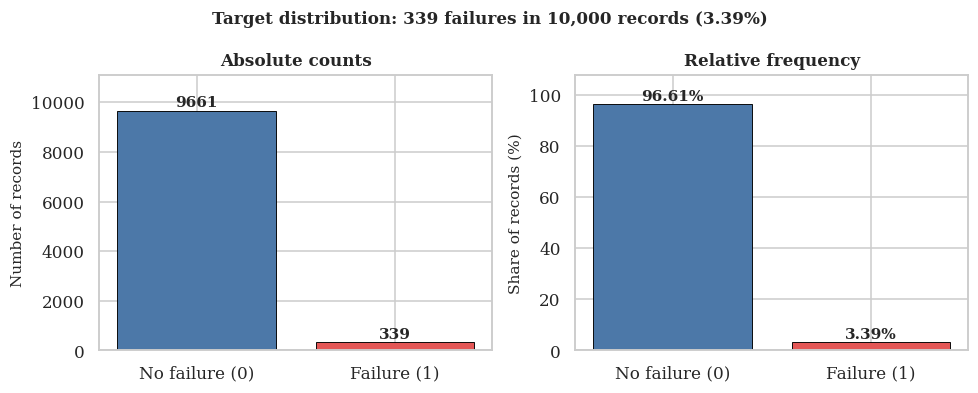

In [17]:
banner("STAGE 02  EXPLORATORY INVESTIGATION")
df = load()
fail = df[df[TARGET_CLEAN] == 1]
ok = df[df[TARGET_CLEAN] == 0]
n_fail = len(fail)
print("Rows %d, failures %d (%.2f%%)" % (len(df), n_fail, 100 * n_fail / len(df)))

results = {"n_fail": n_fail}

# ------------------------------------------------------------------
# Figure 1: target distribution
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
vc = df[TARGET_CLEAN].value_counts().sort_index()
axes[0].bar(["No failure (0)", "Failure (1)"], vc.values,
            color=[C_OK, C_FAIL], edgecolor="black", linewidth=0.6)
for i, v in enumerate(vc.values):
    axes[0].text(i, v + 150, "%d" % v, ha="center", fontweight="bold")
axes[0].set_ylabel("Number of records")
axes[0].set_title("Absolute counts")
axes[0].set_ylim(0, vc.max() * 1.15)

axes[1].bar(["No failure (0)", "Failure (1)"], 100 * vc.values / len(df),
            color=[C_OK, C_FAIL], edgecolor="black", linewidth=0.6)
for i, v in enumerate(100 * vc.values / len(df)):
    axes[1].text(i, v + 1.5, "%.2f%%" % v, ha="center", fontweight="bold")
axes[1].set_ylabel("Share of records (%)")
axes[1].set_title("Relative frequency")
axes[1].set_ylim(0, 108)
fig.suptitle("Target distribution: 339 failures in 10,000 records (3.39%)",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig01_target_distribution")
plt.close(fig)

### FINDING 1  Single-sensor separation is weak for every raw predictor


FINDING 1  Single-sensor separation is weak for every raw predictor

[table] tbl07_univariate_separation.csv
      variable  mean_no_failure  mean_failure  median_no_failure  median_failure  cohens_d  univariate_auc mannwhitney_p
     torque_Nm           39.630        50.168             39.900           53.70     1.077          0.7702      2.26e-64
 rot_speed_rpm         1540.260      1496.487           1507.000         1365.00    -0.244          0.2333      9.71e-63
       power_W         6244.548      7282.819           6243.046         7611.43     0.988          0.7457      1.65e-53
   wear_torque         4213.843      7187.938           3952.800         7681.80     1.072          0.7044      1.34e-37
   temp_diff_K           10.022         9.404              9.800            9.30    -0.621          0.3376       2.4e-24
 tool_wear_min          106.694       143.782            107.000          165.00     0.586          0.6621      2.92e-24
    air_temp_K          299.974       300.8

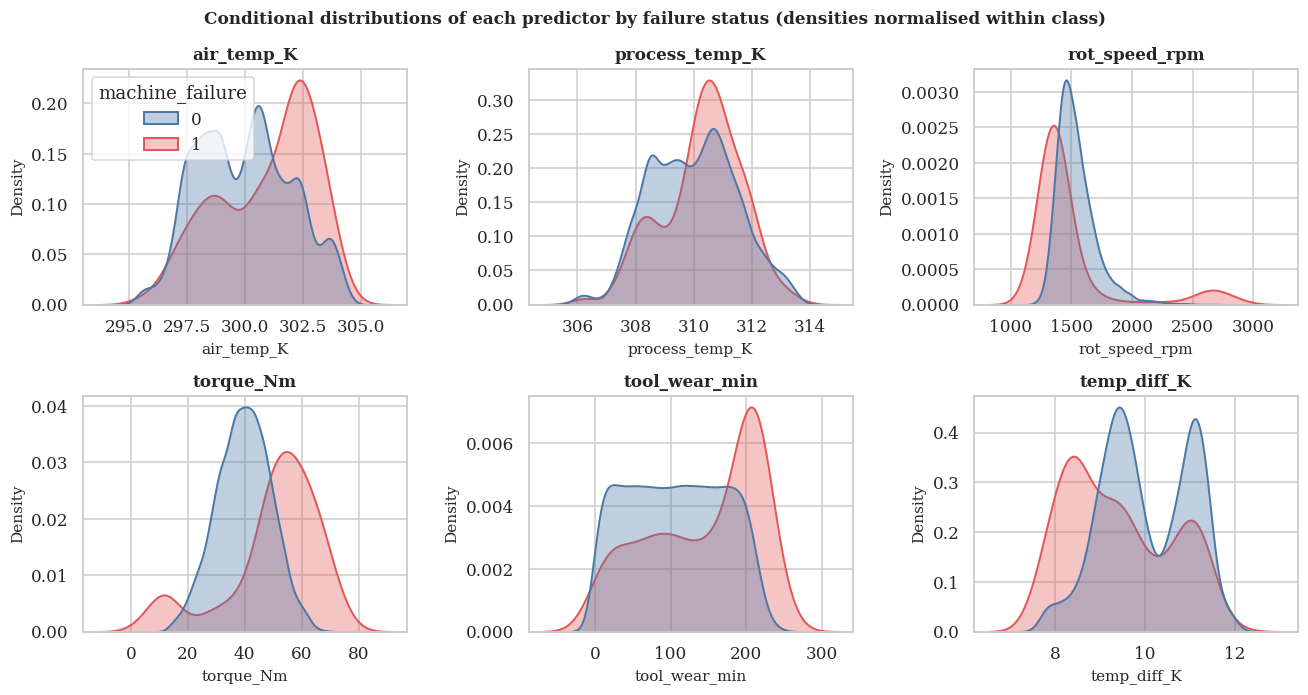

In [18]:
# ------------------------------------------------------------------
# FINDING 1 (univariate): which single sensors separate the classes
# ------------------------------------------------------------------
banner("FINDING 1  Single-sensor separation is weak for every raw predictor")
rows = []
for col in NUMERIC_CLEAN + ["temp_diff_K", "power_W", "wear_torque"]:
    a, b = ok[col], fail[col]
    u, p = stats.mannwhitneyu(b, a, alternative="two-sided")
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) /
                     (len(a) + len(b) - 2))
    d = (b.mean() - a.mean()) / pooled
    # single-variable ranking power
    auc = u / (len(a) * len(b))
    rows.append({
        "variable": col,
        "mean_no_failure": round(a.mean(), 3),
        "mean_failure": round(b.mean(), 3),
        "median_no_failure": round(a.median(), 3),
        "median_failure": round(b.median(), 3),
        "cohens_d": round(d, 3),
        "univariate_auc": round(auc, 4),
        "mannwhitney_p": ("%.3g" % p),
    })
sep = pd.DataFrame(rows).sort_values("univariate_auc",
                                     key=lambda s: (s - 0.5).abs(),
                                     ascending=False)
save_table(sep, "tbl07_univariate_separation")
best = sep.iloc[0]
print("\nStrongest single predictor: %s, AUC %.3f, Cohen's d %.2f"
      % (best["variable"], best["univariate_auc"], best["cohens_d"]))
print("Air and process temperature barely move between the classes "
      "(AUC near 0.5), so no single sensor is a usable alarm on its own.")
print("WHAT IT CHANGES: a single-threshold rule is not viable. The models "
      "have to combine sensors, which argues for keeping all five raw "
      "readings and for trying non-linear learners alongside logistic regression.")
results["best_univariate"] = {
    "variable": str(best["variable"]),
    "auc": float(best["univariate_auc"]),
    "d": float(best["cohens_d"]),
}
results["auc_air"] = float(sep.loc[sep["variable"] == "air_temp_K",
                                   "univariate_auc"].iloc[0])
results["auc_torque"] = float(sep.loc[sep["variable"] == "torque_Nm",
                                      "univariate_auc"].iloc[0])
results["auc_wear"] = float(sep.loc[sep["variable"] == "tool_wear_min",
                                    "univariate_auc"].iloc[0])
results["auc_power"] = float(sep.loc[sep["variable"] == "power_W",
                                     "univariate_auc"].iloc[0])
results["auc_tempdiff"] = float(sep.loc[sep["variable"] == "temp_diff_K",
                                        "univariate_auc"].iloc[0])
results["auc_weartorque"] = float(sep.loc[sep["variable"] == "wear_torque",
                                          "univariate_auc"].iloc[0])

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, col in zip(axes.ravel(), NUMERIC_CLEAN + ["temp_diff_K"]):
    sns.kdeplot(data=df, x=col, hue=TARGET_CLEAN, common_norm=False,
                fill=True, alpha=0.35, palette=[C_OK, C_FAIL],
                ax=ax, linewidth=1.3, legend=(col == NUMERIC_CLEAN[0]))
    ax.set_title(col)
    ax.set_ylabel("Density")
axes.ravel()[-1].set_visible(True)
fig.suptitle("Conditional distributions of each predictor by failure status "
             "(densities normalised within class)",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig02_conditional_distributions")
plt.close(fig)

### FINDING 2  Air and process temperature are near-collinear


FINDING 2  Air and process temperature are near-collinear

[table] tbl08_correlation_matrix.csv
       variable  air_temp_K  process_temp_K  rot_speed_rpm  torque_Nm  tool_wear_min  machine_failure
     air_temp_K       1.000           0.876          0.023     -0.014          0.014            0.083
 process_temp_K       0.876           1.000          0.019     -0.014          0.013            0.036
  rot_speed_rpm       0.023           0.019          1.000     -0.875          0.000           -0.044
      torque_Nm      -0.014          -0.014         -0.875      1.000         -0.003            0.191
  tool_wear_min       0.014           0.013          0.000     -0.003          1.000            0.105
machine_failure       0.083           0.036         -0.044      0.191          0.105            1.000

Pearson r(air, process) = 0.876
Pearson r(torque, rotational speed) = -0.875

[table] tbl09_multicollinearity_vif.csv
      variable  r_squared_on_others  VIF
    air_temp_K               

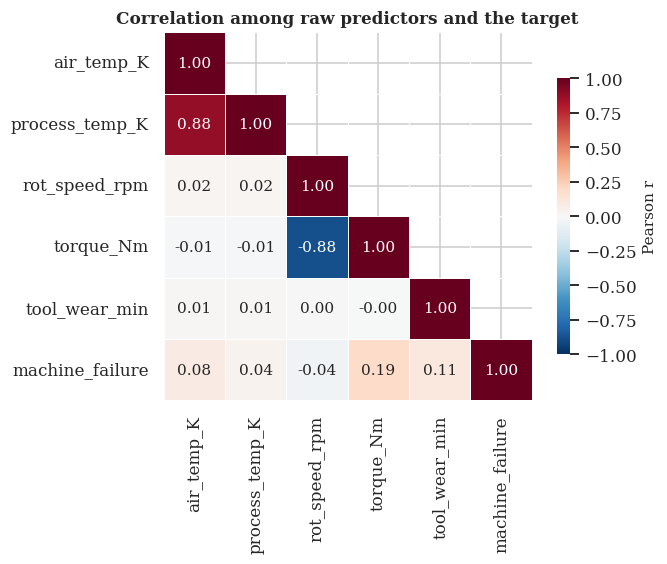

In [19]:
# ------------------------------------------------------------------
# FINDING 2 (multivariate): correlation structure
# ------------------------------------------------------------------
banner("FINDING 2  Air and process temperature are near-collinear")
corr = df[NUMERIC_CLEAN + [TARGET_CLEAN]].corr(method="pearson")
save_table(corr.round(3).reset_index().rename(columns={"index": "variable"}),
             "tbl08_correlation_matrix")
r_temp = corr.loc["air_temp_K", "process_temp_K"]
r_tq_rs = corr.loc["torque_Nm", "rot_speed_rpm"]
print("\nPearson r(air, process) = %.3f" % r_temp)
print("Pearson r(torque, rotational speed) = %.3f" % r_tq_rs)
vifs = []
Xn = df[NUMERIC_CLEAN].to_numpy(float)
for j, col in enumerate(NUMERIC_CLEAN):
    other = np.delete(Xn, j, axis=1)
    other = np.column_stack([np.ones(len(other)), other])
    beta, *_ = np.linalg.lstsq(other, Xn[:, j], rcond=None)
    resid = Xn[:, j] - other @ beta
    r2 = 1 - resid.var() / Xn[:, j].var()
    vifs.append({"variable": col, "r_squared_on_others": round(r2, 4),
                 "VIF": round(1 / (1 - r2), 2)})
vif_df = pd.DataFrame(vifs)
save_table(vif_df, "tbl09_multicollinearity_vif")
print("WHAT IT CHANGES: the two temperatures carry almost the same signal, "
      "so their logistic-regression coefficients will be unstable and hard "
      "to read. Replacing the pair with their difference is the sensible "
      "engineered response, and it is why regularisation stays switched on.")
results["r_air_process"] = round(float(r_temp), 3)
results["r_torque_speed"] = round(float(r_tq_rs), 3)
results["vif_air"] = float(vif_df.loc[vif_df["variable"] == "air_temp_K", "VIF"].iloc[0])
results["vif_process"] = float(vif_df.loc[vif_df["variable"] == "process_temp_K", "VIF"].iloc[0])

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.6,
            cbar_kws={"shrink": 0.75, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation among raw predictors and the target")
fig.tight_layout()
save_fig(fig, "fig03_correlation_heatmap")
plt.close(fig)

### FINDING 3  Failures sit in two opposite corners of the torque-speed plane


FINDING 3  Failures sit in two opposite corners of the torque-speed plane
Failures with torque >= 60 Nm and speed <= 1500 rpm : 100 of 339 (29.5%)
Failures with torque <= 25 Nm and speed >= 1800 rpm : 36 of 339 (10.6%)
The same two corners hold 139 and 593 healthy records respectively.
WHAT IT CHANGES: risk is high at both ends of the torque-speed trade-off and low in the middle. That is a non-monotonic pattern in the raw coordinates, which a linear decision boundary cannot express. It is the single strongest argument for the tree ensembles, and it tells me exactly which engineered feature to build.


[figure] fig04_torque_vs_speed.png


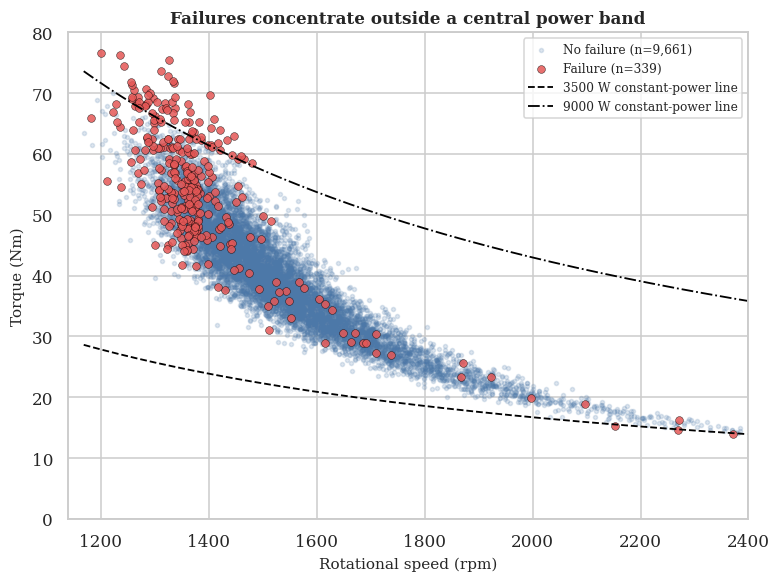


[table] tbl10_failure_rate_by_power_decile.csv
 power_decile    n  failures  power_min  power_max  failure_rate_pct
            1 1000        40     1148.4     4914.7               4.0
            2 1000         6     4915.0     5382.9               0.6
            3 1000         5     5383.0     5717.2               0.5
            4 1000         8     5718.1     6007.6               0.8
            5 1000        12     6008.1     6270.8               1.2
            6 1000         9     6271.2     6546.6               0.9
            7 1000        24     6546.6     6833.2               2.4
            8 1000        26     6833.4     7176.1               2.6
            9 1000        40     7176.5     7640.6               4.0
           10 1000       169     7640.6    10469.9              16.9

Failure rate, lowest power decile  : 4.00%
Failure rate, deciles 4 to 7 (middle): 1.32%
Failure rate, highest power decile : 16.90%
[figure] fig05_failure_rate_by_power_decile.png


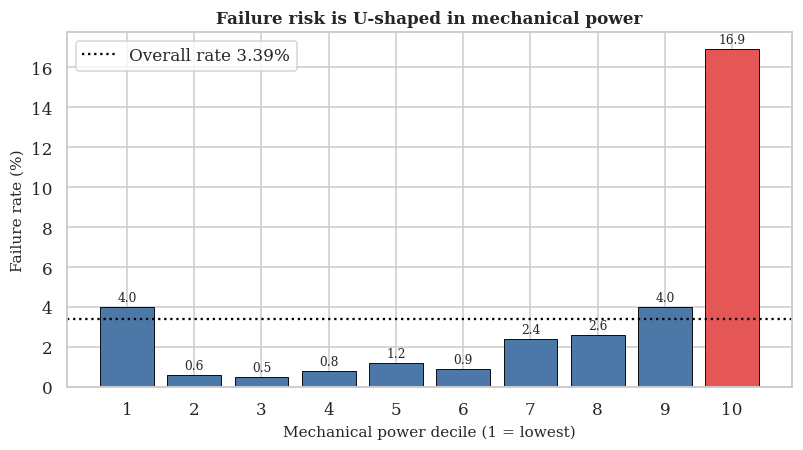

In [20]:
# ------------------------------------------------------------------
# FINDING 3 (multivariate): torque vs rotational speed
# ------------------------------------------------------------------
banner("FINDING 3  Failures sit in two opposite corners of the torque-speed plane")
hi_tq_lo_rs = int(((fail["torque_Nm"] >= 60) & (fail["rot_speed_rpm"] <= 1500)).sum())
lo_tq_hi_rs = int(((fail["torque_Nm"] <= 25) & (fail["rot_speed_rpm"] >= 1800)).sum())
print("Failures with torque >= 60 Nm and speed <= 1500 rpm : %d of %d (%.1f%%)"
      % (hi_tq_lo_rs, n_fail, 100 * hi_tq_lo_rs / n_fail))
print("Failures with torque <= 25 Nm and speed >= 1800 rpm : %d of %d (%.1f%%)"
      % (lo_tq_hi_rs, n_fail, 100 * lo_tq_hi_rs / n_fail))
base_hi = int(((ok["torque_Nm"] >= 60) & (ok["rot_speed_rpm"] <= 1500)).sum())
base_lo = int(((ok["torque_Nm"] <= 25) & (ok["rot_speed_rpm"] >= 1800)).sum())
print("The same two corners hold %d and %d healthy records respectively."
      % (base_hi, base_lo))
print("WHAT IT CHANGES: risk is high at both ends of the torque-speed "
      "trade-off and low in the middle. That is a non-monotonic pattern in "
      "the raw coordinates, which a linear decision boundary cannot express. "
      "It is the single strongest argument for the tree ensembles, and it "
      "tells me exactly which engineered feature to build.")
results["fail_hi_torque_lo_speed"] = hi_tq_lo_rs
results["fail_lo_torque_hi_speed"] = lo_tq_hi_rs
results["ok_hi_torque_lo_speed"] = base_hi
results["ok_lo_torque_hi_speed"] = base_lo

fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.scatter(ok["rot_speed_rpm"], ok["torque_Nm"], s=7, alpha=0.18,
           color=C_OK, label="No failure (n=9,661)", rasterized=True)
ax.scatter(fail["rot_speed_rpm"], fail["torque_Nm"], s=26, alpha=0.85,
           color=C_FAIL, edgecolor="black", linewidth=0.3,
           label="Failure (n=339)")
rs_grid = np.linspace(df["rot_speed_rpm"].min(), df["rot_speed_rpm"].max(), 300)
for pw, style in [(3500, "--"), (9000, "-.")]:
    ax.plot(rs_grid, pw / (rs_grid * 2 * np.pi / 60), style, color="black",
            linewidth=1.2, label="%d W constant-power line" % pw)
ax.set_xlim(df["rot_speed_rpm"].min() - 30, 2400)
ax.set_ylim(0, 80)
ax.set_xlabel("Rotational speed (rpm)")
ax.set_ylabel("Torque (Nm)")
ax.set_title("Failures concentrate outside a central power band")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig04_torque_vs_speed")
plt.close(fig)

# power decile failure rate: the U shape made explicit
df["power_decile"] = pd.qcut(df["power_W"], 10, labels=False) + 1
pw = (df.groupby("power_decile")
        .agg(n=("power_W", "size"),
             failures=(TARGET_CLEAN, "sum"),
             power_min=("power_W", "min"),
             power_max=("power_W", "max")))
pw["failure_rate_pct"] = (100 * pw["failures"] / pw["n"]).round(2)
pw = pw.round(1).reset_index()
save_table(pw, "tbl10_failure_rate_by_power_decile")
d1 = float(pw.loc[pw["power_decile"] == 1, "failure_rate_pct"].iloc[0])
d10 = float(pw.loc[pw["power_decile"] == 10, "failure_rate_pct"].iloc[0])
mid = float(pw.loc[pw["power_decile"].between(4, 7), "failures"].sum() /
            pw.loc[pw["power_decile"].between(4, 7), "n"].sum() * 100)
print("\nFailure rate, lowest power decile  : %.2f%%" % d1)
print("Failure rate, deciles 4 to 7 (middle): %.2f%%" % mid)
print("Failure rate, highest power decile : %.2f%%" % d10)
results["power_d1_rate"] = d1
results["power_d10_rate"] = d10
results["power_mid_rate"] = round(mid, 2)

fig, ax = plt.subplots(figsize=(7.4, 4.2))
bars = ax.bar(pw["power_decile"], pw["failure_rate_pct"],
              color=[C_FAIL if v > 5 else C_OK for v in pw["failure_rate_pct"]],
              edgecolor="black", linewidth=0.6)
for b, v in zip(bars, pw["failure_rate_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, "%.1f" % v,
            ha="center", fontsize=8)
ax.axhline(100 * n_fail / len(df), color="black", linestyle=":",
           label="Overall rate 3.39%")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Mechanical power decile (1 = lowest)")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Failure risk is U-shaped in mechanical power")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig05_failure_rate_by_power_decile")
plt.close(fig)

### FINDING 4  A small temperature gap is only dangerous at low speed


FINDING 4  A small temperature gap is only dangerous at low speed
gap < 8.6 K AND speed < 1380 rpm   n=  115  failures= 115  rate=100.00%
gap < 8.6 K only                   n=  605  failures=  11  rate=  1.82%
speed < 1380 rpm only              n= 1245  failures= 103  rate=  8.27%
neither                            n= 8035  failures= 110  rate=  1.37%

[table] tbl11_heat_dissipation_interaction.csv
                       condition  n_rows  n_failures  failure_rate_pct
gap < 8.6 K AND speed < 1380 rpm     115         115            100.00
                gap < 8.6 K only     605          11              1.82
           speed < 1380 rpm only    1245         103              8.27
                         neither    8035         110              1.37
WHAT IT CHANGES: neither condition alone is alarming, and together they are. An additive model has to approximate that with main effects it does not really have, so I expect logistic regression to lose recall here unless the interaction is ha

[figure] fig06_tempgap_vs_speed.png


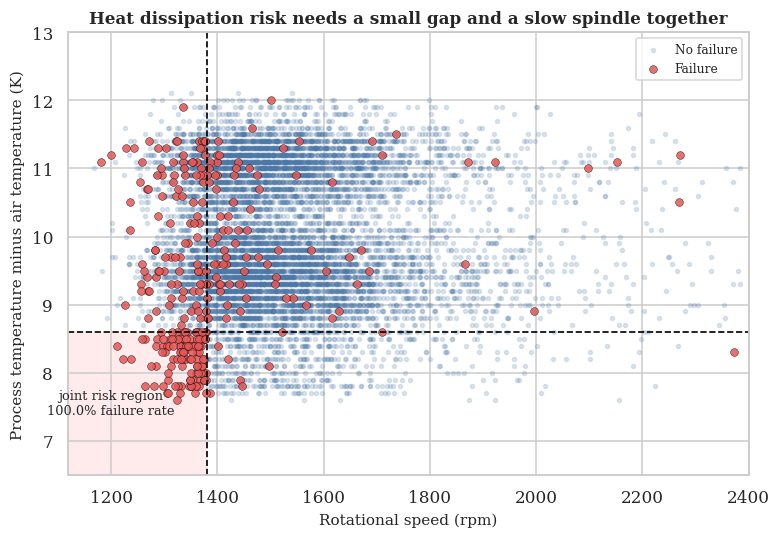

In [21]:
# ------------------------------------------------------------------
# FINDING 4 (multivariate): heat dissipation needs two variables at once
# ------------------------------------------------------------------
banner("FINDING 4  A small temperature gap is only dangerous at low speed")
cond = (df["temp_diff_K"] < 8.6) & (df["rot_speed_rpm"] < 1380)
only_gap = (df["temp_diff_K"] < 8.6) & (df["rot_speed_rpm"] >= 1380)
only_slow = (df["temp_diff_K"] >= 8.6) & (df["rot_speed_rpm"] < 1380)
for name, m in [("gap < 8.6 K AND speed < 1380 rpm", cond),
                ("gap < 8.6 K only", only_gap),
                ("speed < 1380 rpm only", only_slow),
                ("neither", ~(cond | only_gap | only_slow))]:
    print("%-34s n=%5d  failures=%4d  rate=%6.2f%%"
          % (name, int(m.sum()), int(df.loc[m, TARGET_CLEAN].sum()),
             100 * df.loc[m, TARGET_CLEAN].mean()))
joint = pd.DataFrame({
    "condition": ["gap < 8.6 K AND speed < 1380 rpm", "gap < 8.6 K only",
                  "speed < 1380 rpm only", "neither"],
    "n_rows": [int(m.sum()) for m in (cond, only_gap, only_slow,
                                      ~(cond | only_gap | only_slow))],
    "n_failures": [int(df.loc[m, TARGET_CLEAN].sum())
                   for m in (cond, only_gap, only_slow,
                             ~(cond | only_gap | only_slow))],
})
joint["failure_rate_pct"] = (100 * joint["n_failures"] / joint["n_rows"]).round(2)
save_table(joint, "tbl11_heat_dissipation_interaction")
print("WHAT IT CHANGES: neither condition alone is alarming, and together "
      "they are. An additive model has to approximate that with main effects "
      "it does not really have, so I expect logistic regression to lose "
      "recall here unless the interaction is handed to it explicitly.")
results["hdf_joint_rate"] = float(joint.loc[0, "failure_rate_pct"])
results["hdf_joint_n"] = int(joint.loc[0, "n_rows"])
results["hdf_joint_fail"] = int(joint.loc[0, "n_failures"])
results["hdf_gap_only_rate"] = float(joint.loc[1, "failure_rate_pct"])
results["hdf_slow_only_rate"] = float(joint.loc[2, "failure_rate_pct"])

fig, ax = plt.subplots(figsize=(7.2, 5.0))
ax.scatter(ok["rot_speed_rpm"], ok["temp_diff_K"], s=7, alpha=0.18,
           color=C_OK, label="No failure", rasterized=True)
ax.scatter(fail["rot_speed_rpm"], fail["temp_diff_K"], s=26, alpha=0.85,
           color=C_FAIL, edgecolor="black", linewidth=0.3, label="Failure")
ax.axhline(8.6, color="black", linestyle="--", linewidth=1.1)
ax.axvline(1380, color="black", linestyle="--", linewidth=1.1)
ax.add_patch(plt.Rectangle((df["rot_speed_rpm"].min() - 50, 0), 1380 -
                           df["rot_speed_rpm"].min() + 50, 8.6,
                           facecolor="red", alpha=0.08, zorder=0))
ax.text(1200, 7.4, "joint risk region\n%.1f%% failure rate"
        % results["hdf_joint_rate"], fontsize=8.5, ha="center")
ax.set_xlim(df["rot_speed_rpm"].min() - 50, 2400)
ax.set_ylim(6.5, 13)
ax.set_xlabel("Rotational speed (rpm)")
ax.set_ylabel("Process temperature minus air temperature (K)")
ax.set_title("Heat dissipation risk needs a small gap and a slow spindle together")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig06_tempgap_vs_speed")
plt.close(fig)

### FINDING 5  Overstrain depends on wear times torque, and the limit moves with Type


FINDING 5  Overstrain depends on wear times torque, and the limit moves with Type

[table] tbl12_failure_rate_by_type.csv
type    n  failures  mean_wear_torque  failure_rate_pct
   H 1003        21            4280.9              2.09
   L 6000       235            4341.5              3.92
   M 2997        83            4272.3              2.77

[table] tbl13_overstrain_threshold_by_type.csv
type  documented_limit  n_above  failures_above  rate_above_pct  n_below  failures_below  rate_below_pct
   L             11000       87              87           100.0     5913             148            2.50
   M             12000        9               9           100.0     2988              74            2.48
   H             13000        2               2           100.0     1001              19            1.90

WHAT IT CHANGES: the dangerous value of wear times torque is not one number, it shifts by product grade. A model that sees Type and the product term can carve that out; one that sees w

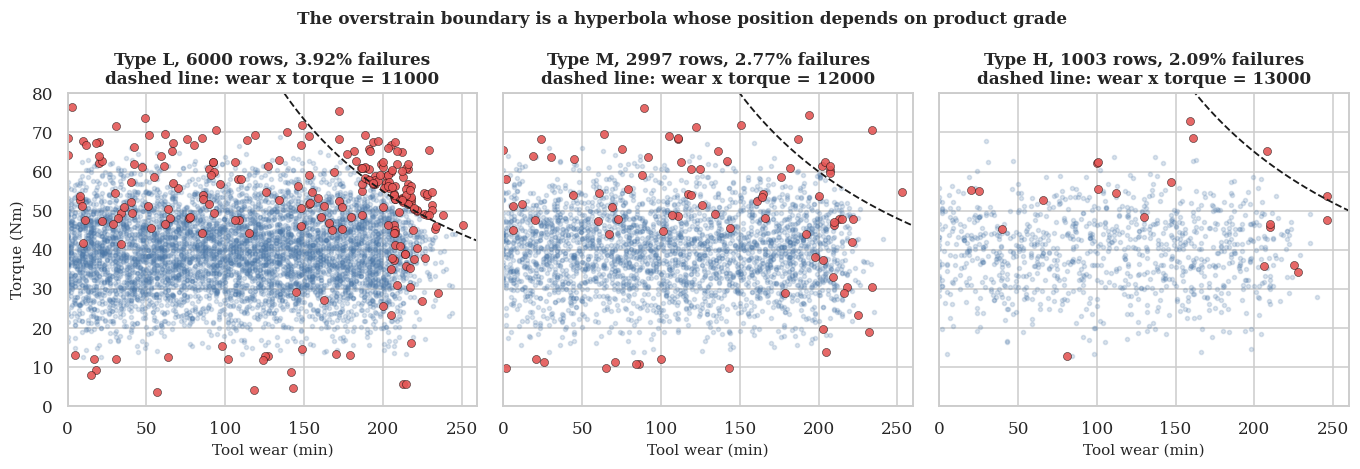

In [22]:
# ------------------------------------------------------------------
# FINDING 5 (multivariate): wear x torque, and it moves with product Type
# ------------------------------------------------------------------
banner("FINDING 5  Overstrain depends on wear times torque, and the limit moves with Type")
by_type = (df.groupby("type")
             .agg(n=("type", "size"), failures=(TARGET_CLEAN, "sum"),
                  mean_wear_torque=("wear_torque", "mean")))
by_type["mean_wear_torque"] = by_type["mean_wear_torque"].round(1)
by_type["failure_rate_pct"] = (100 * by_type["failures"] / by_type["n"]).round(2)
by_type = by_type.reset_index()
save_table(by_type, "tbl12_failure_rate_by_type")

wt_rows = []
for t, lim in [("L", 11000), ("M", 12000), ("H", 13000)]:
    sub = df[df["type"] == t]
    above = sub[sub["wear_torque"] > lim]
    below = sub[sub["wear_torque"] <= lim]
    wt_rows.append({
        "type": t, "documented_limit": lim,
        "n_above": len(above), "failures_above": int(above[TARGET_CLEAN].sum()),
        "rate_above_pct": round(100 * above[TARGET_CLEAN].mean(), 2) if len(above) else np.nan,
        "n_below": len(below), "failures_below": int(below[TARGET_CLEAN].sum()),
        "rate_below_pct": round(100 * below[TARGET_CLEAN].mean(), 2),
    })
wt = pd.DataFrame(wt_rows)
save_table(wt, "tbl13_overstrain_threshold_by_type")
print("\nWHAT IT CHANGES: the dangerous value of wear times torque is not "
      "one number, it shifts by product grade. A model that sees Type and "
      "the product term can carve that out; one that sees wear and torque "
      "separately has to rediscover a multiplication it was never shown. "
      "This is why I build the product explicitly and keep Type as a predictor.")
results["type_rates"] = {r["type"]: float(r["failure_rate_pct"])
                         for _, r in by_type.iterrows()}
results["type_counts"] = {r["type"]: int(r["n"]) for _, r in by_type.iterrows()}
results["overstrain"] = wt.to_dict("records")

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), sharey=True)
for ax, (t, lim) in zip(axes, [("L", 11000), ("M", 12000), ("H", 13000)]):
    sub = df[df["type"] == t]
    s_ok, s_f = sub[sub[TARGET_CLEAN] == 0], sub[sub[TARGET_CLEAN] == 1]
    ax.scatter(s_ok["tool_wear_min"], s_ok["torque_Nm"], s=7, alpha=0.2,
               color=C_OK, rasterized=True)
    ax.scatter(s_f["tool_wear_min"], s_f["torque_Nm"], s=28, alpha=0.9,
               color=C_FAIL, edgecolor="black", linewidth=0.3)
    w = np.linspace(1, 260, 300)
    ax.plot(w, lim / w, "k--", linewidth=1.2)
    ax.set_xlim(0, 260)
    ax.set_ylim(0, 80)
    ax.set_xlabel("Tool wear (min)")
    ax.set_title("Type %s, %d rows, %.2f%% failures\ndashed line: wear x torque = %d"
                 % (t, len(sub), 100 * sub[TARGET_CLEAN].mean(), lim))
axes[0].set_ylabel("Torque (Nm)")
fig.suptitle("The overstrain boundary is a hyperbola whose position depends on product grade",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig07_wear_torque_by_type")
plt.close(fig)

### FINDING 6  Tool wear only bites above roughly 200 minutes


FINDING 6  Tool wear only bites above roughly 200 minutes

[table] tbl14_failure_rate_by_wear_bin.csv
  wear_bin    n  failures  failure_rate_pct
   [0, 50) 2349        52              2.21
 [50, 100) 2271        51              2.25
[100, 150) 2290        52              2.27
[150, 200) 2289        61              2.66
[200, 220)  660        89             13.48
[220, 240)  127        30             23.62
[240, 260)   14         4             28.57

Failure rate below 50 minutes of wear : 2.21%
Failure rate in the 240 to 260 band   : 28.57%
WHAT IT CHANGES: the effect is a step, not a gradient. Logistic regression fits a single slope through that staircase and will under-react at the top end, while a tree can place a split exactly where the step is. It also tells me that scaling tool wear will not fix the shape, only the units.
[figure] fig08_wear_bands_and_type.png


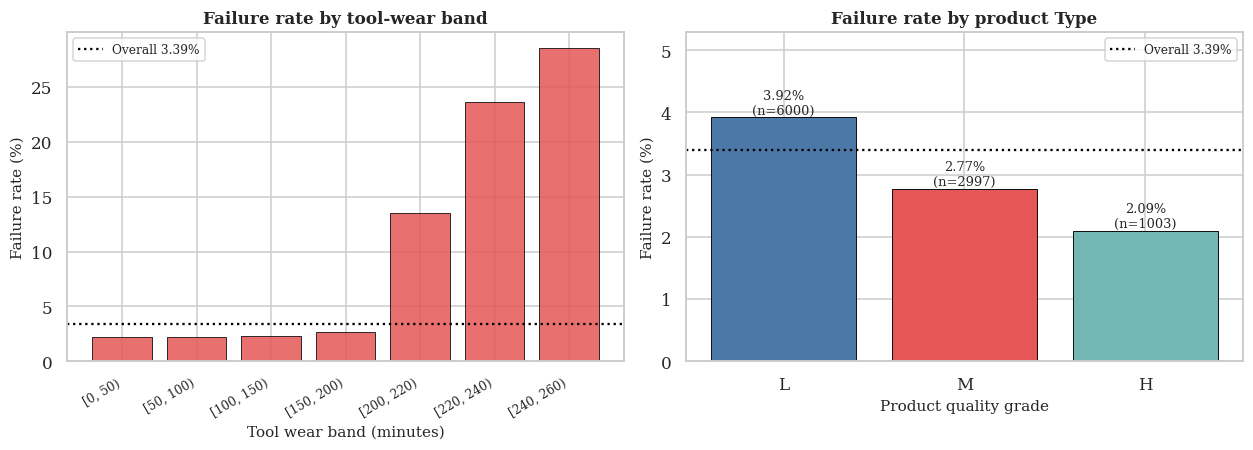


[table] tbl15_descriptives_by_class.csv
      variable statistic  no_failure  failure
    air_temp_K      mean      299.97   300.89
    air_temp_K       std        1.99     2.07
    air_temp_K    median      300.00   301.60
process_temp_K      mean      310.00   310.29
process_temp_K       std        1.49     1.36
process_temp_K    median      310.00   310.40
 rot_speed_rpm      mean     1540.26  1496.49
 rot_speed_rpm       std      167.39   384.94
 rot_speed_rpm    median     1507.00  1365.00
     torque_Nm      mean       39.63    50.17
     torque_Nm       std        9.47    16.37
     torque_Nm    median       39.90    53.70
 tool_wear_min      mean      106.69   143.78
 tool_wear_min       std       62.95    72.76
 tool_wear_min    median      107.00   165.00
   temp_diff_K      mean       10.02     9.40
   temp_diff_K       std        0.99     1.16
   temp_diff_K    median        9.80     9.30
       power_W      mean     6244.55  7282.82
       power_W       std     1011.39  1

In [23]:
# ------------------------------------------------------------------
# FINDING 6: tool wear is a staircase, not a slope
# ------------------------------------------------------------------
banner("FINDING 6  Tool wear only bites above roughly 200 minutes")
bins = [0, 50, 100, 150, 200, 220, 240, 260]
df["wear_bin"] = pd.cut(df["tool_wear_min"], bins=bins, right=False,
                        include_lowest=True)
wb = (df.groupby("wear_bin", observed=True)
        .agg(n=("tool_wear_min", "size"), failures=(TARGET_CLEAN, "sum")))
wb["failure_rate_pct"] = (100 * wb["failures"] / wb["n"]).round(2)
wb = wb.reset_index()
wb["wear_bin"] = wb["wear_bin"].astype(str)
save_table(wb, "tbl14_failure_rate_by_wear_bin")
lo = float(wb.loc[wb["wear_bin"].str.startswith("[0"), "failure_rate_pct"].iloc[0])
hi = float(wb["failure_rate_pct"].iloc[-1])
print("\nFailure rate below 50 minutes of wear : %.2f%%" % lo)
print("Failure rate in the 240 to 260 band   : %.2f%%" % hi)
print("WHAT IT CHANGES: the effect is a step, not a gradient. Logistic "
      "regression fits a single slope through that staircase and will "
      "under-react at the top end, while a tree can place a split exactly "
      "where the step is. It also tells me that scaling tool wear will not "
      "fix the shape, only the units.")
results["wear_low_rate"] = lo
results["wear_high_rate"] = hi

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].bar(range(len(wb)), wb["failure_rate_pct"], color=C_FAIL,
            edgecolor="black", linewidth=0.6, alpha=0.85)
axes[0].set_xticks(range(len(wb)))
axes[0].set_xticklabels(wb["wear_bin"], rotation=30, ha="right", fontsize=8)
axes[0].axhline(100 * n_fail / len(df), color="black", linestyle=":",
                label="Overall 3.39%")
axes[0].set_xlabel("Tool wear band (minutes)")
axes[0].set_ylabel("Failure rate (%)")
axes[0].set_title("Failure rate by tool-wear band")
axes[0].legend(fontsize=8)

tp = (df.groupby("type")
        .agg(rate=(TARGET_CLEAN, "mean"), n=("type", "size"))
        .reindex(["L", "M", "H"]).reset_index())
b = axes[1].bar(tp["type"], 100 * tp["rate"], color=PALETTE[:3],
                edgecolor="black", linewidth=0.6)
for bb, r, nn in zip(b, 100 * tp["rate"], tp["n"]):
    axes[1].text(bb.get_x() + bb.get_width() / 2, r + 0.06,
                 "%.2f%%\n(n=%d)" % (r, nn), ha="center", fontsize=8.5)
axes[1].axhline(100 * n_fail / len(df), color="black", linestyle=":",
                label="Overall 3.39%")
axes[1].set_xlabel("Product quality grade")
axes[1].set_ylabel("Failure rate (%)")
axes[1].set_ylim(0, max(100 * tp["rate"]) * 1.35)
axes[1].set_title("Failure rate by product Type")
axes[1].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig08_wear_bands_and_type")
plt.close(fig)

# ------------------------------------------------------------------
# descriptive table by class, used in the report
# ------------------------------------------------------------------
grp = df.groupby(TARGET_CLEAN)[NUMERIC_CLEAN + ["temp_diff_K", "power_W",
                                                    "wear_torque"]]
stats_tbl = grp.agg(["mean", "std", "median"]).round(2).T.reset_index()
stats_tbl.columns = ["variable", "statistic", "no_failure", "failure"]
save_table(stats_tbl, "tbl15_descriptives_by_class")

put("eda", results)
print("\nStage 02 complete.")

---
# 4. Preprocessing design and the split

Drop the identifiers and the leaking flags, rename the sensor columns, make the stratified split, and write down which preprocessing steps every model shares and which one depends on the algorithm.

Nothing is fitted here. Every transformer gets fitted inside cross-validation later, which is the whole reason for putting them in a `Pipeline` instead of transforming the frame up front and hoping for the best.

In [24]:
banner("STAGE 03  PREPROCESSING DESIGN")
raw = read_raw()
print("Loaded raw file: %s rows, %s columns" % raw.shape)


STAGE 03  PREPROCESSING DESIGN
Loaded raw file: 10000 rows, 14 columns


### Variable selection applied

In [25]:
# ------------------------------------------------------- 1. selection
banner("VARIABLE SELECTION APPLIED")
drop_cols = ID_COLS + FAILURE_FLAGS
print("Dropping identifiers   : %s" % ", ".join(ID_COLS))
print("Dropping leaking flags : %s" % ", ".join(FAILURE_FLAGS))
df = raw.drop(columns=drop_cols).rename(columns=RENAME)
print("Retained columns       : %s" % ", ".join(df.columns))
print("Shape after selection  : %s rows, %s columns" % df.shape)


VARIABLE SELECTION APPLIED
Dropping identifiers   : UDI, Product ID
Dropping leaking flags : TWF, HDF, PWF, OSF, RNF
Retained columns       : type, air_temp_K, process_temp_K, rot_speed_rpm, torque_Nm, tool_wear_min, machine_failure
Shape after selection  : 10000 rows, 7 columns


### Validity checks on the retained columns

In [26]:
# ------------------------------------------------------- 2. validity
banner("VALIDITY CHECKS ON THE RETAINED COLUMNS")
print("Missing cells                    : %d" % int(df.isna().sum().sum()))
print("Duplicated rows                  : %d" % int(df.duplicated().sum()))
print("type levels                      : %s"
      % sorted(df["type"].unique().tolist()))
print("Target levels                    : %s"
      % sorted(df[TARGET_CLEAN].unique().tolist()))
bad = int((df["process_temp_K"] <= df["air_temp_K"]).sum())
print("Physically impossible temp gaps  : %d" % bad)
print("\nNo row is dropped and no value is imputed, because nothing needs "
      "either. I keep a median imputer inside the numeric branch of the "
      "pipeline anyway: the deployed model will meet live sensor dropouts "
      "that this static extract does not contain.")


VALIDITY CHECKS ON THE RETAINED COLUMNS
Missing cells                    : 0
Duplicated rows                  : 0
type levels                      : ['H', 'L', 'M']
Target levels                    : [0, 1]
Physically impossible temp gaps  : 0

No row is dropped and no value is imputed, because nothing needs either. I keep a median imputer inside the numeric branch of the pipeline anyway: the deployed model will meet live sensor dropouts that this static extract does not contain.


### Stratified train / test split

In [27]:
# ------------------------------------------------------- 3. split
banner("STRATIFIED TRAIN / TEST SPLIT")
X = df.drop(columns=[TARGET_CLEAN])
y = df[TARGET_CLEAN]
idx_train, idx_test = train_test_split(
    np.arange(len(df)),
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y,
)
df["split"] = "train"
df.loc[df.index[idx_test], "split"] = "test"

tr, te = df[df["split"] == "train"], df[df["split"] == "test"]
split_tbl = pd.DataFrame({
    "partition": ["train", "test", "total"],
    "n_rows": [len(tr), len(te), len(df)],
    "n_failures": [int(tr[TARGET_CLEAN].sum()), int(te[TARGET_CLEAN].sum()),
                   int(df[TARGET_CLEAN].sum())],
})
split_tbl["failure_rate_pct"] = (
    100 * split_tbl["n_failures"] / split_tbl["n_rows"]).round(3)
save_table(split_tbl, "tbl16_train_test_split")
print("\ntest_size = %.2f, random_state = %d, stratify on the target."
      % (TEST_SIZE, SEED))
print("Stratifying matters at a 3.39% base rate: an unstratified 20% "
      "test set could easily land 15 failures away from the expected count, "
      "which would move recall by several points for reasons that have "
      "nothing to do with the model.")


STRATIFIED TRAIN / TEST SPLIT

[table] tbl16_train_test_split.csv
partition  n_rows  n_failures  failure_rate_pct
    train    8000         271             3.388
     test    2000          68             3.400
    total   10000         339             3.390

test_size = 0.20, random_state = 93, stratify on the target.
Stratifying matters at a 3.39% base rate: an unstratified 20% test set could easily land 15 failures away from the expected count, which would move recall by several points for reasons that have nothing to do with the model.


### Engineered features added (evaluated in stage 04)

In [28]:
# ------------------------------------------------------- 4. features
banner("ENGINEERED FEATURES ADDED (evaluated in stage 04)")
df = add_engineered(df)
print("Added: %s" % ", ".join(ENGINEERED))
print("Each is a row-wise function of that row's own sensor values. No "
      "mean, no quantile, no target information is involved, so computing "
      "them before the split cannot leak across folds. I state this "
      "explicitly because it is the one place where a reader might "
      "reasonably suspect leakage.")

ordered = (NUMERIC_CLEAN + ENGINEERED + CAT_CLEAN +
           [TARGET_CLEAN, "split"])
df = df[ordered]
df.to_csv(MODEL_READY_CSV, index=False)
print("\nModel-ready dataset written to %s" % MODEL_READY_CSV)
print("Shape: %s rows, %s columns" % df.shape)
print(df.head(5).to_string(index=False))


ENGINEERED FEATURES ADDED (evaluated in stage 04)
Added: power_W, temp_diff_K, wear_torque
Each is a row-wise function of that row's own sensor values. No mean, no quantile, no target information is involved, so computing them before the split cannot leak across folds. I state this explicitly because it is the one place where a reader might reasonably suspect leakage.

Model-ready dataset written to c:\Users\israe\Desktop\Predictive Take Home 2\DAMO510_A2\data\processed\ai4i2020_model_ready.csv
Shape: 10000 rows, 11 columns
 air_temp_K  process_temp_K  rot_speed_rpm  torque_Nm  tool_wear_min     power_W  temp_diff_K  wear_torque type  machine_failure split
      298.1           308.6           1551       42.8              0 6951.590560         10.5          0.0    M                0 train
      298.2           308.7           1408       46.3              3 6826.722724         10.5        138.9    L                0 train
      298.1           308.5           1498       49.4           

### Preprocessing plan: common versus model-specific

In [29]:
# ------------------------------------------------------- 5. the plan
banner("PREPROCESSING PLAN: COMMON VERSUS MODEL-SPECIFIC")
plan = pd.DataFrame([
    ("Drop UDI, Product ID", "Common", "All four",
     "Identifiers with no operational meaning; Product ID also duplicates Type."),
    ("Drop TWF, HDF, PWF, OSF, RNF", "Common", "All four",
     "Post-hoc failure-mode labels; the first four reproduce the target on "
     "99.91% of rows, so keeping them would hand the answer to the model."),
    ("Median imputation, numeric block", "Common", "All four",
     "Redundant on this extract (zero missing cells) and retained as an "
     "operational safeguard for live sensor dropouts."),
    ("One-hot encode type, drop first", "Common", "All four",
     "Three levels only. One-hot costs two columns and avoids asserting "
     "that the L to M to H spacing is equal, which an ordinal code would."),
    ("Engineered features", "Common", "All four",
     "power_W, temp_diff_K, wear_torque. Row-wise, so leakage-free."),
    ("Standardisation", "Model-specific", "Logistic Regression only",
     "The L2 penalty shrinks coefficients in proportion to their scale, so "
     "an unscaled torque in Nm and a wear-torque product in the thousands "
     "would be penalised very differently. Trees split on rank order, so "
     "scaling them would change nothing but would hide the units."),
    ("Class-imbalance treatment", "Model-specific", "Compared in stage 07",
     "class_weight for LR/DT/RF, scale_pos_weight for XGBoost, SMOTE inside "
     "the cross-validation pipeline. Never applied to a validation fold."),
], columns=["step", "scope", "applies_to", "justification"])
save_table(plan, "tbl17_preprocessing_plan")


PREPROCESSING PLAN: COMMON VERSUS MODEL-SPECIFIC

[table] tbl17_preprocessing_plan.csv
                            step          scope               applies_to                                                                                                                                                                                                                                                           justification
            Drop UDI, Product ID         Common                 All four                                                                                                                                                                                               Identifiers with no operational meaning; Product ID also duplicates Type.
    Drop TWF, HDF, PWF, OSF, RNF         Common                 All four                                                                                                                                Post-hoc failure-mode labels; the firs

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl17_preprocessing_plan.csv')

### The two preprocessor objects

In [30]:
# Show the two concrete preprocessor objects
banner("THE TWO PREPROCESSOR OBJECTS")
print("Scaled variant (Logistic Regression):")
print(build_preprocessor(scale=True))
print("\nUnscaled variant (Decision Tree, Random Forest, XGBoost):")
print(build_preprocessor(scale=False))

# sanity check: fitting on train only produces the expected width
pre = build_preprocessor(scale=True)
num, cat = feature_columns(True)
train_full = df[df["split"] == "train"]
Xt = pre.fit_transform(train_full[num + cat])
print("\nFitted on the training partition only. Design matrix: %s" % (Xt.shape,))
print("Output columns: %s" % ", ".join(expanded_feature_names(True)))
means = Xt[:, :len(num)].mean(axis=0)
print("Post-scaling training means (should be ~0): %s"
      % np.round(means, 6).tolist())

put("split", {
    "n_train": len(tr), "n_test": len(te),
    "train_pos": int(tr[TARGET_CLEAN].sum()),
    "test_pos": int(te[TARGET_CLEAN].sum()),
    "train_neg": int((tr[TARGET_CLEAN] == 0).sum()),
    "test_neg": int((te[TARGET_CLEAN] == 0).sum()),
    "train_rate_pct": round(100 * tr[TARGET_CLEAN].mean(), 3),
    "test_rate_pct": round(100 * te[TARGET_CLEAN].mean(), 3),
    "test_size": TEST_SIZE,
    "n_features_model": int(Xt.shape[1]),
    "dropped": drop_cols,
    "retained": [c for c in df.columns if c not in (TARGET_CLEAN, "split")],
})
print("\nStage 03 complete.")


THE TWO PREPROCESSOR OBJECTS
Scaled variant (Logistic Regression):
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['air_temp_K', 'process_temp_K',
                                  'rot_speed_rpm', 'torque_Nm', 'tool_wear_min',
                                  'power_W', 'temp_diff_K', 'wear_torque']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['type'])],
                  verbose_feature_names_out=False)

Unscaled variant (Decision Tree, Random Forest, XGBoost):
ColumnTransformer(transformers=[('num',
      


Fitted on the training partition only. Design matrix: (8000, 10)
Output columns: air_temp_K, process_temp_K, rot_speed_rpm, torque_Nm, tool_wear_min, power_W, temp_diff_K, wear_torque, type_L, type_M
Post-scaling training means (should be ~0): [-0.0, -0.0, 0.0, 0.0, 0.0, -0.0, 0.0, -0.0]

Stage 03 complete.


Load the dataset once here. Every later section slices it from memory.

I read it back from the file I just wrote rather than keeping the frame above, and that is on purpose. `ai4i2020_model_ready.csv` is the dataset I am handing in, so it ought to be the dataset the models are trained on. Writing a float to CSV and reading it back is not bit-exact, and the engineered columns come back about 1e-12 different. That is nothing as a measurement and still enough to move a tree's split point. Reading once here means every section sees the same file, and none of them has to open it again.

In [31]:
MODEL_READY = pd.read_csv(MODEL_READY_CSV)
print('Model-ready dataset loaded once, held in memory:',
      MODEL_READY.shape)
print('Columns:', ', '.join(MODEL_READY.columns))
print('Failures: train %d, test %d'
      % (MODEL_READY.loc[MODEL_READY['split'] == 'train',
                         TARGET_CLEAN].sum(),
         MODEL_READY.loc[MODEL_READY['split'] == 'test',
                         TARGET_CLEAN].sum()))

Model-ready dataset loaded once, held in memory: (10000, 11)
Columns: air_temp_K, process_temp_K, rot_speed_rpm, torque_Nm, tool_wear_min, power_W, temp_diff_K, wear_torque, type, machine_failure, split
Failures: train 271, test 68


---
# 5. Feature development

Three candidate features, each taken from the physics the AI4I documentation describes rather than from trying combinations until something worked. Each one has to earn its place against four kinds of evidence: how well it separates the classes on its own, how it correlates with the target, how much a fitted Random Forest leans on it, and what dropping it costs in cross-validated PR-AUC.

All of that is computed on the 8,000 training rows. Picking features by looking at the test set would leak even with no model fitted yet, and avoiding that is why I split first.

A small wrapper so I can score a feature set by cross-validated PR-AUC without rebuilding the pipeline by hand each time.

In [32]:
RAW_NUM = list(NUMERIC_CLEAN)


CAT = list(CAT_CLEAN)


def cv_pr_auc(model, X, y, numeric, categorical, scale):
    """Cross-validated PR-AUC for one feature set. The preprocessor sits inside
    the pipeline, so it is refitted on each training fold."""
    pipe = Pipeline([
        ("pre", build_preprocessor_cols(numeric, categorical, scale)),
        ("clf", model),
    ])
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring=SELECTION_METRIC, n_jobs=-1)
    return float(scores.mean()), float(scores.std())

In [33]:
banner("STAGE 04  FEATURE DEVELOPMENT")

df = read_model_ready()
train = df[df["split"] == "train"].reset_index(drop=True)
y = train[TARGET_CLEAN].to_numpy()
X = train.drop(columns=[TARGET_CLEAN, "split"])
print("Training partition: %d rows, %d failures (%.2f%%)"
      % (len(train), y.sum(), 100 * y.mean()))


STAGE 04  FEATURE DEVELOPMENT
Training partition: 8000 rows, 271 failures (3.39%)


### Definitions

In [34]:
# ------------------------------------------------------------------
banner("DEFINITIONS")
defs = pd.DataFrame([
    ("power_W", "torque_Nm x rot_speed_rpm x 2*pi/60",
     "Mechanical power in watts. Torque times angular velocity is the "
     "textbook definition, and rpm has to be converted to radians per "
     "second first. The AI4I documentation defines its power failure mode "
     "as this quantity falling outside a 3,500 to 9,000 W band, so the "
     "quantity is physically meaningful rather than a fishing expedition.",
     "Combines two originals"),
    ("temp_diff_K", "process_temp_K - air_temp_K",
     "The temperature the machine adds above ambient. A small gap means "
     "heat is not being carried away. The two raw temperatures correlate "
     "at r = 0.876, so their difference is the part of the pair that "
     "actually varies with machine condition.",
     "Combines two originals"),
    ("wear_torque", "tool_wear_min x torque_Nm",
     "A proxy for accumulated overstrain: a blunt tool pushed hard. The "
     "documented overstrain mode fires when this product passes a limit "
     "that itself depends on product grade, which is a multiplication a "
     "linear model cannot form on its own.",
     "Combines two originals"),
], columns=["feature", "formula", "reasoning", "type"])
save_table(defs, "tbl18_engineered_feature_definitions")


DEFINITIONS

[table] tbl18_engineered_feature_definitions.csv
    feature                             formula                                                                                                                                                                                                                                                                                                                                reasoning                   type
    power_W torque_Nm x rot_speed_rpm x 2*pi/60 Mechanical power in watts. Torque times angular velocity is the textbook definition, and rpm has to be converted to radians per second first. The AI4I documentation defines its power failure mode as this quantity falling outside a 3,500 to 9,000 W band, so the quantity is physically meaningful rather than a fishing expedition. Combines two originals
temp_diff_K         process_temp_K - air_temp_K                                                                                          

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl18_engineered_feature_definitions.csv')

### Evidence 1  distributional separation (training rows only)

In [35]:
# ------------------------------------------------------------------
banner("EVIDENCE 1  DISTRIBUTIONAL SEPARATION (training rows only)")
ev = []
for col in RAW_NUM + ENGINEERED:
    a = train.loc[train[TARGET_CLEAN] == 0, col]
    b = train.loc[train[TARGET_CLEAN] == 1, col]
    u, p = stats.mannwhitneyu(b, a, alternative="two-sided")
    auc = u / (len(a) * len(b))
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) /
                     (len(a) + len(b) - 2))
    d = (b.mean() - a.mean()) / pooled
    r_pb, p_pb = stats.pointbiserialr(train[TARGET_CLEAN], train[col])
    ev.append({
        "feature": col,
        "engineered": col in ENGINEERED,
        "median_no_failure": round(a.median(), 2),
        "median_failure": round(b.median(), 2),
        "cohens_d": round(d, 3),
        "univariate_auc": round(auc, 4),
        "point_biserial_r": round(r_pb, 4),
        "p_value": "%.3g" % p,
    })
ev = pd.DataFrame(ev)
ev["auc_distance_from_chance"] = (ev["univariate_auc"] - 0.5).abs().round(4)
ev = ev.sort_values("auc_distance_from_chance", ascending=False)
save_table(ev, "tbl19_feature_evidence_separation")

for f in ENGINEERED:
    r = ev[ev["feature"] == f].iloc[0]
    print("%-12s AUC %.4f, |r| %.4f, Cohen's d %+.3f"
          % (f, r["univariate_auc"], abs(r["point_biserial_r"]), r["cohens_d"]))
best_raw = ev[~ev["engineered"]].iloc[0]
print("\nBest raw predictor for comparison: %s at AUC %.4f"
      % (best_raw["feature"], best_raw["univariate_auc"]))


EVIDENCE 1  DISTRIBUTIONAL SEPARATION (training rows only)



[table] tbl19_feature_evidence_separation.csv
       feature  engineered  median_no_failure  median_failure  cohens_d  univariate_auc  point_biserial_r  p_value  auc_distance_from_chance
 rot_speed_rpm       False            1507.00         1365.00    -0.261          0.2272           -0.0472 9.06e-53                    0.2728
     torque_Nm       False              39.80           53.60     1.065          0.7713            0.1892 3.17e-52                    0.2713
       power_W        True            6244.29         7557.79     0.961          0.7441            0.1713 1.31e-42                    0.2441
   wear_torque        True            3947.60         7810.50     1.098          0.7066            0.1949 5.25e-31                    0.2066
   temp_diff_K        True               9.90            9.20    -0.667          0.3229           -0.1199 3.08e-23                    0.1771
 tool_wear_min       False             107.00          172.00     0.611          0.6698            0.1099 1

### Evidence 2  importance inside a fitted Random Forest

In [36]:
# ------------------------------------------------------------------
banner("EVIDENCE 2  IMPORTANCE INSIDE A FITTED RANDOM FOREST")
num_all = RAW_NUM + ENGINEERED
pipe = Pipeline([
    ("pre", build_preprocessor_cols(num_all, CAT, scale=False)),
    ("clf", RandomForestClassifier(n_estimators=400, random_state=SEED,
                                   class_weight="balanced", n_jobs=-1)),
])
pipe.fit(X[num_all + CAT], y)
names = num_all + ["type_L", "type_M"]
imp = pd.DataFrame({
    "feature": names,
    "gini_importance": np.round(pipe.named_steps["clf"].feature_importances_, 4),
})
imp["engineered"] = imp["feature"].isin(ENGINEERED)
imp = imp.sort_values("gini_importance", ascending=False).reset_index(drop=True)
imp["rank"] = imp.index + 1
save_table(imp, "tbl20_feature_evidence_rf_importance")
eng_ranks = {r["feature"]: int(r["rank"]) for _, r in imp.iterrows()
             if r["engineered"]}
print("\nRanks of the engineered features out of %d: %s" % (len(imp), eng_ranks))


EVIDENCE 2  IMPORTANCE INSIDE A FITTED RANDOM FOREST



[table] tbl20_feature_evidence_rf_importance.csv
       feature  gini_importance  engineered  rank
 rot_speed_rpm           0.2076       False     1
     torque_Nm           0.1909       False     2
       power_W           0.1650        True     3
 tool_wear_min           0.1367       False     4
   wear_torque           0.1205        True     5
   temp_diff_K           0.0992        True     6
    air_temp_K           0.0472       False     7
process_temp_K           0.0262       False     8
        type_M           0.0038       False     9
        type_L           0.0028       False    10

Ranks of the engineered features out of 10: {'power_W': 3, 'wear_torque': 5, 'temp_diff_K': 6}


In [37]:
# ------------------------------------------------------------------
banner("EVIDENCE 3  ABLATION BY CROSS-VALIDATED %s" % SELECTION_METRIC_LABEL)
print("Selection metric declared before running anything: %s."
      % SELECTION_METRIC_LABEL)
print("5-fold StratifiedKFold, shuffle=True, random_state=%d.\n" % SEED)

variants = {
    "A. raw sensors only": RAW_NUM,
    "B. raw + power_W": RAW_NUM + ["power_W"],
    "C. raw + temp_diff_K": RAW_NUM + ["temp_diff_K"],
    "D. raw + wear_torque": RAW_NUM + ["wear_torque"],
    "E. raw + all three engineered": RAW_NUM + ENGINEERED,
    "F. E minus power_W": RAW_NUM + ["temp_diff_K", "wear_torque"],
    "G. E minus temp_diff_K": RAW_NUM + ["power_W", "wear_torque"],
    "H. E minus wear_torque": RAW_NUM + ["power_W", "temp_diff_K"],
    "I. temp_diff replaces the two raw temperatures":
        ["rot_speed_rpm", "torque_Nm", "tool_wear_min", "power_W",
         "temp_diff_K", "wear_torque"],
}

rows = []
for label, cols in variants.items():
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED,
                                class_weight="balanced", n_jobs=1)
    lr = LogisticRegression(max_iter=5000, random_state=SEED,
                            class_weight="balanced")
    m_rf, s_rf = cv_pr_auc(rf, X[cols + CAT], y, cols, CAT, scale=False)
    m_lr, s_lr = cv_pr_auc(lr, X[cols + CAT], y, cols, CAT, scale=True)
    rows.append({
        "feature_set": label,
        "n_numeric_features": len(cols),
        "rf_cv_pr_auc": round(m_rf, 4), "rf_sd": round(s_rf, 4),
        "lr_cv_pr_auc": round(m_lr, 4), "lr_sd": round(s_lr, 4),
    })
    print("%-46s RF %.4f (sd %.4f)   LR %.4f (sd %.4f)"
          % (label, m_rf, s_rf, m_lr, s_lr))

abl = pd.DataFrame(rows)
base_rf = float(abl.loc[abl["feature_set"] == "A. raw sensors only",
                        "rf_cv_pr_auc"].iloc[0])
base_lr = float(abl.loc[abl["feature_set"] == "A. raw sensors only",
                        "lr_cv_pr_auc"].iloc[0])
abl["rf_gain_vs_raw"] = (abl["rf_cv_pr_auc"] - base_rf).round(4)
abl["lr_gain_vs_raw"] = (abl["lr_cv_pr_auc"] - base_lr).round(4)
save_table(abl, "tbl21_feature_ablation")

full_rf = float(abl.loc[abl["feature_set"] == "E. raw + all three engineered",
                        "rf_cv_pr_auc"].iloc[0])
full_lr = float(abl.loc[abl["feature_set"] == "E. raw + all three engineered",
                        "lr_cv_pr_auc"].iloc[0])

loo = {
    "power_W": ("F. E minus power_W", ),
    "temp_diff_K": ("G. E minus temp_diff_K", ),
    "wear_torque": ("H. E minus wear_torque", ),
}


EVIDENCE 3  ABLATION BY CROSS-VALIDATED PR-AUC (average precision)
Selection metric declared before running anything: PR-AUC (average precision).
5-fold StratifiedKFold, shuffle=True, random_state=93.



A. raw sensors only                            RF 0.7450 (sd 0.0203)   LR 0.4108 (sd 0.0447)
B. raw + power_W                               RF 0.8048 (sd 0.0307)   LR 0.4669 (sd 0.0302)
C. raw + temp_diff_K                           RF 0.8144 (sd 0.0450)   LR 0.4104 (sd 0.0451)
D. raw + wear_torque                           RF 0.7695 (sd 0.0230)   LR 0.4058 (sd 0.0477)
E. raw + all three engineered                  RF 0.8898 (sd 0.0168)   LR 0.4449 (sd 0.0407)
F. E minus power_W                             RF 0.8485 (sd 0.0338)   LR 0.4050 (sd 0.0477)
G. E minus temp_diff_K                         RF 0.8408 (sd 0.0284)   LR 0.4445 (sd 0.0406)
H. E minus wear_torque                         RF 0.8698 (sd 0.0345)   LR 0.4668 (sd 0.0303)
I. temp_diff replaces the two raw temperatures RF 0.8923 (sd 0.0175)   LR 0.4473 (sd 0.0382)

[table] tbl21_feature_ablation.csv
                                   feature_set  n_numeric_features  rf_cv_pr_auc  rf_sd  lr_cv_pr_auc  lr_sd  rf_gain_vs_raw  l

### Leave-one-out cost of dropping each engineered feature

In [38]:
banner("LEAVE-ONE-OUT COST OF DROPPING EACH ENGINEERED FEATURE")
loo_rows = []
for feat, (label, ) in loo.items():
    r = abl[abl["feature_set"] == label].iloc[0]
    loo_rows.append({
        "dropped_feature": feat,
        "rf_pr_auc_without": r["rf_cv_pr_auc"],
        "rf_cost_of_dropping": round(full_rf - r["rf_cv_pr_auc"], 4),
        "lr_pr_auc_without": r["lr_cv_pr_auc"],
        "lr_cost_of_dropping": round(full_lr - r["lr_cv_pr_auc"], 4),
    })
loo_df = pd.DataFrame(loo_rows)
save_table(loo_df, "tbl22_leave_one_out_cost")


LEAVE-ONE-OUT COST OF DROPPING EACH ENGINEERED FEATURE

[table] tbl22_leave_one_out_cost.csv
dropped_feature  rf_pr_auc_without  rf_cost_of_dropping  lr_pr_auc_without  lr_cost_of_dropping
        power_W             0.8485               0.0413             0.4050               0.0399
    temp_diff_K             0.8408               0.0490             0.4445               0.0004
    wear_torque             0.8698               0.0200             0.4668              -0.0219


WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl22_leave_one_out_cost.csv')

### Decision


DECISION
Rule fixed before looking at the numbers: retain an engineered feature if dropping it costs at least 0.005 cross-validated PR-AUC in either model, or if it ranks in the top half of the Random Forest importance table. Otherwise drop it and say so.

power_W      max ablation cost +0.0413, RF importance rank 3 of 10 -> RETAIN
temp_diff_K  max ablation cost +0.0490, RF importance rank 6 of 10 -> RETAIN
wear_torque  max ablation cost +0.0200, RF importance rank 5 of 10 -> RETAIN

Variant I removes air and process temperature and keeps only their difference. RF 0.8923 against 0.8898 for the full set, LR 0.4473 against 0.4449.
Variant I is nominally ahead by 0.0025 PR-AUC on the forest, against a fold-to-fold standard deviation of 0.0168. That gap is a fifth of the noise, so I am not going to read it as evidence of anything.
I keep the two raw temperatures. The leaner set is not measurably better, and the raw readings are the numbers an operator can pull straight off the machine, wh

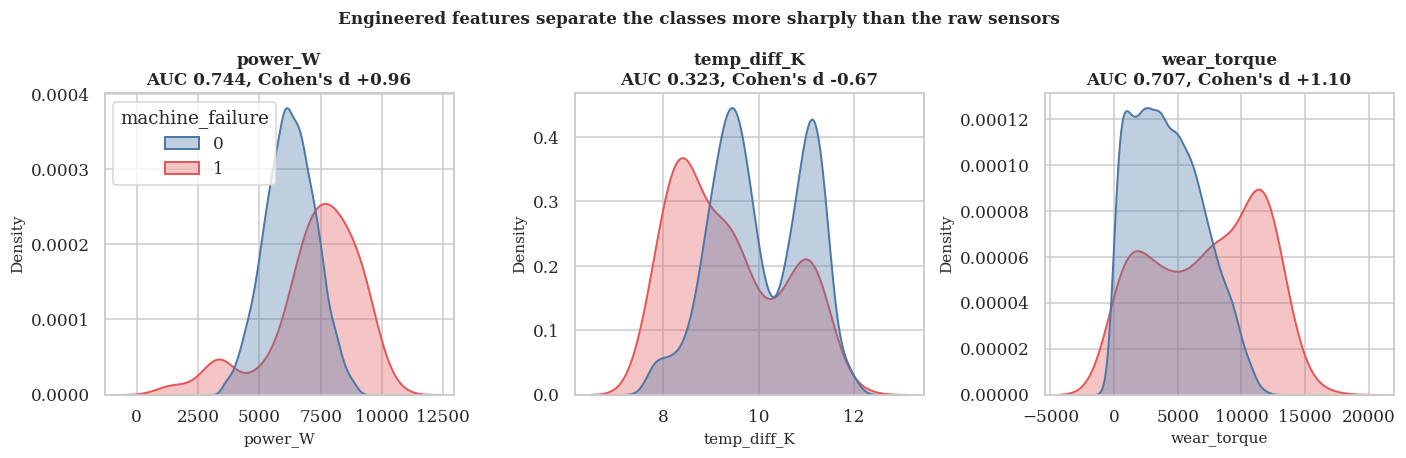

[figure] fig10_feature_ablation.png


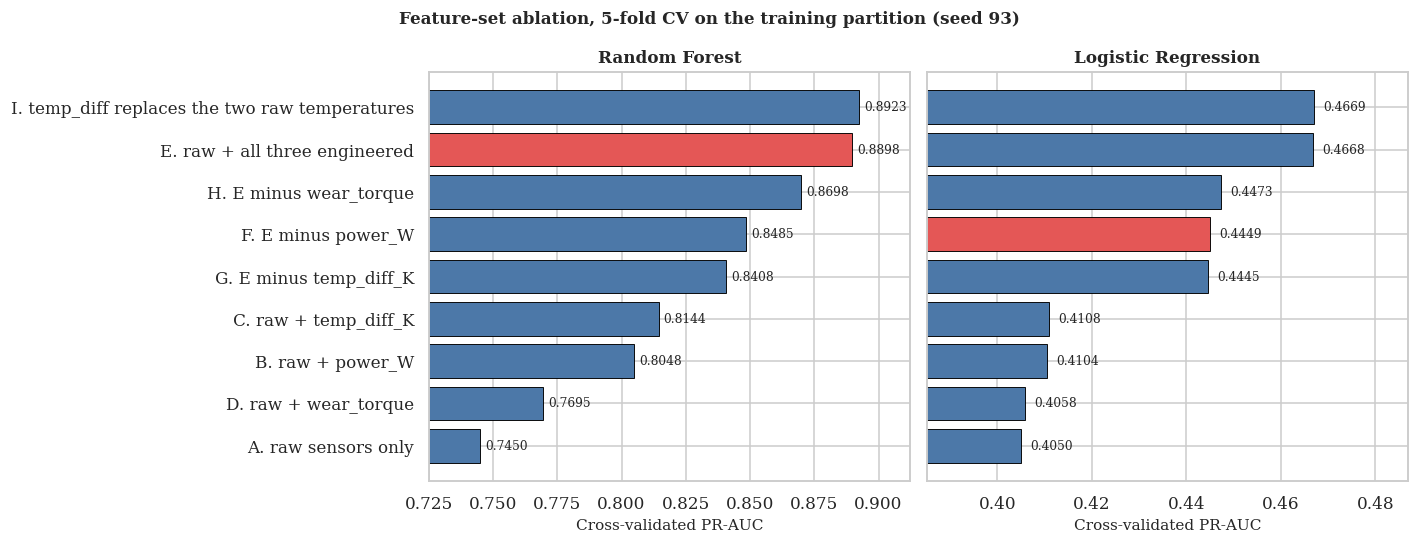


Stage 04 complete. Retained engineered features: power_W, temp_diff_K, wear_torque


In [39]:
# ------------------------------------------------------------------
banner("DECISION")
rule = ("Rule fixed before looking at the numbers: retain an engineered "
        "feature if dropping it costs at least 0.005 cross-validated "
        "PR-AUC in either model, or if it ranks in the top half of the "
        "Random Forest importance table. Otherwise drop it and say so.")
print(rule + "\n")

keep, drop = [], []
for _, r in loo_df.iterrows():
    f = r["dropped_feature"]
    cost = max(r["rf_cost_of_dropping"], r["lr_cost_of_dropping"])
    rank = eng_ranks[f]
    top_half = rank <= len(imp) / 2
    verdict = "RETAIN" if (cost >= 0.005 or top_half) else "DROP"
    (keep if verdict == "RETAIN" else drop).append(f)
    print("%-12s max ablation cost %+.4f, RF importance rank %d of %d -> %s"
          % (f, cost, rank, len(imp), verdict))

var_i_rf = float(abl.loc[abl["feature_set"].str.startswith("I."),
                         "rf_cv_pr_auc"].iloc[0])
var_i_lr = float(abl.loc[abl["feature_set"].str.startswith("I."),
                         "lr_cv_pr_auc"].iloc[0])
rf_sd_full = float(abl.loc[abl["feature_set"] == "E. raw + all three engineered",
                           "rf_sd"].iloc[0])
print("\nVariant I removes air and process temperature and keeps only their "
      "difference. RF %.4f against %.4f for the full set, LR %.4f against "
      "%.4f." % (var_i_rf, full_rf, var_i_lr, full_lr))
print("Variant I is nominally ahead by %.4f PR-AUC on the forest, against a "
      "fold-to-fold standard deviation of %.4f. That gap is a fifth of the "
      "noise, so I am not going to read it as evidence of anything."
      % (var_i_rf - full_rf, rf_sd_full))
print("I keep the two raw temperatures. The leaner set is not measurably "
      "better, and the raw readings are the numbers an operator can pull "
      "straight off the machine, which matters when someone has to sanity "
      "check an alarm. The collinearity that variant I removes is a "
      "readability problem for one model's coefficients, handled by the L2 "
      "penalty, and it is irrelevant to the three tree-based models.")

decision = pd.DataFrame([
    {"feature": f,
     "verdict": "Retained" if f in keep else "Dropped",
     "rf_importance_rank": eng_ranks[f],
     "max_ablation_cost_pr_auc": float(
         max(loo_df.loc[loo_df["dropped_feature"] == f,
                        "rf_cost_of_dropping"].iloc[0],
             loo_df.loc[loo_df["dropped_feature"] == f,
                        "lr_cost_of_dropping"].iloc[0]))}
    for f in ENGINEERED
])
save_table(decision, "tbl23_feature_decision")

# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, f in zip(axes, ENGINEERED):
    sns.kdeplot(data=train, x=f, hue=TARGET_CLEAN, common_norm=False,
                fill=True, alpha=0.35, palette=[C_OK, C_FAIL],
                ax=ax, linewidth=1.3, legend=(f == ENGINEERED[0]))
    r = ev[ev["feature"] == f].iloc[0]
    ax.set_title("%s\nAUC %.3f, Cohen's d %+.2f"
                 % (f, r["univariate_auc"], r["cohens_d"]))
    ax.set_ylabel("Density")
fig.suptitle("Engineered features separate the classes more sharply than the raw sensors",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig09_engineered_feature_separation")
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))
order = abl.sort_values("rf_cv_pr_auc")
cols_ = [C_FAIL if s.startswith("E.") else C_OK for s in order["feature_set"]]
axes[0].barh(order["feature_set"], order["rf_cv_pr_auc"], color=cols_,
             edgecolor="black", linewidth=0.6)
axes[0].set_xlim(min(order["rf_cv_pr_auc"]) - 0.02, max(order["rf_cv_pr_auc"]) + 0.02)
for i, (v, s) in enumerate(zip(order["rf_cv_pr_auc"], order["rf_sd"])):
    axes[0].text(v + 0.002, i, "%.4f" % v, va="center", fontsize=8)
axes[0].set_xlabel("Cross-validated PR-AUC")
axes[0].set_title("Random Forest")

order2 = abl.sort_values("lr_cv_pr_auc")
cols2 = [C_FAIL if s.startswith("E.") else C_OK for s in order2["feature_set"]]
axes[1].barh(order2["feature_set"], order2["lr_cv_pr_auc"], color=cols2,
             edgecolor="black", linewidth=0.6)
axes[1].set_xlim(min(order2["lr_cv_pr_auc"]) - 0.02, max(order2["lr_cv_pr_auc"]) + 0.02)
for i, v in enumerate(order2["lr_cv_pr_auc"]):
    axes[1].text(v + 0.002, i, "%.4f" % v, va="center", fontsize=8)
axes[1].set_xlabel("Cross-validated PR-AUC")
axes[1].set_title("Logistic Regression")
axes[1].set_yticklabels([])
fig.suptitle("Feature-set ablation, 5-fold CV on the training partition (seed 93)",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig10_feature_ablation")
plt.close(fig)

put("features", {
    "kept": keep, "dropped": drop,
    "rule": rule,
    "base_rf": base_rf, "base_lr": base_lr,
    "full_rf": full_rf, "full_lr": full_lr,
    "gain_rf": round(full_rf - base_rf, 4),
    "gain_lr": round(full_lr - base_lr, 4),
    "variant_i_rf": var_i_rf, "variant_i_lr": var_i_lr,
    "rf_ranks": eng_ranks,
    "n_features_total": int(len(imp)),
    "loo": loo_df.to_dict("records"),
    "train_auc": {r["feature"]: float(r["univariate_auc"])
                  for _, r in ev.iterrows()},
    "top_importance": imp.head(5).to_dict("records"),
})
print("\nStage 04 complete. Retained engineered features: %s" % ", ".join(keep))
if drop:
    print("Dropped: %s" % ", ".join(drop))

---
# 6. Baseline performance

Five reference points before fitting anything serious: a majority-class predictor, which sets up the accuracy trap; a stratified random guess, to see what chance alone buys; two rules a maintenance planner could apply today with no model at all; and a one-variable logistic regression on torque.

The two operator rules are the interesting ones. If a model cannot beat a threshold on tool wear, it has not earned the complexity it costs.

In [40]:
banner("STAGE 05  BASELINE PERFORMANCE")
X_tr, X_te, y_tr, y_te = load_model_ready(use_engineered=True)
num, cat = feature_columns(True)
print("Train %d rows (%d failures), test %d rows (%d failures)"
      % (len(X_tr), y_tr.sum(), len(X_te), y_te.sum()))

rows = []

# ---------------------------------------------------------- 1. majority
dm = DummyClassifier(strategy="most_frequent")
dm.fit(X_tr, y_tr)
rows.append(score_row("B1 Majority class (always predict no failure)",
                        y_te, dm.predict(X_te), dm.predict_proba(X_te)[:, 1]))

# ---------------------------------------------------------- 2. stratified
ds = DummyClassifier(strategy="stratified", random_state=SEED)
ds.fit(X_tr, y_tr)
rows.append(score_row("B2 Stratified random guess (seed 93)",
                        y_te, ds.predict(X_te), ds.predict_proba(X_te)[:, 1]))

# ---------------------------------------------------------- 3. wear rule
wear_rule = (X_te["tool_wear_min"] >= 200).astype(int).to_numpy()
rows.append(score_row("B3 Operator rule: tool wear >= 200 min",
                        y_te, wear_rule,
                        X_te["tool_wear_min"].to_numpy() / 260.0))

# ---------------------------------------------------------- 4. power rule
pw = X_te["power_W"].to_numpy()
power_rule = ((pw < 3500) | (pw > 9000)).astype(int)
# a monotone score for the curve metrics: distance outside the safe band
power_score = np.maximum(3500 - pw, pw - 9000)
power_score = (power_score - power_score.min()) / np.ptp(power_score)
rows.append(score_row("B4 Operator rule: power outside 3,500 to 9,000 W",
                        y_te, power_rule, power_score))

# ---------------------------------------------------------- 5. one feature
one = Pipeline([
    ("pre", build_preprocessor_cols(["torque_Nm"], [], scale=True)),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED)),
])
one.fit(X_tr[["torque_Nm"]], y_tr)
rows.append(score_row("B5 Logistic regression on torque alone",
                        y_te, one.predict(X_te[["torque_Nm"]]),
                        one.predict_proba(X_te[["torque_Nm"]])[:, 1]))

base = pd.DataFrame(rows)
save_table(base, "tbl24_baseline_results")


STAGE 05  BASELINE PERFORMANCE
Train 8000 rows (271 failures), test 2000 rows (68 failures)

[table] tbl24_baseline_results.csv
                                           model  accuracy  precision  recall     f1  roc_auc  pr_auc   TN  FP  FN  TP
   B1 Majority class (always predict no failure)    0.9660     0.0000  0.0000 0.0000   0.5000  0.0340 1932   0  68   0
            B2 Stratified random guess (seed 93)    0.9415     0.0702  0.0588 0.0640   0.5157  0.0361 1879  53  64   4
          B3 Operator rule: tool wear >= 200 min    0.9110     0.1333  0.2941 0.1835   0.6317  0.1044 1802 130  48  20
B4 Operator rule: power outside 3,500 to 9,000 W    0.9770     1.0000  0.3235 0.4889   0.8164  0.4424 1932   0  46  22
          B5 Logistic regression on torque alone    0.9665     1.0000  0.0147 0.0290   0.7659  0.3757 1932   0  67   1


WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl24_baseline_results.csv')

### What the baselines show


WHAT THE BASELINES SHOW
The majority-class predictor scores 96.60% accuracy while catching none of the 68 failures in the test set. Its recall is 0.00 and its precision is undefined, reported as 0.00 because it never issues a positive prediction. That is the whole problem with accuracy at a 3.4% base rate: a model can be right almost all the time and useless all of the time.

Stratified guessing lands at 94.15% accuracy and 0.059 recall, which is roughly the base rate reappearing on both sides of the confusion matrix. It flags 57 records to catch 4 failures.

The tool-wear rule is the interesting one. It catches 20 of 68 failures at 13.3% precision, so an engineer following it inspects 150 machines to find 20 real problems. Recall 0.294, F1 0.183.

The power-band rule catches 22 failures at 100.0% precision, F1 0.489. It is the strongest thing available without fitting anything, and it is the number the machine-learning models actually have to beat.

Logistic regression on torque alon

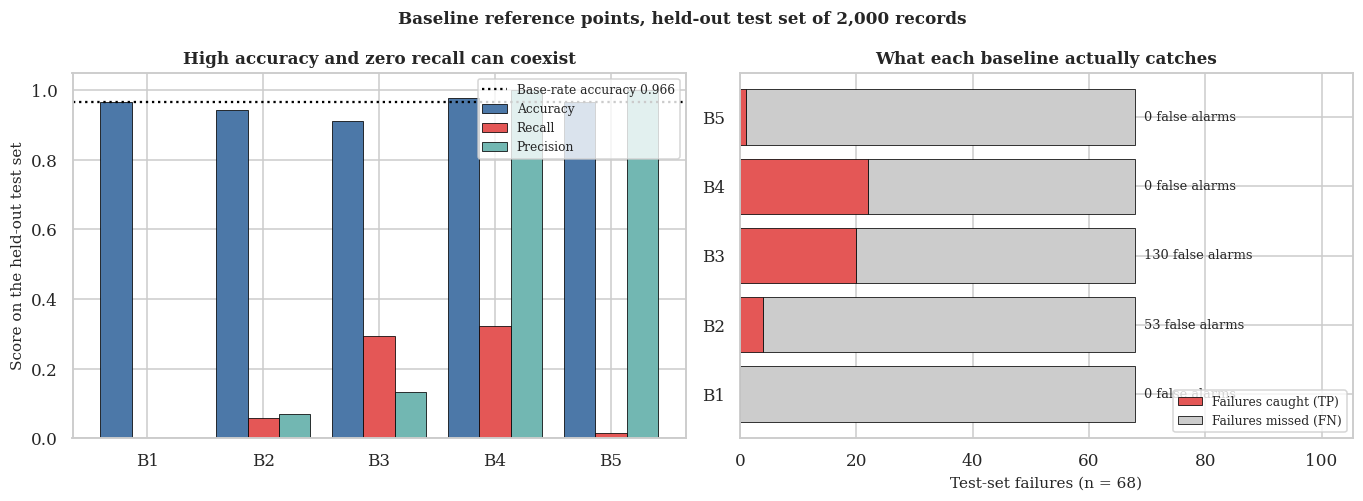


Stage 05 complete.


In [41]:
# ------------------------------------------------------------------
banner("WHAT THE BASELINES SHOW")
maj = base.iloc[0]
strat = base.iloc[1]
wear = base.iloc[2]
power = base.iloc[3]
onef = base.iloc[4]

print("The majority-class predictor scores %.2f%% accuracy while catching "
      "none of the %d failures in the test set. Its recall is %.2f and its "
      "precision is undefined, reported as %.2f because it never issues a "
      "positive prediction. That is the whole problem with accuracy at a "
      "3.4%% base rate: a model can be right almost all the time and useless "
      "all of the time."
      % (100 * maj["accuracy"], int(y_te.sum()), maj["recall"], maj["precision"]))
print("\nStratified guessing lands at %.2f%% accuracy and %.3f recall, which "
      "is roughly the base rate reappearing on both sides of the confusion "
      "matrix. It flags %d records to catch %d failures."
      % (100 * strat["accuracy"], strat["recall"],
         int(strat["FP"] + strat["TP"]), int(strat["TP"])))
print("\nThe tool-wear rule is the interesting one. It catches %d of %d "
      "failures at %.1f%% precision, so an engineer following it inspects "
      "%d machines to find %d real problems. Recall %.3f, F1 %.3f."
      % (int(wear["TP"]), int(y_te.sum()), 100 * wear["precision"],
         int(wear["FP"] + wear["TP"]), int(wear["TP"]),
         wear["recall"], wear["f1"]))
print("\nThe power-band rule catches %d failures at %.1f%% precision, "
      "F1 %.3f. It is the strongest thing available without fitting "
      "anything, and it is the number the machine-learning models actually "
      "have to beat."
      % (int(power["TP"]), 100 * power["precision"], power["f1"]))
print("\nLogistic regression on torque alone reaches ROC-AUC %.3f but "
      "predicts failure for %d records at the default 0.5 cut-off, so its "
      "recall is %.3f. The ranking information is there; the default "
      "threshold cannot reach it."
      % (onef["roc_auc"], int(onef["FP"] + onef["TP"]), onef["recall"]))

print("\nTaken together these say the problem is hard in a specific way. "
      "Ranking failures above healthy records is achievable. Converting "
      "that ranking into a decision at a fixed 0.5 cut-off is where the "
      "base rate does its damage, which is why stage 09 treats the "
      "threshold as a parameter rather than a constant.")

# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
labels = [s.split(" ", 1)[0] for s in base["model"]]
xpos = np.arange(len(base))
w = 0.27
axes[0].bar(xpos - w, base["accuracy"], w, label="Accuracy",
            color=PALETTE[0], edgecolor="black", linewidth=0.5)
axes[0].bar(xpos, base["recall"], w, label="Recall",
            color=PALETTE[1], edgecolor="black", linewidth=0.5)
axes[0].bar(xpos + w, base["precision"], w, label="Precision",
            color=PALETTE[2], edgecolor="black", linewidth=0.5)
axes[0].axhline(1 - y_te.mean(), color="black", linestyle=":",
                label="Base-rate accuracy %.3f" % (1 - y_te.mean()))
axes[0].set_xticks(xpos)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Score on the held-out test set")
axes[0].set_title("High accuracy and zero recall can coexist")
axes[0].legend(fontsize=8, loc="upper right")

axes[1].barh(xpos, base["TP"], color=C_FAIL, edgecolor="black",
             linewidth=0.5, label="Failures caught (TP)")
axes[1].barh(xpos, base["FN"], left=base["TP"], color="#cccccc",
             edgecolor="black", linewidth=0.5, label="Failures missed (FN)")
for i, r in base.iterrows():
    axes[1].text(int(y_te.sum()) + 1.5, i, "%d false alarms" % int(r["FP"]),
                 va="center", fontsize=8.5)
axes[1].set_yticks(xpos)
axes[1].set_yticklabels(labels)
axes[1].set_xlim(0, int(y_te.sum()) * 1.55)
axes[1].set_xlabel("Test-set failures (n = %d)" % int(y_te.sum()))
axes[1].set_title("What each baseline actually catches")
axes[1].legend(fontsize=8, loc="lower right")
fig.suptitle("Baseline reference points, held-out test set of 2,000 records",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig11_baseline_comparison")
plt.close(fig)

put("baseline", {
    "n_test": int(len(X_te)), "n_test_pos": int(y_te.sum()),
    "majority_acc": float(maj["accuracy"]),
    "majority_recall": float(maj["recall"]),
    "strat_acc": float(strat["accuracy"]),
    "strat_recall": float(strat["recall"]),
    "strat_tp": int(strat["TP"]), "strat_fp": int(strat["FP"]),
    "wear_tp": int(wear["TP"]), "wear_fp": int(wear["FP"]),
    "wear_recall": float(wear["recall"]), "wear_precision": float(wear["precision"]),
    "wear_f1": float(wear["f1"]),
    "power_tp": int(power["TP"]), "power_fp": int(power["FP"]),
    "power_recall": float(power["recall"]),
    "power_precision": float(power["precision"]), "power_f1": float(power["f1"]),
    "onef_auc": float(onef["roc_auc"]), "onef_recall": float(onef["recall"]),
    "best_baseline_f1": float(base["f1"].max()),
    "best_baseline_name": str(base.loc[base["f1"].idxmax(), "model"]),
    "best_baseline_pr_auc": float(base["pr_auc"].max()),
    "table": base.to_dict("records"),
})
print("\nStage 05 complete.")

---
# 7. The four models and their parameter search

For each of Logistic Regression, Decision Tree, Random Forest and XGBoost: a first version at library defaults, a search over a stated space, then a final configuration and the reason it won.

I fixed the selection metric before running any of it, so I could not go shopping afterwards for the metric that flattered the result. It is cross-validated PR-AUC, 5-fold `StratifiedKFold` with `shuffle=True` and `random_state=93`. The full `cv_results_` tables get written out, so the search is something that can be inspected rather than taken on trust.

I leave class imbalance alone here on purpose. The next section changes only the imbalance strategy on top of these tuned structures, so the two questions stay separable.

The cross-validation splitter, the metrics I want reported, and three wrappers: one to build a pipeline, one to score a configuration, and one to run a search and keep its full results.

In [42]:
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)


SCORING = ["average_precision", "roc_auc", "recall", "precision", "f1", "accuracy"]


def make_pipe(estimator, scale: bool) -> Pipeline:
    return Pipeline([("pre", build_preprocessor(scale=scale)), ("clf", estimator)])


def cv_report(name, estimator, scale, X, y):
    """Cross-validate one configuration and return a tidy one-row summary."""
    res = cross_validate(make_pipe(estimator, scale), X, y, cv=CV,
                         scoring=SCORING, n_jobs=-1, return_train_score=False)
    row = {"model": name}
    for s in SCORING:
        row["cv_" + s] = round(float(res["test_" + s].mean()), 4)
        row["sd_" + s] = round(float(res["test_" + s].std()), 4)
    row["fit_seconds"] = round(float(res["fit_time"].sum()), 2)
    return row


def run_search(label, search, X, y, tag):
    t0 = time.time()
    search.fit(X, y)
    elapsed = time.time() - t0
    cvr = pd.DataFrame(search.cv_results_)
    keep = [c for c in cvr.columns
            if c.startswith("param_") or c in
            ("mean_test_score", "std_test_score", "rank_test_score", "mean_fit_time")]
    tidy = (cvr[keep].sort_values("rank_test_score").reset_index(drop=True))
    tidy = tidy.round(5)
    save_table(tidy, "cv_%s_full_results" % tag)
    CV_RESULTS[tag] = tidy
    print("\n%s: %d configurations x %d folds = %d fits in %.1f s"
          % (label, len(cvr), CV_FOLDS, len(cvr) * CV_FOLDS, elapsed))
    print("Best cross-validated %s: %.4f" % (SELECTION_METRIC_LABEL,
                                             search.best_score_))
    print("Best parameters: %s" % search.best_params_)
    print("\nTop five configurations:")
    print(tidy.head(5).to_string(index=False))
    print("\nWorst configuration in the space scored %.4f, so the search spans "
          "a %.4f range." % (cvr["mean_test_score"].min(),
                             search.best_score_ - cvr["mean_test_score"].min()))
    return search, tidy, elapsed, len(cvr)

In [43]:
banner("STAGE 06  MODEL DEVELOPMENT AND PARAMETER SEARCH")
X_tr, X_te, y_tr, y_te = load_model_ready(use_engineered=True)
print("Training on %d rows, %d failures (%.2f%%)"
      % (len(X_tr), y_tr.sum(), 100 * y_tr.mean()))
print("\nSELECTION METRIC, DECLARED BEFORE ANY SEARCH RUNS")
print("  %s, maximised over 5-fold StratifiedKFold "
      "(shuffle=True, random_state=%d)." % (SELECTION_METRIC_LABEL, SEED))
print("  Accuracy is rejected as a selection metric because the majority-"
      "class predictor already scores 96.6% on it while catching zero "
      "failures, so it cannot distinguish a useful model from a useless one.")
print("  ROC-AUC is reported but not used to select, because at a 3.4% "
      "positive rate the false-positive rate denominator is dominated by "
      "the 9,661 healthy records and large changes in the number of false "
      "alarms barely move the curve. PR-AUC uses precision instead, so it "
      "responds to exactly the quantity a maintenance planner pays for.")


STAGE 06  MODEL DEVELOPMENT AND PARAMETER SEARCH
Training on 8000 rows, 271 failures (3.39%)

SELECTION METRIC, DECLARED BEFORE ANY SEARCH RUNS
  PR-AUC (average precision), maximised over 5-fold StratifiedKFold (shuffle=True, random_state=93).
  Accuracy is rejected as a selection metric because the majority-class predictor already scores 96.6% on it while catching zero failures, so it cannot distinguish a useful model from a useless one.
  ROC-AUC is reported but not used to select, because at a 3.4% positive rate the false-positive rate denominator is dominated by the 9,661 healthy records and large changes in the number of false alarms barely move the curve. PR-AUC uses precision instead, so it responds to exactly the quantity a maintenance planner pays for.


### Step 1  initial versions at library defaults

In [44]:
# ================================================== initial versions
banner("STEP 1  INITIAL VERSIONS AT LIBRARY DEFAULTS")
defaults = [
    ("Logistic Regression", LogisticRegression(max_iter=5000,
                                               random_state=SEED), True),
    ("Decision Tree", DecisionTreeClassifier(random_state=SEED), False),
    ("Random Forest", RandomForestClassifier(random_state=SEED,
                                             n_jobs=-1), False),
    ("XGBoost", XGBClassifier(random_state=SEED, eval_metric="logloss",
                              n_jobs=-1, tree_method="hist"), False),
]
default_rows = [cv_report(n, e, s, X_tr, y_tr) for n, e, s in defaults]
dflt = pd.DataFrame(default_rows)
save_table(dflt, "tbl25_default_model_cv")


STEP 1  INITIAL VERSIONS AT LIBRARY DEFAULTS

[table] tbl25_default_model_cv.csv
              model  cv_average_precision  sd_average_precision  cv_roc_auc  sd_roc_auc  cv_recall  sd_recall  cv_precision  sd_precision  cv_f1  sd_f1  cv_accuracy  sd_accuracy  fit_seconds
Logistic Regression                0.4744                0.0359      0.9197      0.0116     0.2177     0.0318        0.7457        0.0933 0.3339 0.0315       0.9708       0.0010         0.09
      Decision Tree                0.6906                0.0299      0.9103      0.0118     0.8267     0.0243        0.8287        0.0376 0.8269 0.0181       0.9883       0.0014         0.16
      Random Forest                0.8970                0.0172      0.9757      0.0131     0.8082     0.0337        0.9612        0.0142 0.8774 0.0141       0.9924       0.0007         1.35
            XGBoost                0.8510                0.0389      0.9798      0.0041     0.7456     0.0955        0.8698        0.0575 0.7992 0.0642   

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl25_default_model_cv.csv')

### Step 2  systematic parameter exploration

In [45]:
# ================================================== searches
banner("STEP 2  SYSTEMATIC PARAMETER EXPLORATION")
print("Grid search is used where the space is small enough to enumerate "
      "honestly. Randomised search with 80 draws is used for the two "
      "ensembles, because their spaces run to several hundred combinations "
      "and a random sample of a large space beats an exhaustive sweep of an "
      "artificially small one for the same compute.")

searches = {}


STEP 2  SYSTEMATIC PARAMETER EXPLORATION
Grid search is used where the space is small enough to enumerate honestly. Randomised search with 80 draws is used for the two ensembles, because their spaces run to several hundred combinations and a random sample of a large space beats an exhaustive sweep of an artificially small one for the same compute.


### 2a. Logistic Regression

In [46]:
# ---- Logistic Regression ----------------------------------------
banner("2a  LOGISTIC REGRESSION")
lr_grid = {
    "clf__C": [0.001, 0.01, 0.1, 0.5, 1, 5, 10, 100],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["liblinear"],
}
print("Space: C over eight orders of magnitude x {l1, l2} penalty. "
      "The penalty choice is the substantive one: L1 can zero out the "
      "collinear temperature pair, L2 shrinks it instead.")
s, t, el, n = run_search("Logistic Regression",
                         GridSearchCV(make_pipe(LogisticRegression(
                             max_iter=5000, random_state=SEED), True),
                             lr_grid, scoring=SELECTION_METRIC, cv=CV,
                             n_jobs=-1, return_train_score=False),
                         X_tr, y_tr, "lr")
searches["Logistic Regression"] = (s, el, n, True)


2a  LOGISTIC REGRESSION
Space: C over eight orders of magnitude x {l1, l2} penalty. The penalty choice is the substantive one: L1 can zero out the collinear temperature pair, L2 shrinks it instead.

[table] cv_lr_full_results.csv
 mean_fit_time  param_clf__C param_clf__penalty param_clf__solver  mean_test_score  std_test_score  rank_test_score
       0.02951         1.000                 l2         liblinear          0.47394         0.03145                1
       0.03186         0.500                 l2         liblinear          0.47324         0.03515                2
       0.08801         0.500                 l1         liblinear          0.47200         0.03452                3
       0.09183         1.000                 l1         liblinear          0.47126         0.03463                4
       0.02977         5.000                 l2         liblinear          0.46942         0.03577                5
       0.05536         0.100                 l1         liblinear        

### 2b. Decision Tree

In [47]:
# ---- Decision Tree ----------------------------------------------
banner("2b  DECISION TREE")
dt_grid = {
    "clf__max_depth": [3, 4, 5, 6, 8, 10, None],
    "clf__min_samples_leaf": [1, 5, 10, 20, 50],
    "clf__criterion": ["gini", "entropy"],
    "clf__min_samples_split": [2, 10],
}
print("Space: depth, leaf size, split size and impurity criterion. With 271 "
      "training failures, a leaf minimum of 1 will happily isolate single "
      "failures, so leaf size is the parameter that actually controls "
      "overfitting here.")
s, t, el, n = run_search("Decision Tree",
                         GridSearchCV(make_pipe(DecisionTreeClassifier(
                             random_state=SEED), False),
                             dt_grid, scoring=SELECTION_METRIC, cv=CV,
                             n_jobs=-1, return_train_score=False),
                         X_tr, y_tr, "dt")
searches["Decision Tree"] = (s, el, n, False)


2b  DECISION TREE
Space: depth, leaf size, split size and impurity criterion. With 271 training failures, a leaf minimum of 1 will happily isolate single failures, so leaf size is the parameter that actually controls overfitting here.

[table] cv_dt_full_results.csv
 mean_fit_time param_clf__criterion param_clf__max_depth  param_clf__min_samples_leaf  param_clf__min_samples_split  mean_test_score  std_test_score  rank_test_score
       0.03582                 gini                    6                           10                             2          0.89667         0.01640                1
       0.03495                 gini                    6                           10                            10          0.89667         0.01640                1
       0.03841                 gini                    6                           20                            10          0.89073         0.02128                3
       0.03872                 gini                    6            

### 2c. Random Forest

In [48]:
# ---- Random Forest ----------------------------------------------
banner("2c  RANDOM FOREST")
rf_space = {
    "clf__n_estimators": [200, 300, 400, 600, 800],
    "clf__max_depth": [None, 6, 8, 12, 16, 20],
    "clf__min_samples_leaf": [1, 2, 3, 5, 10],
    "clf__min_samples_split": [2, 5, 10],
    "clf__max_features": ["sqrt", "log2", 0.4, 0.6],
}
print("Space: 1,800 combinations, sampled 80 times with random_state=%d."
      % SEED)
s, t, el, n = run_search("Random Forest",
                         RandomizedSearchCV(make_pipe(RandomForestClassifier(
                             random_state=SEED, n_jobs=1), False),
                             rf_space, n_iter=80, scoring=SELECTION_METRIC,
                             cv=CV, n_jobs=-1, random_state=SEED,
                             return_train_score=False),
                         X_tr, y_tr, "rf")
searches["Random Forest"] = (s, el, n, False)


2c  RANDOM FOREST
Space: 1,800 combinations, sampled 80 times with random_state=93.

[table] cv_rf_full_results.csv
 mean_fit_time  param_clf__n_estimators  param_clf__min_samples_split  param_clf__min_samples_leaf param_clf__max_features param_clf__max_depth  mean_test_score  std_test_score  rank_test_score
       8.78339                      600                             2                            1                     0.6                    8          0.91349         0.01890                1
       4.74588                      300                            10                            3                     0.6                    8          0.91288         0.01863                2
       4.57546                      300                            10                            2                     0.6                    8          0.91273         0.01936                3
       3.20279                      200                             5                            5         

### 2d. XGBoost

In [49]:
# ---- XGBoost ------------------------------------------------------
banner("2d  XGBOOST")
xgb_space = {
    "clf__n_estimators": [200, 300, 400, 600, 800],
    "clf__max_depth": [2, 3, 4, 5, 6, 8],
    "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2, 0.3],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__colsample_bytree": [0.6, 0.8, 1.0],
    "clf__min_child_weight": [1, 3, 5, 10],
    "clf__gamma": [0, 0.1, 0.5],
    "clf__reg_lambda": [0.5, 1, 5],
}
print("Space: 116,640 combinations, sampled 80 times with random_state=%d. "
      "Exhaustive search is not on the table at that size, which is exactly "
      "why the randomised strategy is the right one." % SEED)
s, t, el, n = run_search("XGBoost",
                         RandomizedSearchCV(make_pipe(XGBClassifier(
                             random_state=SEED, eval_metric="logloss",
                             n_jobs=1, tree_method="hist"), False),
                             xgb_space, n_iter=80, scoring=SELECTION_METRIC,
                             cv=CV, n_jobs=-1, random_state=SEED,
                             return_train_score=False),
                         X_tr, y_tr, "xgb")
searches["XGBoost"] = (s, el, n, False)


2d  XGBOOST
Space: 116,640 combinations, sampled 80 times with random_state=93. Exhaustive search is not on the table at that size, which is exactly why the randomised strategy is the right one.

[table] cv_xgb_full_results.csv
 mean_fit_time  param_clf__subsample  param_clf__reg_lambda  param_clf__n_estimators  param_clf__min_child_weight  param_clf__max_depth  param_clf__learning_rate  param_clf__gamma  param_clf__colsample_bytree  mean_test_score  std_test_score  rank_test_score
       0.52584                   1.0                    5.0                      800                            1                     6                      0.03               0.5                          1.0          0.87373         0.04393                1
       0.57353                   0.6                    0.5                      400                            1                     6                      0.01               0.5                          0.8          0.87149         0.03855            

### Step 3  selected configurations

In [50]:
# ================================================== selected configs
banner("STEP 3  SELECTED CONFIGURATIONS")
tuned_rows, chosen = [], {}
for name, (search, el, n_cfg, scale) in searches.items():
    best = search.best_estimator_.named_steps["clf"]
    chosen[name] = {
        "params": {k.replace("clf__", ""): v
                   for k, v in search.best_params_.items()},
        "scale": scale,
        "cv_best": round(float(search.best_score_), 4),
        "n_configs": int(n_cfg),
        "search_seconds": round(el, 1),
    }
    tuned_rows.append(cv_report(name + " (tuned)", best, scale, X_tr, y_tr))
tuned = pd.DataFrame(tuned_rows)
save_table(tuned, "tbl26_tuned_model_cv")

cfg_tbl = pd.DataFrame([
    {"model": k,
     "n_configurations_tried": v["n_configs"],
     "search_seconds": v["search_seconds"],
     "selected_parameters": ", ".join("%s=%s" % (a, b)
                                      for a, b in sorted(v["params"].items())),
     "cv_pr_auc": v["cv_best"]}
    for k, v in chosen.items()
])
save_table(cfg_tbl, "tbl27_selected_configurations")

# default versus tuned, side by side
comp = pd.DataFrame({
    "model": dflt["model"],
    "default_cv_pr_auc": dflt["cv_average_precision"],
    "tuned_cv_pr_auc": tuned["cv_average_precision"].to_numpy(),
})
comp["improvement"] = (comp["tuned_cv_pr_auc"] -
                       comp["default_cv_pr_auc"]).round(4)
comp["default_cv_recall"] = dflt["cv_recall"]
comp["tuned_cv_recall"] = tuned["cv_recall"].to_numpy()
save_table(comp, "tbl28_default_vs_tuned")


STEP 3  SELECTED CONFIGURATIONS

[table] tbl26_tuned_model_cv.csv
                      model  cv_average_precision  sd_average_precision  cv_roc_auc  sd_roc_auc  cv_recall  sd_recall  cv_precision  sd_precision  cv_f1  sd_f1  cv_accuracy  sd_accuracy  fit_seconds
Logistic Regression (tuned)                0.4739                0.0315      0.9194      0.0120     0.2177     0.0318        0.7598        0.1110 0.3349 0.0314       0.9709       0.0012         0.12
      Decision Tree (tuned)                0.8967                0.0164      0.9746      0.0098     0.8119     0.0293        0.9583        0.0338 0.8782 0.0147       0.9924       0.0009         0.11
      Random Forest (tuned)                0.9135                0.0189      0.9844      0.0066     0.8156     0.0282        0.9747        0.0239 0.8874 0.0112       0.9930       0.0006        28.08
            XGBoost (tuned)                0.8737                0.0439      0.9825      0.0060     0.7418     0.0895        0.8845      

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl28_default_vs_tuned.csv')

### What the search bought


WHAT THE SEARCH BOUGHT
Logistic Regression    default 0.4744 -> tuned 0.4739  (-0.0005)
Decision Tree          default 0.6906 -> tuned 0.8967  (+0.2061)
Random Forest          default 0.8970 -> tuned 0.9135  (+0.0165)
XGBoost                default 0.8510 -> tuned 0.8737  (+0.0227)
[figure] fig12_tuning_summary.png


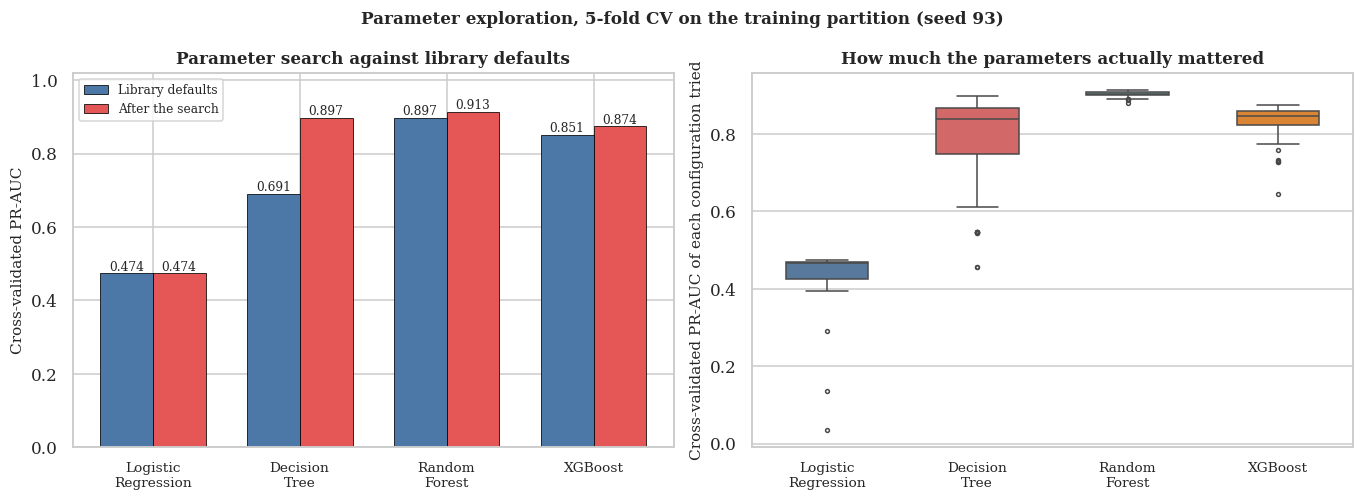


Stage 06 complete. 316 configurations evaluated in total, 1580 model fits.


In [51]:
banner("WHAT THE SEARCH BOUGHT")
for _, r in comp.iterrows():
    print("%-22s default %.4f -> tuned %.4f  (%+.4f)"
          % (r["model"], r["default_cv_pr_auc"], r["tuned_cv_pr_auc"],
             r["improvement"]))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
x = np.arange(len(comp))
w = 0.36
axes[0].bar(x - w / 2, comp["default_cv_pr_auc"], w, label="Library defaults",
            color=PALETTE[0], edgecolor="black", linewidth=0.5)
axes[0].bar(x + w / 2, comp["tuned_cv_pr_auc"], w, label="After the search",
            color=PALETTE[1], edgecolor="black", linewidth=0.5)
for i, r in comp.iterrows():
    axes[0].text(i - w / 2, r["default_cv_pr_auc"] + 0.008,
                 "%.3f" % r["default_cv_pr_auc"], ha="center", fontsize=8)
    axes[0].text(i + w / 2, r["tuned_cv_pr_auc"] + 0.008,
                 "%.3f" % r["tuned_cv_pr_auc"], ha="center", fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels([m.replace(" ", "\n") for m in comp["model"]],
                        fontsize=9)
axes[0].set_ylabel("Cross-validated PR-AUC")
axes[0].set_ylim(0, 1.02)
axes[0].set_title("Parameter search against library defaults")
axes[0].legend(fontsize=8)

# spread of the search for each model
spread = []
for tag, name in [("lr", "Logistic Regression"), ("dt", "Decision Tree"),
                  ("rf", "Random Forest"), ("xgb", "XGBoost")]:
    t = CV_RESULTS[tag]
    spread.append(pd.DataFrame({"model": name,
                                "score": t["mean_test_score"]}))
spread = pd.concat(spread)
sns.boxplot(data=spread, x="model", y="score", ax=axes[1],
            hue="model", palette=PALETTE[:4], legend=False,
            width=0.55, fliersize=2.5)
axes[1].set_xticks(range(4))
axes[1].set_xticklabels([m.replace(" ", "\n") for m in comp["model"]],
                        fontsize=9)
axes[1].set_xlabel("")
axes[1].set_ylabel("Cross-validated PR-AUC of each configuration tried")
axes[1].set_title("How much the parameters actually mattered")
fig.suptitle("Parameter exploration, 5-fold CV on the training partition (seed 93)",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig12_tuning_summary")
plt.close(fig)

put("tuning", {
    "chosen": chosen,
    "defaults": dflt.to_dict("records"),
    "tuned": tuned.to_dict("records"),
    "comparison": comp.to_dict("records"),
    "total_configs": int(sum(v["n_configs"] for v in chosen.values())),
    "total_fits": int(sum(v["n_configs"] for v in chosen.values()) * CV_FOLDS),
    "search_spread": {name: {"min": round(float(g["score"].min()), 4),
                             "max": round(float(g["score"].max()), 4)}
                      for name, g in spread.groupby("model")},
})
print("\nStage 06 complete. %d configurations evaluated in total, "
      "%d model fits." % (sum(v["n_configs"] for v in chosen.values()),
                          sum(v["n_configs"] for v in chosen.values()) * CV_FOLDS))

---
# 8. Class-imbalance investigation

Hold each tuned structure fixed and change only the imbalance strategy, so anything that moves is attributable to the treatment rather than to different hyperparameters.

Four treatments per model: nothing at all as the reference, class weighting, SMOTE, and SMOTE followed by undersampling.

Everything is scored by cross-validation on the training partition. The resampler sits inside an `imblearn` `Pipeline`, so it is refitted on each training fold and never touches the fold being scored. Resampling before cross-validation would leak synthetic neighbours into validation and flatter every number here.

The same splitter and the same metrics as the previous section, so the two sets of results can be read side by side.

In [52]:
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)


SCORING = ["average_precision", "roc_auc", "recall", "precision", "f1", "accuracy"]

In [53]:
banner("STAGE 07  CLASS-IMBALANCE INVESTIGATION")
X_tr, X_te, y_tr, y_te = load_model_ready(use_engineered=True)
tuning = get("tuning")["chosen"]

n_neg, n_pos = int((y_tr == 0).sum()), int((y_tr == 1).sum())
pos_weight = n_neg / n_pos
print("Training partition: %d healthy, %d failures, ratio %.2f to 1"
      % (n_neg, n_pos, pos_weight))
print("scale_pos_weight for XGBoost is set to that ratio, %.2f." % pos_weight)
print("SMOTE is configured with k_neighbors=5 and random_state=%d." % SEED)

rows = []
for name, cfg in tuning.items():
    params = cfg["params"]
    scale = cfg["scale"]
    pre = lambda: build_preprocessor(scale=scale)

    variants = {
        "none": Pipeline([("pre", pre()),
                          ("clf", build_estimator(name, params))]),
        "class weighting": Pipeline(
            [("pre", pre()),
             ("clf", build_estimator(name, params, weighted=True,
                                     pos_weight=pos_weight))]),
        "SMOTE": ImbPipeline(
            [("pre", pre()),
             ("smote", SMOTE(random_state=SEED, k_neighbors=5)),
             ("clf", build_estimator(name, params))]),
        "SMOTE + undersample": ImbPipeline(
            [("pre", pre()),
             ("smote", SMOTE(random_state=SEED, k_neighbors=5,
                             sampling_strategy=0.3)),
             ("under", RandomUnderSampler(random_state=SEED,
                                          sampling_strategy=0.5)),
             ("clf", build_estimator(name, params))]),
    }

    for treatment, pipe in variants.items():
        res = cross_validate(pipe, X_tr, y_tr, cv=CV, scoring=SCORING,
                             n_jobs=-1)
        row = {"model": name, "treatment": treatment}
        for s in SCORING:
            row[s] = round(float(res["test_" + s].mean()), 4)
            row[s + "_sd"] = round(float(res["test_" + s].std()), 4)
        rows.append(row)
        print("%-20s %-20s PR-AUC %.4f  recall %.4f  precision %.4f  F1 %.4f"
              % (name, treatment, row["average_precision"], row["recall"],
                 row["precision"], row["f1"]))

study = pd.DataFrame(rows)
save_table(study, "tbl29_imbalance_study_full")


STAGE 07  CLASS-IMBALANCE INVESTIGATION
Training partition: 7729 healthy, 271 failures, ratio 28.52 to 1
scale_pos_weight for XGBoost is set to that ratio, 28.52.
SMOTE is configured with k_neighbors=5 and random_state=93.
Logistic Regression  none                 PR-AUC 0.4739  recall 0.2177  precision 0.7598  F1 0.3349
Logistic Regression  class weighting      PR-AUC 0.4448  recall 0.8415  precision 0.1695  F1 0.2821
Logistic Regression  SMOTE                PR-AUC 0.4347  recall 0.8340  precision 0.1703  F1 0.2827
Logistic Regression  SMOTE + undersample  PR-AUC 0.4503  recall 0.7528  precision 0.2369  F1 0.3602
Decision Tree        none                 PR-AUC 0.8967  recall 0.8119  precision 0.9583  F1 0.8782
Decision Tree        class weighting      PR-AUC 0.8444  recall 0.9078  precision 0.4038  F1 0.5586
Decision Tree        SMOTE                PR-AUC 0.7934  recall 0.8895  precision 0.3976  F1 0.5469
Decision Tree        SMOTE + undersample  PR-AUC 0.8057  recall 0.8413  prec

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl29_imbalance_study_full.csv')

### The trade-off, quantified

In [54]:
# ------------------------------------------------------------------
banner("THE TRADE-OFF, QUANTIFIED")
piv = study.pivot(index="model", columns="treatment",
                  values=["recall", "precision", "f1", "average_precision"])
trade_rows = []
for name in tuning:
    base = study[(study["model"] == name) & (study["treatment"] == "none")].iloc[0]
    for treatment in ["class weighting", "SMOTE", "SMOTE + undersample"]:
        v = study[(study["model"] == name) &
                  (study["treatment"] == treatment)].iloc[0]
        trade_rows.append({
            "model": name,
            "treatment": treatment,
            "recall_change": round(v["recall"] - base["recall"], 4),
            "precision_change": round(v["precision"] - base["precision"], 4),
            "f1_change": round(v["f1"] - base["f1"], 4),
            "pr_auc_change": round(v["average_precision"] -
                                   base["average_precision"], 4),
            "roc_auc_change": round(v["roc_auc"] - base["roc_auc"], 4),
        })
trade = pd.DataFrame(trade_rows)
save_table(trade, "tbl30_imbalance_tradeoff")

for _, r in trade.iterrows():
    print("%-20s %-20s recall %+.4f, precision %+.4f, PR-AUC %+.4f"
          % (r["model"], r["treatment"], r["recall_change"],
             r["precision_change"], r["pr_auc_change"]))


THE TRADE-OFF, QUANTIFIED

[table] tbl30_imbalance_tradeoff.csv
              model           treatment  recall_change  precision_change  f1_change  pr_auc_change  roc_auc_change
Logistic Regression     class weighting         0.6238           -0.5903    -0.0528        -0.0291          0.0090
Logistic Regression               SMOTE         0.6163           -0.5895    -0.0522        -0.0392          0.0091
Logistic Regression SMOTE + undersample         0.5351           -0.5229     0.0253        -0.0236          0.0086
      Decision Tree     class weighting         0.0959           -0.5545    -0.3196        -0.0523         -0.0454
      Decision Tree               SMOTE         0.0776           -0.5607    -0.3313        -0.1033         -0.0249
      Decision Tree SMOTE + undersample         0.0294           -0.3679    -0.1884        -0.0910         -0.0207
      Random Forest     class weighting        -0.0037           -0.1139    -0.0526        -0.0194          0.0011
      Random Fo

### Retention decision


RETENTION DECISION
Rule stated before reading the table: the retained treatment is the one with the highest cross-validated PR-AUC, because PR-AUC scores the whole ranking rather than the arbitrary 0.5 cut-off, and stage 09 sets the operating threshold separately. Where two treatments sit within one standard deviation of each other I take the simpler one, since a resampler that buys nothing is a moving part that can still break.

Logistic Regression  best by PR-AUC: none                 (0.4739 vs untreated 0.4739, gap 0.0000, untreated sd 0.0315) -> retain 'none'
Decision Tree        best by PR-AUC: none                 (0.8967 vs untreated 0.8967, gap 0.0000, untreated sd 0.0164) -> retain 'none'
Random Forest        best by PR-AUC: none                 (0.9135 vs untreated 0.9135, gap 0.0000, untreated sd 0.0189) -> retain 'none'
XGBoost              best by PR-AUC: none                 (0.8737 vs untreated 0.8737, gap 0.0000, untreated sd 0.0439) -> retain 'none'

[table] tbl31_im

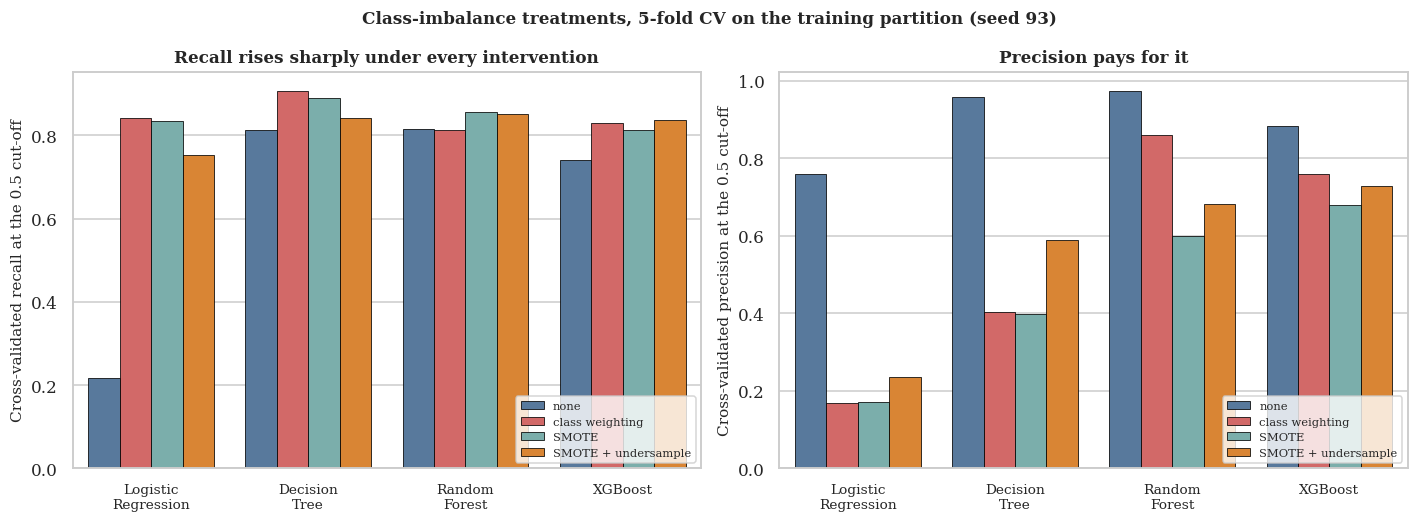

[figure] fig14_imbalance_tradeoff_scatter.png


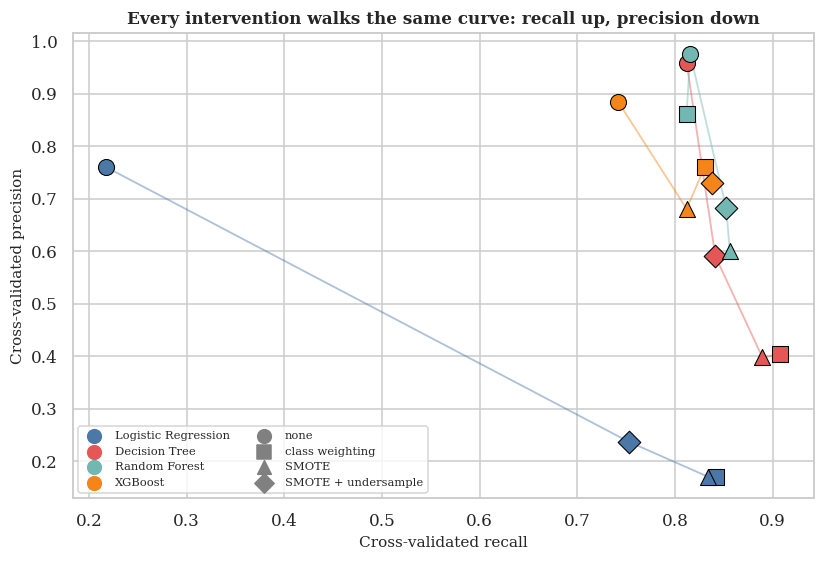


Stage 07 complete. Retained treatments: {'Logistic Regression': 'none', 'Decision Tree': 'none', 'Random Forest': 'none', 'XGBoost': 'none'}


In [55]:
# ------------------------------------------------------------------
banner("RETENTION DECISION")
print("Rule stated before reading the table: the retained treatment is the "
      "one with the highest cross-validated PR-AUC, because PR-AUC scores "
      "the whole ranking rather than the arbitrary 0.5 cut-off, and stage 09 "
      "sets the operating threshold separately. Where two treatments sit "
      "within one standard deviation of each other I take the simpler one, "
      "since a resampler that buys nothing is a moving part that can still "
      "break.\n")

retained = {}
dec_rows = []
for name in tuning:
    sub = study[study["model"] == name].sort_values("average_precision",
                                                    ascending=False)
    best = sub.iloc[0]
    none_row = sub[sub["treatment"] == "none"].iloc[0]
    within_noise = (best["average_precision"] - none_row["average_precision"]
                    ) <= none_row["average_precision_sd"]
    pick = "none" if within_noise else best["treatment"]
    retained[name] = pick
    dec_rows.append({
        "model": name,
        "best_pr_auc_treatment": best["treatment"],
        "best_pr_auc": best["average_precision"],
        "untreated_pr_auc": none_row["average_precision"],
        "gap": round(best["average_precision"] - none_row["average_precision"], 4),
        "untreated_sd": none_row["average_precision_sd"],
        "within_one_sd": bool(within_noise),
        "retained": pick,
    })
    print("%-20s best by PR-AUC: %-20s (%.4f vs untreated %.4f, gap %.4f, "
          "untreated sd %.4f) -> retain '%s'"
          % (name, best["treatment"], best["average_precision"],
             none_row["average_precision"],
             best["average_precision"] - none_row["average_precision"],
             none_row["average_precision_sd"], pick))
dec = pd.DataFrame(dec_rows)
save_table(dec, "tbl31_imbalance_retention_decision")

print("\nThe headline is that none of these treatments changes how well the "
      "models rank records. What they change is where the 0.5 cut-off "
      "lands on that ranking, which is a threshold decision wearing a "
      "resampling costume. That is worth saying plainly, because the "
      "obvious expectation is that SMOTE improves the model.")

# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order = ["none", "class weighting", "SMOTE", "SMOTE + undersample"]
sns.barplot(data=study, x="model", y="recall", hue="treatment",
            hue_order=order, palette=PALETTE[:4], ax=axes[0],
            edgecolor="black", linewidth=0.5)
axes[0].set_ylabel("Cross-validated recall at the 0.5 cut-off")
axes[0].set_xlabel("")
axes[0].set_title("Recall rises sharply under every intervention")
axes[0].set_xticks(range(4))
axes[0].set_xticklabels([m.replace(" ", "\n") for m in
                         study["model"].unique()], fontsize=9)
axes[0].legend(fontsize=7.5, title=None, loc="lower right")

sns.barplot(data=study, x="model", y="precision", hue="treatment",
            hue_order=order, palette=PALETTE[:4], ax=axes[1],
            edgecolor="black", linewidth=0.5)
axes[1].set_ylabel("Cross-validated precision at the 0.5 cut-off")
axes[1].set_xlabel("")
axes[1].set_title("Precision pays for it")
axes[1].set_xticks(range(4))
axes[1].set_xticklabels([m.replace(" ", "\n") for m in
                         study["model"].unique()], fontsize=9)
axes[1].legend(fontsize=7.5, title=None, loc="lower right")
fig.suptitle("Class-imbalance treatments, 5-fold CV on the training partition (seed 93)",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig13_imbalance_recall_precision")
plt.close(fig)

fig, ax = plt.subplots(figsize=(7.6, 5.2))
markers = {"none": "o", "class weighting": "s", "SMOTE": "^",
           "SMOTE + undersample": "D"}
colours = dict(zip(study["model"].unique(), PALETTE[:4]))
for _, r in study.iterrows():
    ax.scatter(r["recall"], r["precision"], s=110,
               marker=markers[r["treatment"]], color=colours[r["model"]],
               edgecolor="black", linewidth=0.7, zorder=3)
for m, c in colours.items():
    sub = study[study["model"] == m].sort_values("recall")
    ax.plot(sub["recall"], sub["precision"], color=c, alpha=0.45,
            linewidth=1.2, zorder=2)
    ax.scatter([], [], color=c, s=80, label=m)
for t, mk in markers.items():
    ax.scatter([], [], color="grey", marker=mk, s=80, label=t)
ax.set_xlabel("Cross-validated recall")
ax.set_ylabel("Cross-validated precision")
ax.set_title("Every intervention walks the same curve: recall up, precision down")
ax.legend(fontsize=7.5, ncol=2, loc="lower left")
fig.tight_layout()
save_fig(fig, "fig14_imbalance_tradeoff_scatter")
plt.close(fig)

put("imbalance", {
    "retained": retained,
    "pos_weight": round(pos_weight, 2),
    "study": study.to_dict("records"),
    "tradeoff": trade.to_dict("records"),
    "decision": dec.to_dict("records"),
})
print("\nStage 07 complete. Retained treatments: %s" % retained)

---
# 9. Evaluation on the held-out test set

Fit each model in its final form, the tuned parameters from the search plus whichever imbalance treatment I decided to keep, on all 8,000 training rows, then score it once on the 2,000 records held back. This is the first time the test set is used for anything.

Out of this come the consolidated comparison table, the confusion matrices, the ROC and precision-recall curves, and the predicted probabilities that the threshold and error sections work from.

In [56]:
banner("STAGE 08  MODEL EVALUATION ON THE HELD-OUT TEST SET")
X_tr, X_te, y_tr, y_te = load_model_ready(use_engineered=True)
imb = get("imbalance")
tuning = get("tuning")["chosen"]
print("Test set: %d records, %d failures (%.2f%%). Untouched until now."
      % (len(X_te), y_te.sum(), 100 * y_te.mean()))

models = build_final_models(use_engineered=True)
rows, probas, fitted = [], {}, {}

for name in MODEL_ORDER:
    pipe = models[name]
    pipe.fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    r = score_row(name, y_te, pred, proba)
    r["imbalance_treatment"] = imb["retained"][name]
    r["parameters"] = ", ".join("%s=%s" % (k, v) for k, v in
                                sorted(tuning[name]["params"].items()))
    rows.append(r)
    probas[name] = proba
    fitted[name] = pipe
    print("%-20s acc %.4f  prec %.4f  rec %.4f  F1 %.4f  ROC %.4f  PR %.4f"
          % (name, r["accuracy"], r["precision"], r["recall"], r["f1"],
             r["roc_auc"], r["pr_auc"]))

comp = pd.DataFrame(rows)
main_cols = ["model", "accuracy", "precision", "recall", "f1", "roc_auc",
             "pr_auc", "TN", "FP", "FN", "TP", "imbalance_treatment"]
save_table(comp[main_cols], "tbl32_model_comparison")
save_table(comp[["model", "parameters", "imbalance_treatment"]],
             "tbl33_final_model_specifications")


STAGE 08  MODEL EVALUATION ON THE HELD-OUT TEST SET
Test set: 2000 records, 68 failures (3.40%). Untouched until now.
Logistic Regression  acc 0.9720  prec 0.8333  rec 0.2206  F1 0.3488  ROC 0.9075  PR 0.5408
Decision Tree        acc 0.9925  prec 1.0000  rec 0.7794  F1 0.8760  ROC 0.9709  PR 0.8849
Random Forest        acc 0.9920  prec 0.9815  rec 0.7794  F1 0.8689  ROC 0.9792  PR 0.9048
XGBoost              acc 0.9880  prec 0.8793  rec 0.7500  F1 0.8095  ROC 0.9757  PR 0.8734

[table] tbl32_model_comparison.csv
              model  accuracy  precision  recall     f1  roc_auc  pr_auc   TN  FP  FN  TP imbalance_treatment
Logistic Regression    0.9720     0.8333  0.2206 0.3488   0.9075  0.5408 1929   3  53  15                none
      Decision Tree    0.9925     1.0000  0.7794 0.8760   0.9709  0.8849 1932   0  15  53                none
      Random Forest    0.9920     0.9815  0.7794 0.8689   0.9792  0.9048 1931   1  15  53                none
            XGBoost    0.9880     0.8793 

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl33_final_model_specifications.csv')

### Which model is best depends on what the plant fears


WHICH MODEL IS BEST DEPENDS ON WHAT THE PLANT FEARS
accuracy   best: Decision Tree        0.9925     weakest: Logistic Regression  0.9720
precision  best: Decision Tree        1.0000     weakest: Logistic Regression  0.8333
recall     best: Decision Tree        0.7794     weakest: Logistic Regression  0.2206
f1         best: Decision Tree        0.8760     weakest: Logistic Regression  0.3488
roc_auc    best: Random Forest        0.9792     weakest: Logistic Regression  0.9075
pr_auc     best: Random Forest        0.9048     weakest: Logistic Regression  0.5408

[table] tbl34_strongest_weakest_by_criterion.csv
criterion strongest_model  value       weakest_model  weakest_value
 accuracy   Decision Tree 0.9925 Logistic Regression         0.9720
precision   Decision Tree 1.0000 Logistic Regression         0.8333
   recall   Decision Tree 0.7794 Logistic Regression         0.2206
       f1   Decision Tree 0.8760 Logistic Regression         0.3488
  roc_auc   Random Forest 0.9792 Logistic

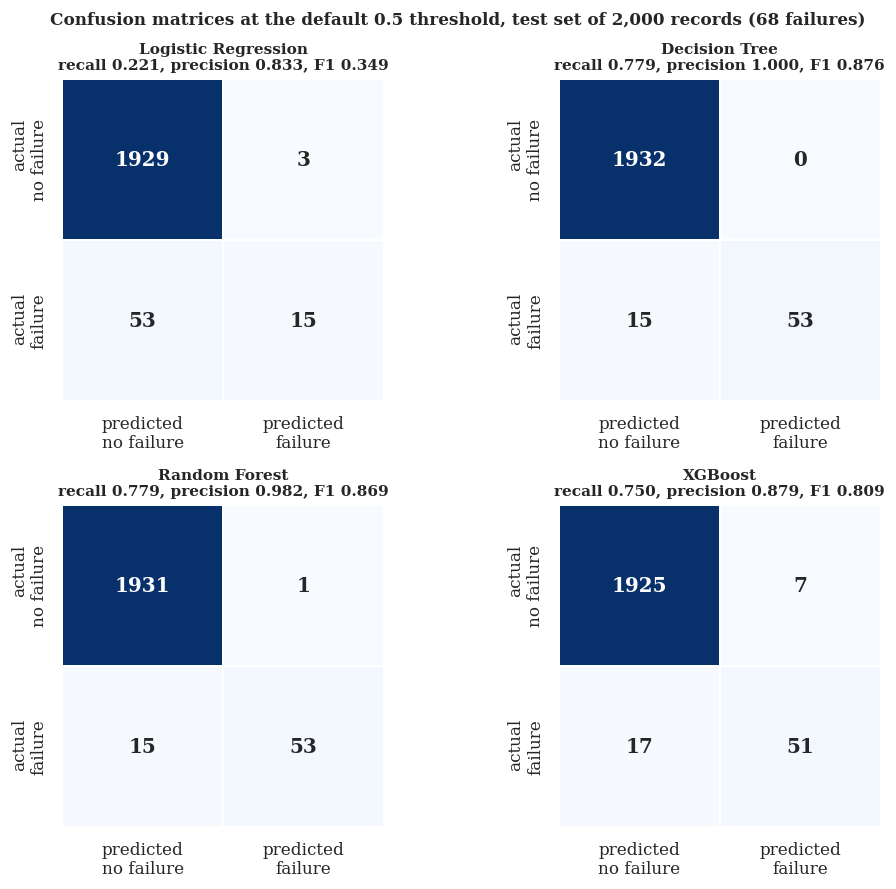

[figure] fig16_roc_and_pr_curves.png


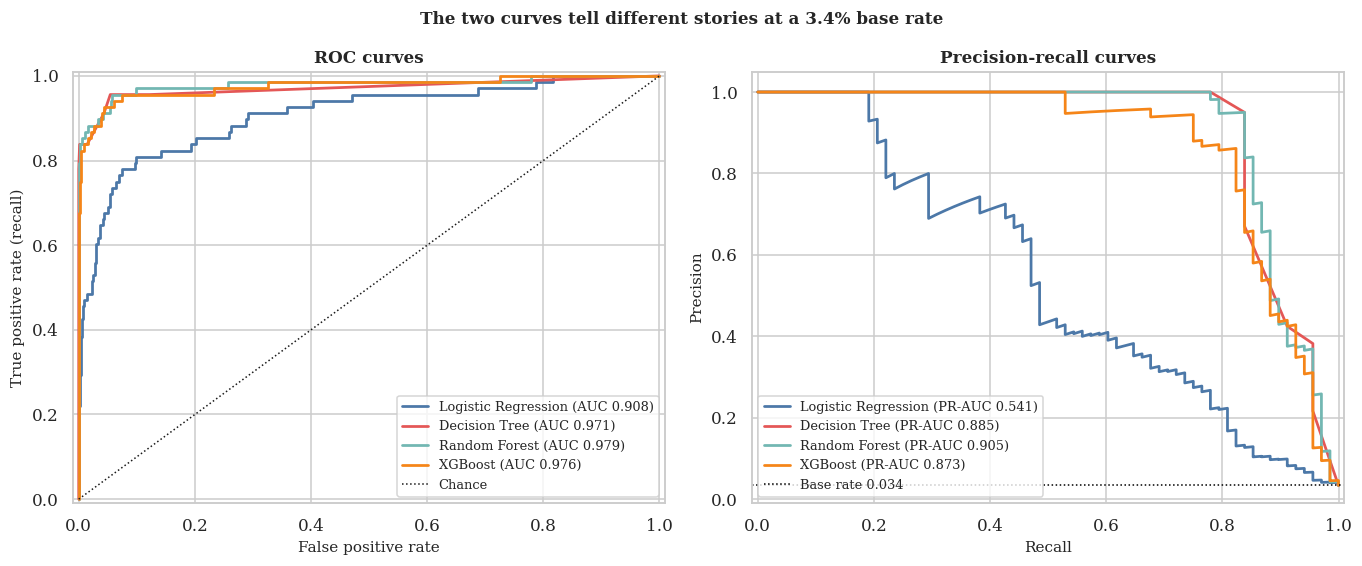

[figure] fig17_metric_comparison.png


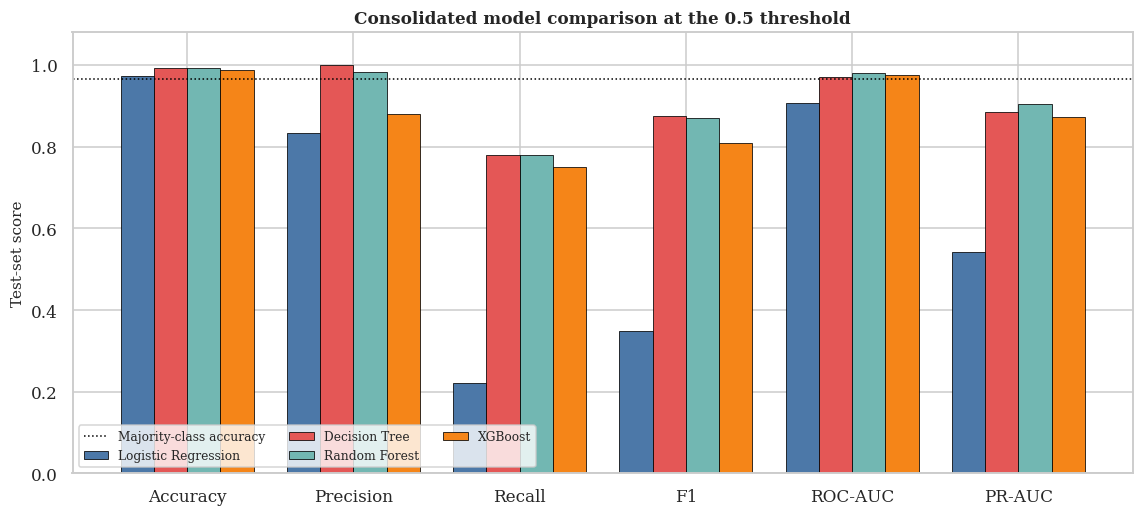


Predicted probabilities written to outputs/tables/test_predicted_probabilities.csv

Stage 08 complete.


In [57]:
# ------------------------------------------------------------------
banner("WHICH MODEL IS BEST DEPENDS ON WHAT THE PLANT FEARS")
by = {}
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
    top = comp.loc[comp[metric].idxmax()]
    bot = comp.loc[comp[metric].idxmin()]
    by[metric] = {"best": str(top["model"]), "best_value": float(top[metric]),
                  "worst": str(bot["model"]), "worst_value": float(bot[metric])}
    print("%-10s best: %-20s %.4f     weakest: %-20s %.4f"
          % (metric, top["model"], top[metric], bot["model"], bot[metric]))

winners = pd.DataFrame([
    {"criterion": k, "strongest_model": v["best"], "value": v["best_value"],
     "weakest_model": v["worst"], "weakest_value": v["worst_value"]}
    for k, v in by.items()])
save_table(winners, "tbl34_strongest_weakest_by_criterion")

best_rec = comp.loc[comp["recall"].idxmax()]
best_prec = comp.loc[comp["precision"].idxmax()]
best_pr = comp.loc[comp["pr_auc"].idxmax()]

# How many operating points does each model actually offer?
gran = pd.DataFrame({
    "model": MODEL_ORDER,
    "distinct_probabilities_on_test": [int(pd.Series(probas[m]).nunique())
                                       for m in MODEL_ORDER],
})
gran["available_operating_points"] = gran["distinct_probabilities_on_test"]
save_table(gran, "tbl35_probability_granularity")

dt = comp[comp["model"] == "Decision Tree"].iloc[0]
rf = comp[comp["model"] == "Random Forest"].iloc[0]
lr = comp[comp["model"] == "Logistic Regression"].iloc[0]
dt_gran = int(gran.loc[gran["model"] == "Decision Tree",
                       "distinct_probabilities_on_test"].iloc[0])
rf_gran = int(gran.loc[gran["model"] == "Random Forest",
                       "distinct_probabilities_on_test"].iloc[0])

print("\nAt the 0.5 cut-off the Decision Tree tops every point metric: "
      "accuracy %.4f, precision %.4f, recall %.4f, F1 %.4f. The Random "
      "Forest catches the same %d failures and differs by a single false "
      "alarm. On that evidence alone the tree looks like the answer, and "
      "it is the simpler model, so this is not a close call to wave away."
      % (dt["accuracy"], dt["precision"], dt["recall"], dt["f1"],
         int(dt["TP"])))
print("\nThe ranking metrics disagree. Random Forest leads on ROC-AUC "
      "(%.4f against %.4f) and on PR-AUC (%.4f against %.4f). The reason "
      "is visible in the predicted probabilities: the tuned tree has a "
      "depth-6 structure with a minimum of ten samples per leaf, so on "
      "the test set it emits only %d distinct probability values, one per "
      "reachable leaf. The forest emits %d."
      % (rf["roc_auc"], dt["roc_auc"], rf["pr_auc"], dt["pr_auc"],
         dt_gran, rf_gran))
print("That is the whole argument. A model with %d possible scores has %d "
      "possible operating points, and stage 09 exists precisely to move "
      "the operating point. The tree's advantage at 0.5 is a piece of "
      "luck about where its leaves happen to fall, not a property that "
      "survives being asked for more recall. The forest's ranking is what "
      "can be re-cut." % (dt_gran, dt_gran))
print("\nSo the answer to 'which is best' splits cleanly. If the plant "
      "will run the model at a fixed default cut-off and never revisit "
      "it, the Decision Tree is the strongest and the cheapest to explain. "
      "If the plant wants to choose its own balance between %d missed "
      "failures and the false alarms that reducing them would cost, only "
      "the forest and XGBoost offer a dial fine enough to turn."
      % int(dt["FN"]))
print("\nLogistic regression is the weakest on every criterion: PR-AUC "
      "%.4f against %.4f for the forest, and it finds %d of %d failures. "
      "That is the exploratory analysis coming true. Failures sit at both "
      "ends of the torque and speed range and behind a temperature-by-"
      "speed interaction, and a single linear boundary cannot enclose two "
      "opposite corners of a plane at once."
      % (lr["pr_auc"], rf["pr_auc"], int(lr["TP"]), int(y_te.sum())))
print("\nAccuracy separates almost nothing: the four models span %.4f to "
      "%.4f, and the do-nothing baseline already sits at %.4f. Reporting "
      "it is a formality; deciding on it would be a mistake."
      % (comp["accuracy"].min(), comp["accuracy"].max(), 1 - y_te.mean()))

# ------------------------------------------------------------------
# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(9.4, 8.2))
for ax, name in zip(axes.ravel(), MODEL_ORDER):
    r = comp[comp["model"] == name].iloc[0]
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                square=True, linewidths=1.2, linecolor="white", ax=ax,
                annot_kws={"fontsize": 13, "fontweight": "bold"},
                xticklabels=["predicted\nno failure", "predicted\nfailure"],
                yticklabels=["actual\nno failure", "actual\nfailure"])
    ax.set_title("%s\nrecall %.3f, precision %.3f, F1 %.3f"
                 % (name, r["recall"], r["precision"], r["f1"]), fontsize=10)
fig.suptitle("Confusion matrices at the default 0.5 threshold, "
             "test set of 2,000 records (68 failures)",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig15_confusion_matrices")
plt.close(fig)

# ROC curves
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for name, colour in zip(MODEL_ORDER, PALETTE[:4]):
    fpr, tpr, _ = roc_curve(y_te, probas[name])
    axes[0].plot(fpr, tpr, color=colour, linewidth=1.8,
                 label="%s (AUC %.3f)" % (name, roc_auc_score(y_te, probas[name])))
axes[0].plot([0, 1], [0, 1], "k:", linewidth=1, label="Chance")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].set_xlim(-0.01, 1.01)
axes[0].set_ylim(-0.01, 1.01)

for name, colour in zip(MODEL_ORDER, PALETTE[:4]):
    prec, rec, _ = precision_recall_curve(y_te, probas[name])
    axes[1].plot(rec, prec, color=colour, linewidth=1.8,
                 label="%s (PR-AUC %.3f)"
                       % (name, average_precision_score(y_te, probas[name])))
axes[1].axhline(y_te.mean(), color="black", linestyle=":", linewidth=1,
                label="Base rate %.3f" % y_te.mean())
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves")
axes[1].legend(loc="lower left", fontsize=8.5)
axes[1].set_xlim(-0.01, 1.01)
axes[1].set_ylim(-0.01, 1.05)
fig.suptitle("The two curves tell different stories at a 3.4% base rate",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig16_roc_and_pr_curves")
plt.close(fig)

# metric comparison bars
fig, ax = plt.subplots(figsize=(10.5, 4.8))
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
x = np.arange(len(metrics))
w = 0.2
for i, (name, colour) in enumerate(zip(MODEL_ORDER, PALETTE[:4])):
    r = comp[comp["model"] == name].iloc[0]
    vals = [r[m] for m in metrics]
    ax.bar(x + (i - 1.5) * w, vals, w, label=name, color=colour,
           edgecolor="black", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1", "ROC-AUC",
                    "PR-AUC"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Test-set score")
ax.axhline(1 - y_te.mean(), color="black", linestyle=":", linewidth=1,
           label="Majority-class accuracy")
ax.set_title("Consolidated model comparison at the 0.5 threshold")
ax.legend(fontsize=8, ncol=3, loc="lower left")
fig.tight_layout()
save_fig(fig, "fig17_metric_comparison")
plt.close(fig)

# ------------------------------------------------------------------
# keep the probabilities for the threshold and error sections
# Rounded to 12 decimals on the way out. A Random Forest fitted with
# n_jobs=-1 averages its trees in a thread-dependent order, so a handful
# of probabilities come back different in the final bit, around 1e-16,
# between runs on the same seed. That is far below any threshold I use
# here, and rounding it away means the file I save is identical run to
# run rather than almost identical.
pr = pd.DataFrame(probas).round(12)
pr["y_true"] = y_te
pr.to_csv(TABLES / "test_predicted_probabilities.csv", index=False)
print("\nPredicted probabilities written to "
      "outputs/tables/test_predicted_probabilities.csv")

put("evaluation", {
    "table": comp[main_cols].to_dict("records"),
    "by_metric": by,
    "n_test": int(len(X_te)), "n_test_pos": int(y_te.sum()),
    "majority_acc": round(float(1 - y_te.mean()), 4),
    "acc_min": float(comp["accuracy"].min()),
    "acc_max": float(comp["accuracy"].max()),
    "best_pr_auc_model": str(best_pr["model"]),
    "best_pr_auc": float(best_pr["pr_auc"]),
    "best_recall_model": str(best_rec["model"]),
    "best_recall": float(best_rec["recall"]),
    "best_precision_model": str(best_prec["model"]),
    "granularity": {m: int(pd.Series(probas[m]).nunique())
                    for m in MODEL_ORDER},
})
print("\nStage 08 complete.")

Read the probabilities back from the file just written, for the same reason as in section 4, and keep them for the threshold and misclassification sections.

In [58]:
TEST_PROBS = pd.read_csv(TABLES / 'test_predicted_probabilities.csv')
print('Predicted probabilities held in memory:', TEST_PROBS.shape)

Predicted probabilities held in memory: (2000, 5)


---
# 10. Threshold investigation

Take the Random Forest, sweep its predicted probabilities across eleven thresholds, and put a cost on the two kinds of error so the choice rests on something better than a symmetric F1.

The cost ratio is an assumption. I say so where I use it, and I test how much the recommendation actually depends on it rather than hoping it does not.

The model I sweep, and one function that scores a single threshold, including the expected cost under the ratio I assume below.

In [59]:
SELECTED = "Random Forest"


def metrics_at(y, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_counts(y, pred)
    return {
        "threshold": round(t, 4),
        "predicted_failures": int(tp + fp),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": round(precision_score(y, pred, zero_division=0), 4),
        "recall": round(recall_score(y, pred, zero_division=0), 4),
        "f1": round(f1_score(y, pred, zero_division=0), 4),
        "expected_cost": round(COST_FN * fn + COST_FP * fp, 2),
    }

In [60]:
banner("STAGE 09  THRESHOLD INVESTIGATION")
probs = read_test_probabilities()
y = probs["y_true"].to_numpy()
proba = probs[SELECTED].to_numpy()
ev = get("evaluation")

print("Selected model: %s." % SELECTED)
print("It is chosen for this stage because it has the highest test PR-AUC "
      "(%.4f) and because it produces %d distinct scores on the test set, "
      "so the threshold is a dial with real positions on it. The Decision "
      "Tree offers %d."
      % (ev["best_pr_auc"], ev["granularity"][SELECTED],
         ev["granularity"]["Decision Tree"]))
print("\nTest set: %d records, %d failures." % (len(y), int(y.sum())))


STAGE 09  THRESHOLD INVESTIGATION
Selected model: Random Forest.
It is chosen for this stage because it has the highest test PR-AUC (0.9048) and because it produces 1920 distinct scores on the test set, so the threshold is a dial with real positions on it. The Decision Tree offers 10.

Test set: 2000 records, 68 failures.


### Eleven thresholds

In [61]:
# ------------------------------------------------------- the sweep
banner("ELEVEN THRESHOLDS")
sweep = pd.DataFrame([metrics_at(y, proba, t) for t in THRESHOLDS])
save_table(sweep, "tbl36_threshold_sweep")


ELEVEN THRESHOLDS

[table] tbl36_threshold_sweep.csv
 threshold  predicted_failures  TP  FP  FN   TN  precision  recall     f1  expected_cost
      0.05                 129  61  68   7 1864     0.4729  0.8971 0.6193         6900.0
      0.10                  78  58  20  10 1912     0.7436  0.8529 0.7945         6000.0
      0.15                  67  57  10  11 1922     0.8507  0.8382 0.8444         6000.0
      0.20                  64  57   7  11 1925     0.8906  0.8382 0.8636         5850.0
      0.30                  62  57   5  11 1927     0.9194  0.8382 0.8769         5750.0
      0.40                  59  56   3  12 1929     0.9492  0.8235 0.8819         6150.0
      0.50                  54  53   1  15 1931     0.9815  0.7794 0.8689         7550.0
      0.60                  53  53   0  15 1932     1.0000  0.7794 0.8760         7500.0
      0.70                  53  53   0  15 1932     1.0000  0.7794 0.8760         7500.0
      0.80                  53  53   0  15 1932     1.00

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl36_threshold_sweep.csv')

### Cost frame (stated as an assumption)

In [62]:
# ------------------------------------------------------- cost frame
banner("COST FRAME (STATED AS AN ASSUMPTION)")
print("Assumption: a missed failure costs %.0f currency units and a false "
      "alarm costs %.0f, a ratio of %.0f to 1." % (COST_FN, COST_FP,
                                                   COST_RATIO))
print("The reasoning behind the ratio: a missed failure means an unplanned "
      "stoppage, an emergency call-out and scrapped work in progress, while "
      "a false alarm means an inspection that finds nothing. An order of "
      "magnitude between those is plausible for a machining line. It is not "
      "sourced from this plant, because this dataset carries no cost "
      "information at all, and that is a real weakness of the "
      "recommendation rather than a footnote.")

fine = np.round(np.arange(0.01, 1.00, 0.01), 2)
fine_tbl = pd.DataFrame([metrics_at(y, proba, t) for t in fine])
save_table(fine_tbl, "tbl37_threshold_fine_sweep")

cost_opt = fine_tbl.loc[fine_tbl["expected_cost"].idxmin()]
f1_opt = fine_tbl.loc[fine_tbl["f1"].idxmax()]
default = fine_tbl[fine_tbl["threshold"] == 0.50].iloc[0]

print("\nDefault 0.50 : cost %.0f, %d missed, %d false alarms, recall %.3f"
      % (default["expected_cost"], default["FN"], default["FP"],
         default["recall"]))
print("F1-optimal %.2f: cost %.0f, %d missed, %d false alarms, recall %.3f"
      % (f1_opt["threshold"], f1_opt["expected_cost"], f1_opt["FN"],
         f1_opt["FP"], f1_opt["recall"]))
print("Cost-optimal %.2f: cost %.0f, %d missed, %d false alarms, recall %.3f"
      % (cost_opt["threshold"], cost_opt["expected_cost"], cost_opt["FN"],
         cost_opt["FP"], cost_opt["recall"]))
print("\nMoving from 0.50 to %.2f saves %.0f units on this test set, which "
      "is %d fewer missed failures bought with %d extra inspections."
      % (cost_opt["threshold"],
         default["expected_cost"] - cost_opt["expected_cost"],
         int(default["FN"] - cost_opt["FN"]),
         int(cost_opt["FP"] - default["FP"])))


COST FRAME (STATED AS AN ASSUMPTION)
Assumption: a missed failure costs 500 currency units and a false alarm costs 50, a ratio of 10 to 1.
The reasoning behind the ratio: a missed failure means an unplanned stoppage, an emergency call-out and scrapped work in progress, while a false alarm means an inspection that finds nothing. An order of magnitude between those is plausible for a machining line. It is not sourced from this plant, because this dataset carries no cost information at all, and that is a real weakness of the recommendation rather than a footnote.



[table] tbl37_threshold_fine_sweep.csv
 threshold  predicted_failures  TP  FP  FN   TN  precision  recall     f1  expected_cost
      0.01                 220  65 155   3 1777     0.2955  0.9559 0.4514         9250.0
      0.02                 179  65 114   3 1818     0.3631  0.9559 0.5263         7200.0
      0.03                 168  63 105   5 1827     0.3750  0.9265 0.5339         7750.0
      0.04                 151  62  89   6 1843     0.4106  0.9118 0.5662         7450.0
      0.05                 129  61  68   7 1864     0.4729  0.8971 0.6193         6900.0
      0.06                 118  60  58   8 1874     0.5085  0.8824 0.6452         6900.0
      0.07                 108  60  48   8 1884     0.5556  0.8824 0.6818         6400.0
      0.08                  94  60  34   8 1898     0.6383  0.8824 0.7407         5700.0
      0.09                  86  59  27   9 1905     0.6860  0.8676 0.7662         5850.0
      0.10                  78  58  20  10 1912     0.7436  0.8529 0.7

### Selecting the threshold without touching the test set

In [63]:
# ------------------------------------- honest threshold selection
banner("SELECTING THE THRESHOLD WITHOUT TOUCHING THE TEST SET")
print("Everything above sweeps the test set, which is the right way to "
      "show how the trade-off behaves and the wrong way to choose a "
      "number. A threshold picked where it is scored has seen its own "
      "answer. So I repeat the selection on out-of-fold predictions from "
      "the training partition only, and then report what that "
      "independently chosen value does on the held-out test set.\n")

X_tr, X_te, y_tr, y_te = load_model_ready(use_engineered=True)
models = build_final_models(use_engineered=True)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True,
                     random_state=SEED)
oof = cross_val_predict(models[SELECTED], X_tr, y_tr, cv=cv,
                        method="predict_proba", n_jobs=-1)[:, 1]
print("Out-of-fold probabilities for %d training rows, %d failures."
      % (len(y_tr), int(y_tr.sum())))

oof_tbl = pd.DataFrame([metrics_at(y_tr, oof, t) for t in fine])
save_table(oof_tbl, "tbl57_oof_threshold_sweep")
oof_opt = oof_tbl.loc[oof_tbl["expected_cost"].idxmin()]
cv_t = float(oof_opt["threshold"])
print("\nCost-minimising threshold on out-of-fold training predictions: "
      "%.2f" % cv_t)
print("Cost-minimising threshold on the test set (shown above)       : "
      "%.2f" % float(cost_opt["threshold"]))

at_cv = fine_tbl[fine_tbl["threshold"] == cv_t].iloc[0]
at_test_opt = cost_opt
gap = at_cv["expected_cost"] - at_test_opt["expected_cost"]
print("\nOn the test set, the out-of-fold choice of %.2f gives cost %.0f "
      "against %.0f for the test-set optimum of %.2f, a difference of "
      "%.0f units, or %.1f per cent."
      % (cv_t, at_cv["expected_cost"], at_test_opt["expected_cost"],
         float(cost_opt["threshold"]), gap,
         100 * gap / at_test_opt["expected_cost"]))
print("Recall %.4f, precision %.4f, %d missed, %d false alarms."
      % (at_cv["recall"], at_cv["precision"], at_cv["FN"], at_cv["FP"]))

sel = pd.DataFrame([
    {"selection_basis": "out-of-fold, training partition only",
     "threshold": cv_t,
     "test_recall": at_cv["recall"], "test_precision": at_cv["precision"],
     "test_FN": int(at_cv["FN"]), "test_FP": int(at_cv["FP"]),
     "test_expected_cost": at_cv["expected_cost"]},
    {"selection_basis": "test set (optimistic, shown for comparison)",
     "threshold": float(at_test_opt["threshold"]),
     "test_recall": at_test_opt["recall"],
     "test_precision": at_test_opt["precision"],
     "test_FN": int(at_test_opt["FN"]), "test_FP": int(at_test_opt["FP"]),
     "test_expected_cost": at_test_opt["expected_cost"]},
    {"selection_basis": "library default",
     "threshold": 0.50, "test_recall": default["recall"],
     "test_precision": default["precision"], "test_FN": int(default["FN"]),
     "test_FP": int(default["FP"]),
     "test_expected_cost": default["expected_cost"]},
])
save_table(sel, "tbl58_threshold_selection_comparison")


SELECTING THE THRESHOLD WITHOUT TOUCHING THE TEST SET
Everything above sweeps the test set, which is the right way to show how the trade-off behaves and the wrong way to choose a number. A threshold picked where it is scored has seen its own answer. So I repeat the selection on out-of-fold predictions from the training partition only, and then report what that independently chosen value does on the held-out test set.

Out-of-fold probabilities for 8000 training rows, 271 failures.

[table] tbl57_oof_threshold_sweep.csv
 threshold  predicted_failures  TP  FP  FN   TN  precision  recall     f1  expected_cost
      0.01                 958 263 695   8 7034     0.2745  0.9705 0.4280        38750.0
      0.02                 780 261 519  10 7210     0.3346  0.9631 0.4967        30950.0
      0.03                 681 258 423  13 7306     0.3789  0.9520 0.5420        27650.0
      0.04                 605 256 349  15 7380     0.4231  0.9446 0.5845        24950.0
      0.05                 52

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl58_threshold_selection_comparison.csv')

### How much does the answer depend on that assumed ratio?

In [64]:
# ------------------------------------------------- ratio sensitivity
banner("HOW MUCH DOES THE ANSWER DEPEND ON THAT ASSUMED RATIO?")
sens_rows = []
for ratio in [2, 5, 10, 20, 30, 50, 100]:
    costs = [ratio * m["FN"] + 1 * m["FP"]
             for _, m in fine_tbl.iterrows()]
    best_i = int(np.argmin(costs))
    r = fine_tbl.iloc[best_i]
    sens_rows.append({
        "cost_ratio_FN_to_FP": ratio,
        "optimal_threshold": r["threshold"],
        "recall": r["recall"],
        "precision": r["precision"],
        "missed_failures": int(r["FN"]),
        "false_alarms": int(r["FP"]),
    })
sens = pd.DataFrame(sens_rows)
save_table(sens, "tbl38_cost_ratio_sensitivity")
lo = sens.iloc[0]
hi = sens.iloc[-1]
print("\nAcross ratios from 2:1 to 100:1 the cost-minimising threshold "
      "moves from %.2f to %.2f and recall from %.3f to %.3f. That is a "
      "large movement and I am not going to dress it up: the argmin is "
      "sensitive to an assumption I cannot verify. At 20:1 and above it "
      "collapses to %.2f, where recall reaches %.3f but precision falls to "
      "%.3f and the crew is sent to %d machines to find %d problems."
      % (lo["optimal_threshold"], hi["optimal_threshold"],
         lo["recall"], hi["recall"], hi["optimal_threshold"], hi["recall"],
         hi["precision"], int(hi["false_alarms"] + 68 - hi["missed_failures"]),
         int(68 - hi["missed_failures"])))


HOW MUCH DOES THE ANSWER DEPEND ON THAT ASSUMED RATIO?

[table] tbl38_cost_ratio_sensitivity.csv
 cost_ratio_FN_to_FP  optimal_threshold  recall  precision  missed_failures  false_alarms
                   2               0.32  0.8382     0.9500               11             3
                   5               0.32  0.8382     0.9500               11             3
                  10               0.14  0.8529     0.8406               10            11
                  20               0.02  0.9559     0.3631                3           114
                  30               0.02  0.9559     0.3631                3           114
                  50               0.02  0.9559     0.3631                3           114
                 100               0.02  0.9559     0.3631                3           114

Across ratios from 2:1 to 100:1 the cost-minimising threshold moves from 0.32 to 0.02 and recall from 0.838 to 0.956. That is a large movement and I am not going to dress it up: the

### Regret: what one fixed threshold costs if the ratio is wrong

In [65]:
# The useful question is not where the argmin moves, but how much a
# single fixed choice loses if the assumed ratio is wrong.
banner("REGRET: WHAT ONE FIXED THRESHOLD COSTS IF THE RATIO IS WRONG")
cand = sorted({0.10, 0.14, 0.20, cv_t, 0.32, 0.50})
reg_rows = []
for ratio in [2, 5, 10, 20, 30, 50]:
    costs = np.array([ratio * m["FN"] + 1 * m["FP"]
                      for _, m in fine_tbl.iterrows()], dtype=float)
    best = costs.min()
    row = {"cost_ratio_FN_to_FP": ratio}
    for t in cand:
        m = fine_tbl[fine_tbl["threshold"] == t].iloc[0]
        c = ratio * m["FN"] + m["FP"]
        row["excess_pct_at_%.2f" % t] = round(100 * (c - best) / best, 1)
    reg_rows.append(row)
regret = pd.DataFrame(reg_rows)
save_table(regret, "tbl39_threshold_regret")
worst_014 = regret["excess_pct_at_%.2f" % cv_t].max()
worst_050 = regret["excess_pct_at_0.50"].max()
print("\nThe useful comparison is against the default. Holding the "
      "threshold at the recommended %.2f is never worse across this range "
      "than %.1f%% above the best achievable cost; the default reaches "
      "%.1f%%." % (cv_t, worst_014, worst_050))
print("So the exact argmin is unstable, and the decision that matters is "
      "not. Move well below 0.50. Between 0.10 and 0.32 the cost curve is "
      "flat to within a few per cent as long as the true ratio is nearer "
      "10:1 than 50:1, which makes the choice inside that band a capacity "
      "question for the maintenance team rather than a modelling question "
      "for me. If the plant believes a missed failure really is fifty "
      "times a false alarm then none of these thresholds is right, and the "
      "answer moves to 0.02 with the 114 false alarms that implies.")


REGRET: WHAT ONE FIXED THRESHOLD COSTS IF THE RATIO IS WRONG

[table] tbl39_threshold_regret.csv
 cost_ratio_FN_to_FP  excess_pct_at_0.10  excess_pct_at_0.14  excess_pct_at_0.20  excess_pct_at_0.23  excess_pct_at_0.32  excess_pct_at_0.50
                   2                60.0                24.0                16.0                12.0                 0.0                24.0
                   5                20.7                 5.2                 6.9                 5.2                 0.0                31.0
                  10                 8.1                 0.0                 5.4                 4.5                 1.8                36.0
                  20                26.4                21.3                30.5                29.9                28.2                73.0
                  30                56.9                52.5                65.2                64.7                63.2               121.1
                  50                97.0                

### Recommended operating threshold


RECOMMENDED OPERATING THRESHOLD
I recommend 0.23, chosen on out-of-fold training predictions rather than on the test set.
At that threshold the forest flags 63 of the 2,000 records. 57 of those are real failures and 6 are false alarms, so a crew acting on every alarm inspects 63 machines and finds 57 genuine problems. Recall 0.838, precision 0.905, F1 0.870.

The default 0.50 is not optimal here and there was no reason to expect it to be. A 0.5 cut-off is the right decision rule when the two errors cost the same and the classes are balanced. Neither holds: failures are 3.4% of records and one missed failure is assumed to cost ten false alarms.

I am less confident in this number than in anything else in the analysis, because the cost ratio behind it is assumed rather than sourced from the plant. What I would defend is the shape of the argument and the direction of the move away from 0.50, not the second decimal place. Choosing it out of fold removes one source of optimism, and it does

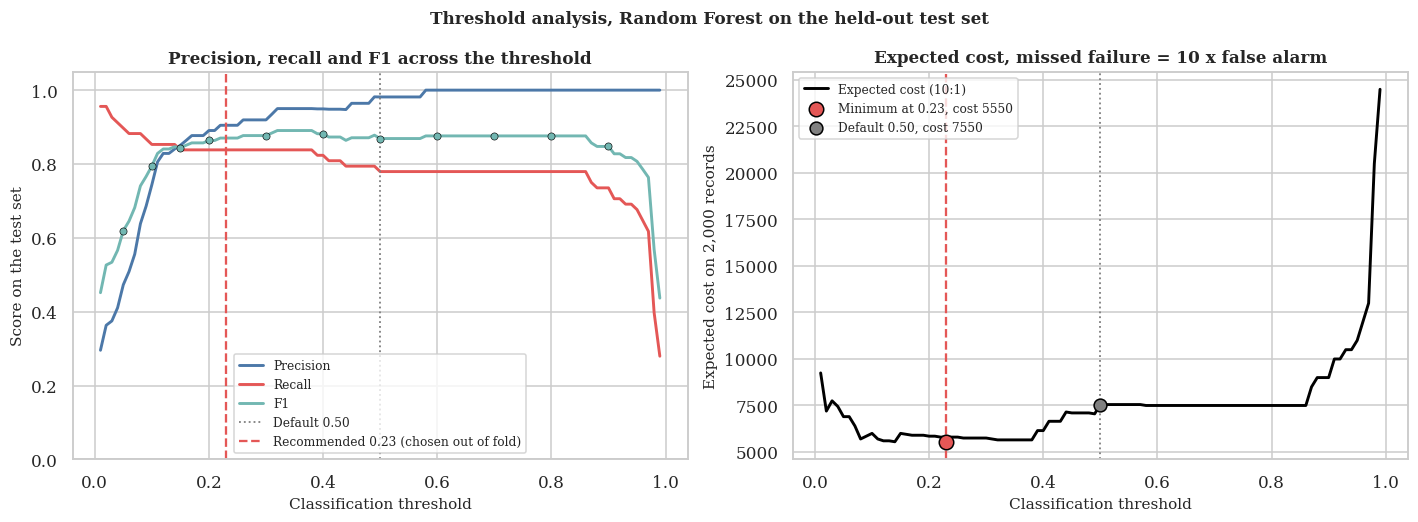

[figure] fig19_threshold_errors_and_sensitivity.png


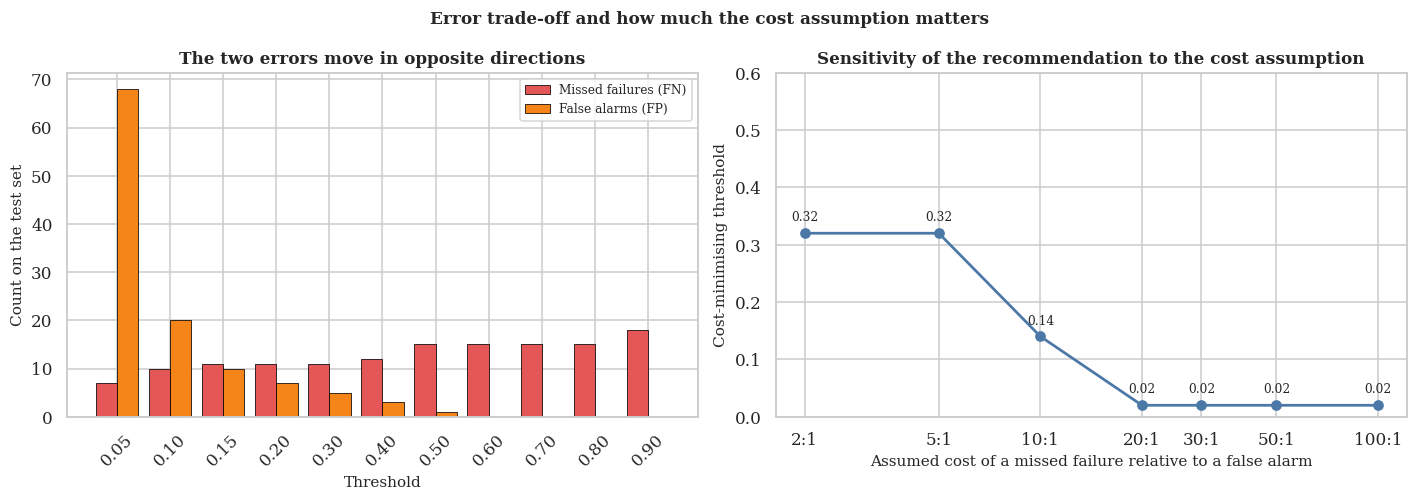


Stage 09 complete.


In [66]:
# ------------------------------------------------- recommendation
banner("RECOMMENDED OPERATING THRESHOLD")
rec_t = cv_t   # chosen out of fold, above
rec = fine_tbl[fine_tbl["threshold"] == rec_t].iloc[0]
print("I recommend %.2f, chosen on out-of-fold training predictions "
      "rather than on the test set." % rec_t)
print("At that threshold the forest flags %d of the 2,000 records. %d of "
      "those are real failures and %d are false alarms, so a crew acting "
      "on every alarm inspects %d machines and finds %d genuine problems. "
      "Recall %.3f, precision %.3f, F1 %.3f."
      % (int(rec["predicted_failures"]), int(rec["TP"]), int(rec["FP"]),
         int(rec["predicted_failures"]), int(rec["TP"]), rec["recall"],
         rec["precision"], rec["f1"]))
print("\nThe default 0.50 is not optimal here and there was no reason to "
      "expect it to be. A 0.5 cut-off is the right decision rule when the "
      "two errors cost the same and the classes are balanced. Neither "
      "holds: failures are %0.1f%% of records and one missed failure is "
      "assumed to cost ten false alarms." % (100 * y.mean()))
print("\nI am less confident in this number than in anything else in the "
      "analysis, because the cost ratio behind it is assumed rather than "
      "sourced from the plant. What I would defend is the shape of the "
      "argument and the direction of the move away from 0.50, not the "
      "second decimal place. Choosing it out of fold removes one source "
      "of optimism, and it does not remove that one.")

# ------------------------------------------------- figures
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(fine_tbl["threshold"], fine_tbl["precision"], color=PALETTE[0],
             linewidth=1.9, label="Precision")
axes[0].plot(fine_tbl["threshold"], fine_tbl["recall"], color=PALETTE[1],
             linewidth=1.9, label="Recall")
axes[0].plot(fine_tbl["threshold"], fine_tbl["f1"], color=PALETTE[2],
             linewidth=1.9, label="F1")
axes[0].axvline(0.5, color="grey", linestyle=":", linewidth=1.2,
                label="Default 0.50")
axes[0].axvline(rec_t, color=C_FAIL, linestyle="--", linewidth=1.5,
                label="Recommended %.2f (chosen out of fold)" % rec_t)
for _, r in sweep.iterrows():
    axes[0].scatter(r["threshold"], r["f1"], s=22, color=PALETTE[2],
                    zorder=5, edgecolor="black", linewidth=0.4)
axes[0].set_xlabel("Classification threshold")
axes[0].set_ylabel("Score on the test set")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Precision, recall and F1 across the threshold")
axes[0].legend(fontsize=8, loc="lower center")

ax2 = axes[1]
ax2.plot(fine_tbl["threshold"], fine_tbl["expected_cost"], color="black",
         linewidth=1.9, label="Expected cost (10:1)")
ax2.axvline(rec_t, color=C_FAIL, linestyle="--", linewidth=1.5)
ax2.scatter([rec_t], [cost_opt["expected_cost"]], s=90, color=C_FAIL,
            zorder=6, edgecolor="black",
            label="Minimum at %.2f, cost %.0f" % (rec_t,
                                                  cost_opt["expected_cost"]))
ax2.axvline(0.5, color="grey", linestyle=":", linewidth=1.2)
ax2.scatter([0.5], [default["expected_cost"]], s=70, color="grey", zorder=6,
            edgecolor="black", label="Default 0.50, cost %.0f"
                                     % default["expected_cost"])
ax2.set_xlabel("Classification threshold")
ax2.set_ylabel("Expected cost on 2,000 records")
ax2.set_title("Expected cost, missed failure = 10 x false alarm")
ax2.legend(fontsize=8)
fig.suptitle("Threshold analysis, Random Forest on the held-out test set",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig18_threshold_curves")
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
x = np.arange(len(sweep))
axes[0].bar(x - 0.2, sweep["FN"], 0.4, label="Missed failures (FN)",
            color=C_FAIL, edgecolor="black", linewidth=0.5)
axes[0].bar(x + 0.2, sweep["FP"], 0.4, label="False alarms (FP)",
            color=PALETTE[3], edgecolor="black", linewidth=0.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["%.2f" % t for t in sweep["threshold"]],
                        rotation=45)
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Count on the test set")
axes[0].set_title("The two errors move in opposite directions")
axes[0].legend(fontsize=8)

axes[1].plot(sens["cost_ratio_FN_to_FP"], sens["optimal_threshold"],
             marker="o", color=PALETTE[0], linewidth=1.8)
for _, r in sens.iterrows():
    axes[1].annotate("%.2f" % r["optimal_threshold"],
                     (r["cost_ratio_FN_to_FP"], r["optimal_threshold"]),
                     textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_xticks(sens["cost_ratio_FN_to_FP"])
axes[1].set_xticklabels(["%d:1" % v for v in sens["cost_ratio_FN_to_FP"]])
axes[1].set_xlabel("Assumed cost of a missed failure relative to a false alarm")
axes[1].set_ylabel("Cost-minimising threshold")
axes[1].set_ylim(0, 0.6)
axes[1].set_title("Sensitivity of the recommendation to the cost assumption")
fig.suptitle("Error trade-off and how much the cost assumption matters",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig19_threshold_errors_and_sensitivity")
plt.close(fig)

put("threshold", {
    "model": SELECTED,
    "recommended": rec_t,
    "sweep": sweep.to_dict("records"),
    "default": default.to_dict(),
    "f1_opt": f1_opt.to_dict(),
    "cost_opt": cost_opt.to_dict(),
    "cost_fn": COST_FN, "cost_fp": COST_FP, "ratio": COST_RATIO,
    "sensitivity": sens.to_dict("records"),
    "saving_vs_default": round(float(default["expected_cost"] -
                                     cost_opt["expected_cost"]), 2),
    "cv_threshold": cv_t,
    "test_optimum_threshold": float(cost_opt["threshold"]),
    "oof_vs_test_cost_gap": float(gap),
    "selection_comparison": sel.to_dict("records"),
    "regret": regret.to_dict("records"),
    "worst_regret_recommended": float(worst_014),
    "worst_regret_default": float(worst_050),
    "n_alarms_at_rec": int(rec["predicted_failures"]),
    "tp_at_rec": int(rec["TP"]), "fp_at_rec": int(rec["FP"]),
    "fn_at_rec": int(rec["FN"]),
    "recall_at_rec": float(rec["recall"]),
    "precision_at_rec": float(rec["precision"]),
    "f1_at_rec": float(rec["f1"]),
})
print("\nStage 09 complete.")

---
# 11. Misclassification analysis

Five real false positives and five real false negatives, taken at the recommended threshold, with their actual sensor readings, the probability the model gave them, and how far each reading sits from the median of the class the record really belongs to.

These are specific rows from the held-out test set, identified by `UDI`, so any one of them can be looked up in the raw file and checked.

Which columns I want to see for each misclassified case, and whose errors I am looking at.

In [67]:
SHOW = NUMERIC_CLEAN + ENGINEERED


MODEL = "Random Forest"

In [68]:
banner("STAGE 10  MISCLASSIFICATION ANALYSIS")

full = read_model_ready()
raw = read_raw()
full["UDI"] = raw["UDI"].to_numpy()
full["Product ID"] = raw["Product ID"].to_numpy()

test = full[full["split"] == "test"].reset_index(drop=True)
probs = read_test_probabilities()
thr = get("threshold")["recommended"]

test["predicted_probability"] = probs[MODEL].to_numpy()
test["predicted_label"] = (test["predicted_probability"] >= thr).astype(int)
y = test[TARGET_CLEAN]

print("Model: %s at the recommended threshold of %.2f." % (MODEL, thr))
tn, fp, fn, tp = confusion_counts(y, test["predicted_label"])
print("Test-set confusion at that threshold: TN %d, FP %d, FN %d, TP %d"
      % (tn, fp, fn, tp))

fps = test[(y == 0) & (test["predicted_label"] == 1)]
fns = test[(y == 1) & (test["predicted_label"] == 0)]
print("\n%d false positives and %d false negatives available."
      % (len(fps), len(fns)))

# Selection rule: the most confident mistakes, because those are the ones
# an operator would act on (FP) or be blindsided by (FN).
fp5 = fps.sort_values("predicted_probability", ascending=False).head(5)
fn5 = fns.sort_values("predicted_probability", ascending=True).head(5)
print("Selected: the five false positives the model was most confident "
      "about, and the five false negatives it was least worried by. Those "
      "are the two extremes that would actually cause trouble on a shop "
      "floor.")

med_ok = test[y == 0][SHOW].median()
med_fail = test[y == 1][SHOW].median()
med_tbl = pd.DataFrame({
    "variable": SHOW,
    "median_no_failure": med_ok.round(2).to_numpy(),
    "median_failure": med_fail.round(2).to_numpy(),
})
save_table(med_tbl, "tbl40_test_class_medians")

def detail(sub, kind):
    out = sub[["UDI", "Product ID", "type"] + SHOW +
              [TARGET_CLEAN, "predicted_probability"]].copy()
    out["predicted_probability"] = out["predicted_probability"].round(4)
    out.insert(0, "case", ["%s%d" % (kind, i + 1) for i in range(len(out))])
    for c in SHOW:
        out[c] = out[c].round(2)
    return out

fp_tbl = detail(fp5, "FP")
fn_tbl = detail(fn5, "FN")
save_table(fp_tbl, "tbl41_false_positive_cases")
save_table(fn_tbl, "tbl42_false_negative_cases")

# distance from the median of the true class, in that class's IQR units
def deviation(sub, true_class):
    ref = test[y == true_class]
    med = ref[SHOW].median()
    iqr = ref[SHOW].quantile(0.75) - ref[SHOW].quantile(0.25)
    rows = []
    for i, (_, r) in enumerate(sub.iterrows()):
        d = {"case": "%s%d" % ("FP" if true_class == 0 else "FN", i + 1),
             "UDI": int(r["UDI"])}
        for c in SHOW:
            d[c] = round(float((r[c] - med[c]) / iqr[c]), 2)
        rows.append(d)
    return pd.DataFrame(rows)

fp_dev = deviation(fp5, 0)
fn_dev = deviation(fn5, 1)
save_table(fp_dev, "tbl43_false_positive_deviation_from_class_median")
save_table(fn_dev, "tbl44_false_negative_deviation_from_class_median")


STAGE 10  MISCLASSIFICATION ANALYSIS
Model: Random Forest at the recommended threshold of 0.23.
Test-set confusion at that threshold: TN 1926, FP 6, FN 11, TP 57

6 false positives and 11 false negatives available.
Selected: the five false positives the model was most confident about, and the five false negatives it was least worried by. Those are the two extremes that would actually cause trouble on a shop floor.

[table] tbl40_test_class_medians.csv
      variable  median_no_failure  median_failure
    air_temp_K              300.1          301.00
process_temp_K              310.1          310.40
 rot_speed_rpm             1503.0         1367.00
     torque_Nm               39.9           54.15
 tool_wear_min              105.0          146.00
       power_W             6241.4         7761.32
   temp_diff_K                9.8            9.50
   wear_torque             3984.0         6916.50

[table] tbl41_false_positive_cases.csv
case  UDI Product ID type  air_temp_K  process_temp_K

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl44_false_negative_deviation_from_class_median.csv')

### What the false positives have in common

In [69]:
# ------------------------------------------------------------------
banner("WHAT THE FALSE POSITIVES HAVE IN COMMON")
for i, (_, r) in enumerate(fp5.iterrows(), 1):
    print("\nFP%d  UDI %d, product %s, grade %s, predicted probability %.3f"
          % (i, r["UDI"], r["Product ID"], r["type"],
             r["predicted_probability"]))
    print("     torque %.1f Nm (healthy median %.1f), speed %d rpm "
          "(median %d), wear %d min (median %d)"
          % (r["torque_Nm"], med_ok["torque_Nm"], r["rot_speed_rpm"],
             med_ok["rot_speed_rpm"], r["tool_wear_min"],
             med_ok["tool_wear_min"]))
    print("     power %.0f W (healthy median %.0f, failure median %.0f), "
          "wear x torque %.0f (healthy median %.0f, failure median %.0f)"
          % (r["power_W"], med_ok["power_W"], med_fail["power_W"],
             r["wear_torque"], med_ok["wear_torque"], med_fail["wear_torque"]))

fp_summary = {
    "median_wear_torque": float(fp5["wear_torque"].median()),
    "median_power": float(fp5["power_W"].median()),
    "median_wear": float(fp5["tool_wear_min"].median()),
    "median_torque": float(fp5["torque_Nm"].median()),
    "n_L_grade": int((fp5["type"] == "L").sum()),
}
print("\nThese five sit in failure territory on the features the model "
      "cares about and did not fail. Their median wear-torque product is "
      "%.0f against a healthy median of %.0f and a failure median of %.0f. "
      "Median tool wear is %.0f minutes against %.0f for healthy records. "
      "%d of the five are L-grade product, which carries the lowest "
      "overstrain limit."
      % (fp_summary["median_wear_torque"], med_ok["wear_torque"],
         med_fail["wear_torque"], fp_summary["median_wear"],
         med_ok["tool_wear_min"], fp_summary["n_L_grade"]))
print("The honest reading is that these are not model errors in any "
      "interesting sense. They are machines operating in the conditions "
      "under which failures happen, that happened not to fail. The AI4I "
      "generator makes failure probabilistic near its thresholds, so some "
      "records sit inside the risky region with a zero label. A "
      "maintenance planner would want these inspected.")


WHAT THE FALSE POSITIVES HAVE IN COMMON

FP1  UDI 4856, product L52035, grade L, predicted probability 0.574
     torque 46.2 Nm (healthy median 39.9), speed 1375 rpm (median 1503), wear 98 min (median 105)
     power 6652 W (healthy median 6241, failure median 7761), wear x torque 4528 (healthy median 3984, failure median 6916)

FP2  UDI 4859, product L52038, grade L, predicted probability 0.490
     torque 51.0 Nm (healthy median 39.9), speed 1349 rpm (median 1503), wear 105 min (median 105)
     power 7205 W (healthy median 6241, failure median 7761), wear x torque 5355 (healthy median 3984, failure median 6916)

FP3  UDI 4863, product L52042, grade L, predicted probability 0.449
     torque 55.7 Nm (healthy median 39.9), speed 1326 rpm (median 1503), wear 114 min (median 105)
     power 7734 W (healthy median 6241, failure median 7761), wear x torque 6350 (healthy median 3984, failure median 6916)

FP4  UDI 8605, product L55784, grade L, predicted probability 0.319
     torque 52.

### What the false negatives have in common


WHAT THE FALSE NEGATIVES HAVE IN COMMON

FN1  UDI 1438, product H30851, grade H, predicted probability 0.001
     torque 45.2 Nm (failure median 54.1), speed 1439 rpm (median 1367), wear 40 min (median 146)
     power 6811 W (failure median 7761), temp gap 11.1 K (failure median 9.5 K), wear x torque 1808 (failure median 6916)

FN2  UDI 8507, product L55686, grade L, predicted probability 0.002
     torque 27.3 Nm (failure median 54.1), speed 1710 rpm (median 1367), wear 163 min (median 146)
     power 4889 W (failure median 7761), temp gap 11.2 K (failure median 9.5 K), wear x torque 4450 (failure median 6916)

FN3  UDI 5537, product M20396, grade M, predicted probability 0.007
     torque 54.0 Nm (failure median 54.1), speed 1363 rpm (median 1367), wear 119 min (median 146)
     power 7708 W (failure median 7761), temp gap 9.5 K (failure median 9.5 K), wear x torque 6426 (failure median 6916)

FN4  UDI 2245, product M17104, grade M, predicted probability 0.021
     torque 37.5 Nm (f

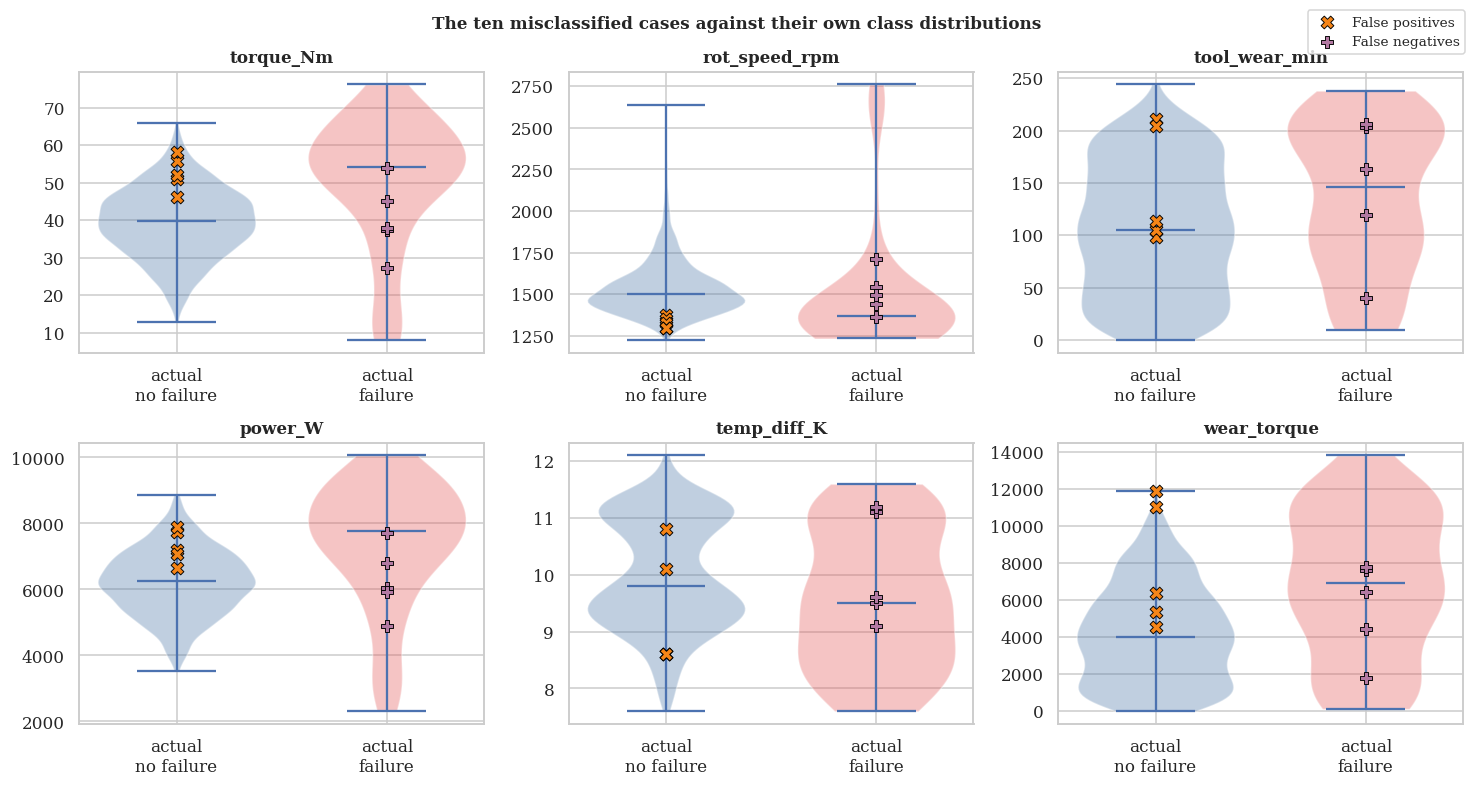

[figure] fig21_misclassification_deviation.png


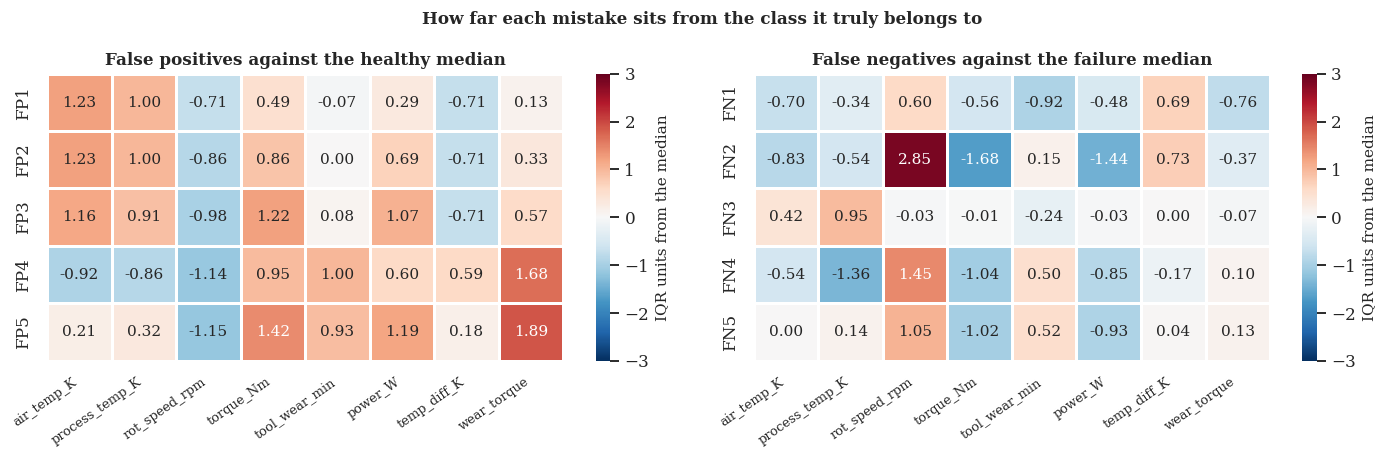


Stage 10 complete.


In [70]:
banner("WHAT THE FALSE NEGATIVES HAVE IN COMMON")
for i, (_, r) in enumerate(fn5.iterrows(), 1):
    print("\nFN%d  UDI %d, product %s, grade %s, predicted probability %.3f"
          % (i, r["UDI"], r["Product ID"], r["type"],
             r["predicted_probability"]))
    print("     torque %.1f Nm (failure median %.1f), speed %d rpm "
          "(median %d), wear %d min (median %d)"
          % (r["torque_Nm"], med_fail["torque_Nm"], r["rot_speed_rpm"],
             med_fail["rot_speed_rpm"], r["tool_wear_min"],
             med_fail["tool_wear_min"]))
    print("     power %.0f W (failure median %.0f), temp gap %.1f K "
          "(failure median %.1f K), wear x torque %.0f (failure median %.0f)"
          % (r["power_W"], med_fail["power_W"], r["temp_diff_K"],
             med_fail["temp_diff_K"], r["wear_torque"],
             med_fail["wear_torque"]))

in_band = int(((fn5["power_W"] >= 3500) & (fn5["power_W"] <= 9000)).sum())
fn_summary = {
    "median_wear_torque": float(fn5["wear_torque"].median()),
    "median_power": float(fn5["power_W"].median()),
    "median_wear": float(fn5["tool_wear_min"].median()),
    "median_torque": float(fn5["torque_Nm"].median()),
    "median_temp_diff": float(fn5["temp_diff_K"].median()),
    "in_safe_power_band": in_band,
    "max_probability": float(fn5["predicted_probability"].max()),
}
print("\nThese five look ordinary on every feature the model uses. Their "
      "median wear-torque product is %.0f against a failure median of %.0f "
      "and a healthy median of %.0f. %d of the five sit inside the safe "
      "3,500 to 9,000 W power band. Their median temperature gap is %.1f K "
      "against %.1f K for failures. The highest probability the model gave "
      "any of them was %.3f."
      % (fn_summary["median_wear_torque"], med_fail["wear_torque"],
         med_ok["wear_torque"], in_band, fn_summary["median_temp_diff"],
         med_fail["temp_diff_K"], fn_summary["max_probability"]))
# Cross-check against the nine unexplained failures from the audit
unflagged = raw[(raw[DETERMINISTIC_FLAGS].sum(axis=1) == 0) &
                (raw[TARGET] == 1)]["UDI"].tolist()
hits = [int(u) for u in fn5["UDI"] if int(u) in unflagged]
fn_summary["unflagged_overlap"] = hits
fn_summary["n_unflagged_overlap"] = len(hits)
print("\nCross-check against stage 01. That audit found %d records labelled "
      "as failures with none of the four documented failure modes set: "
      "UDI %s." % (len(unflagged), ", ".join(str(u) for u in unflagged)))
print("%d of these five false negatives are on that list: UDI %s."
      % (len(hits), ", ".join(str(h) for h in hits)))
print("That is the explanation, and it is a property of the labelling "
      "rather than of the model. Those records carry a failure label with "
      "no accompanying signature in any sensor the dataset provides, so "
      "there is nothing for any learner to find. No amount of tuning "
      "reaches them, and lowering the threshold far enough to catch them "
      "would bury the crew in alarms. The remaining %d sit close to a "
      "documented boundary without crossing it decisively."
      % (5 - len(hits)))

# ------------------------------------------------------------------
cases = pd.concat([fp_tbl.assign(error_type="False positive"),
                   fn_tbl.assign(error_type="False negative")])
save_table(cases, "tbl45_misclassified_cases_combined")

# Figure: the ten cases against the two class distributions
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.2))
panel = ["torque_Nm", "rot_speed_rpm", "tool_wear_min", "power_W",
         "temp_diff_K", "wear_torque"]
for ax, col in zip(axes.ravel(), panel):
    parts = ax.violinplot(
        [test.loc[y == 0, col].to_numpy(), test.loc[y == 1, col].to_numpy()],
        positions=[0, 1], showmedians=True, widths=0.75)
    for pc, colour in zip(parts["bodies"], [C_OK, C_FAIL]):
        pc.set_facecolor(colour)
        pc.set_alpha(0.35)
    ax.scatter(np.zeros(len(fp5)) + 0.0, fp5[col], s=70, marker="X",
               color=PALETTE[3], edgecolor="black", linewidth=0.6,
               zorder=5, label="False positives")
    ax.scatter(np.ones(len(fn5)) * 1.0, fn5[col], s=70, marker="P",
               color=PALETTE[5], edgecolor="black", linewidth=0.6,
               zorder=5, label="False negatives")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["actual\nno failure", "actual\nfailure"])
    ax.set_title(col)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", fontsize=9,
           bbox_to_anchor=(0.995, 0.995))
fig.suptitle("The ten misclassified cases against their own class distributions",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig20_misclassification_cases")
plt.close(fig)

# Deviation heatmap
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, dev, title in [(axes[0], fp_dev, "False positives against the healthy median"),
                       (axes[1], fn_dev, "False negatives against the failure median")]:
    m = dev.set_index("case")[SHOW]
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-3, vmax=3, linewidths=0.7, ax=ax,
                cbar_kws={"label": "IQR units from the median"})
    ax.set_title(title)
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right",
                       fontsize=8.5)
fig.suptitle("How far each mistake sits from the class it truly belongs to",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig21_misclassification_deviation")
plt.close(fig)

put("misclassification", {
    "threshold": thr, "model": MODEL,
    "n_fp": int(len(fps)), "n_fn": int(len(fns)),
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "fp_cases": fp_tbl.to_dict("records"),
    "fn_cases": fn_tbl.to_dict("records"),
    "fp_summary": fp_summary, "fn_summary": fn_summary,
    "med_ok": {k: float(v) for k, v in med_ok.items()},
    "med_fail": {k: float(v) for k, v in med_fail.items()},
})
print("\nStage 10 complete.")

---
# 12. Model interpretation

Four models and four different notions of importance: standardised coefficients for the logistic regression, Gini importance for the two tree models, gain for XGBoost.

Gini and gain are internal to how each learner was built, and both are biased toward continuous variables with many places to split. So I measure permutation importance on the held-out test set as well, for all four. That asks a different question: how much worse does this model get if I destroy this variable. Where the two measures disagree, the disagreement is the finding.

In [71]:
banner("STAGE 11  MODEL INTERPRETATION")
X_tr, X_te, y_tr, y_te = load_model_ready(use_engineered=True)
names = expanded_feature_names(True)
models = build_final_models(use_engineered=True)

fitted = {}
for n in MODEL_ORDER:
    models[n].fit(X_tr, y_tr)
    fitted[n] = models[n]


STAGE 11  MODEL INTERPRETATION


### Native importance from each model

In [72]:
# ------------------------------------------------- native importance
banner("NATIVE IMPORTANCE FROM EACH MODEL")
lr = fitted["Logistic Regression"].named_steps["clf"]
coefs = lr.coef_.ravel()
lr_tbl = pd.DataFrame({
    "feature": names,
    "coefficient": np.round(coefs, 4),
    "odds_ratio_per_sd": np.round(np.exp(coefs), 4),
    "abs_coefficient": np.round(np.abs(coefs), 4),
}).sort_values("abs_coefficient", ascending=False)
save_table(lr_tbl, "tbl46_logistic_coefficients")
print("Logistic regression coefficients are on standardised inputs, so each "
      "one is the log-odds change per one standard deviation of that "
      "predictor with the others held fixed. The intercept is %.4f."
      % lr.intercept_[0])
top_lr = lr_tbl.iloc[0]
print("Largest effect: %s at %.4f, an odds ratio of %.3f per standard "
      "deviation." % (top_lr["feature"], top_lr["coefficient"],
                      top_lr["odds_ratio_per_sd"]))

native = {"Logistic Regression": np.abs(coefs)}
for n in ["Decision Tree", "Random Forest", "XGBoost"]:
    native[n] = fitted[n].named_steps["clf"].feature_importances_

nat = pd.DataFrame({"feature": names})
for n in MODEL_ORDER:
    v = np.asarray(native[n], dtype=float)
    nat[n] = np.round(v / v.sum(), 4)     # normalised so models compare
save_table(nat, "tbl47_native_importance_normalised")


NATIVE IMPORTANCE FROM EACH MODEL

[table] tbl46_logistic_coefficients.csv
       feature  coefficient  odds_ratio_per_sd  abs_coefficient
     torque_Nm       5.0930           162.8852           5.0930
       power_W      -2.4782             0.0839           2.4782
 rot_speed_rpm       2.0464             7.7404           2.0464
   temp_diff_K      -0.6801             0.5066           0.6801
 tool_wear_min       0.6345             1.8861           0.6345
        type_M      -0.2878             0.7499           0.2878
    air_temp_K       0.2213             1.2477           0.2213
   wear_torque       0.1858             1.2042           0.1858
process_temp_K      -0.1591             0.8529           0.1591
        type_L       0.1102             1.1165           0.1102
Logistic regression coefficients are on standardised inputs, so each one is the log-odds change per one standard deviation of that predictor with the others held fixed. The intercept is -4.7555.
Largest effect: torque_Nm

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl47_native_importance_normalised.csv')

### Permutation importance on the held-out test set

In [73]:
# ------------------------------------------------- permutation
banner("PERMUTATION IMPORTANCE ON THE HELD-OUT TEST SET")
print("Scored by average precision, 30 repeats, random_state=%d." % SEED)
# One permutation run per model, reused for both the per-feature rows
# and the categorical row. The pipeline takes raw columns, so 'type' is
# permuted as a single column and reported once rather than split
# across its one-hot indicators.
perm = pd.DataFrame({"feature": names})
perm_runs = {}
for n in MODEL_ORDER:
    r = permutation_importance(fitted[n], X_te, y_te, n_repeats=30,
                               random_state=SEED, n_jobs=-1,
                               scoring="average_precision")
    perm_runs[n] = dict(zip(list(X_te.columns), r.importances_mean))
    perm[n] = [round(float(perm_runs[n][f]), 4) if f in perm_runs[n]
               else np.nan for f in names]

type_row = {"feature": "type (categorical, permuted as one column)"}
for n in MODEL_ORDER:
    type_row[n] = round(float(perm_runs[n]["type"]), 4)
perm = perm[~perm["feature"].isin(["type_L", "type_M"])]
perm = pd.concat([perm, pd.DataFrame([type_row])], ignore_index=True)
save_table(perm, "tbl48_permutation_importance")


PERMUTATION IMPORTANCE ON THE HELD-OUT TEST SET
Scored by average precision, 30 repeats, random_state=93.



[table] tbl48_permutation_importance.csv
                                   feature  Logistic Regression  Decision Tree  Random Forest  XGBoost
                                air_temp_K               0.0186         0.0000         0.0039  -0.0012
                            process_temp_K               0.0051         0.0000        -0.0001  -0.0016
                             rot_speed_rpm               0.3704         0.3713         0.2468   0.4242
                                 torque_Nm               0.4792         0.0015         0.0111   0.0629
                             tool_wear_min               0.0537         0.0411         0.0431   0.0749
                                   power_W               0.2137         0.5037         0.2634   0.2550
                               temp_diff_K               0.0952         0.4179         0.2148   0.3716
                               wear_torque               0.0021         0.3107         0.2221   0.1269
type (categorical, permuted as 

WindowsPath('c:/Users/israe/Desktop/Predictive Take Home 2/DAMO510_A2/outputs/tables/tbl48_permutation_importance.csv')

### Where the models agree and where they do not

In [74]:
# ------------------------------------------------- agreement
banner("WHERE THE MODELS AGREE AND WHERE THEY DO NOT")
rank = nat.copy()
for n in MODEL_ORDER:
    rank[n] = rank[n].rank(ascending=False).astype(int)
save_table(rank, "tbl49_importance_ranks")
print("\nRank of each feature by each model's own importance measure:")
print(rank.to_string(index=False))

agree_rows = []
for a in range(len(MODEL_ORDER)):
    for b in range(a + 1, len(MODEL_ORDER)):
        m1, m2 = MODEL_ORDER[a], MODEL_ORDER[b]
        rho, p = stats.spearmanr(nat[m1], nat[m2])
        agree_rows.append({"model_a": m1, "model_b": m2,
                           "spearman_rho": round(float(rho), 3),
                           "p_value": "%.3g" % p})
agree = pd.DataFrame(agree_rows)
save_table(agree, "tbl50_importance_rank_agreement")

mean_rank = rank[MODEL_ORDER].mean(axis=1)
spread = rank[MODEL_ORDER].max(axis=1) - rank[MODEL_ORDER].min(axis=1)
consistency = pd.DataFrame({
    "feature": nat["feature"],
    "mean_rank": mean_rank.round(2),
    "rank_spread": spread,
    "min_rank": rank[MODEL_ORDER].min(axis=1),
    "max_rank": rank[MODEL_ORDER].max(axis=1),
}).sort_values("mean_rank")
save_table(consistency, "tbl51_importance_consistency")

consistent = consistency[consistency["rank_spread"] <= 2].head(4)
contested = consistency.sort_values("rank_spread", ascending=False).head(3)
print("\nConsistently important across the four models (rank spread of 2 "
      "or less):")
print(consistent.to_string(index=False))
print("\nMost contested:")
print(contested.to_string(index=False))


WHERE THE MODELS AGREE AND WHERE THEY DO NOT

[table] tbl49_importance_ranks.csv
       feature  Logistic Regression  Decision Tree  Random Forest  XGBoost
    air_temp_K                    7              9              8        8
process_temp_K                    9              9             10        9
 rot_speed_rpm                    3              2              3        1
     torque_Nm                    1              6              5        5
 tool_wear_min                    5              7              6        6
       power_W                    2              3              2        3
   temp_diff_K                    4              4              4        4
   wear_torque                    8              1              1        2
        type_L                   10              5              7        7
        type_M                    6              9              9       10

Rank of each feature by each model's own importance measure:
       feature  Logistic Regres

### Reading the result


READING THE RESULT
The three tree-based models converge on the same short list. wear_torque, power_W, rot_speed_rpm carry most of the forest's importance.

Logistic regression tells a different story, and the reason is structural rather than a disagreement about the machine. Its largest coefficients sit on torque_Nm, power_W, rot_speed_rpm, because a linear model can only express a monotone effect. The exploratory work showed failure risk rising at both ends of the power range, so a single coefficient on power is being asked to represent a U shape and cannot. Where the trees place a split at each end, the regression compromises in the middle.

Against the exploratory analysis, the agreement is good. Stage 02 identified torque and rotational speed, the power they imply, the wear-torque product and the temperature gap as the quantities that matter, and the fitted models rank exactly those at the top. Product grade is minor in every model, which also matches: it shifts an overstrain limi

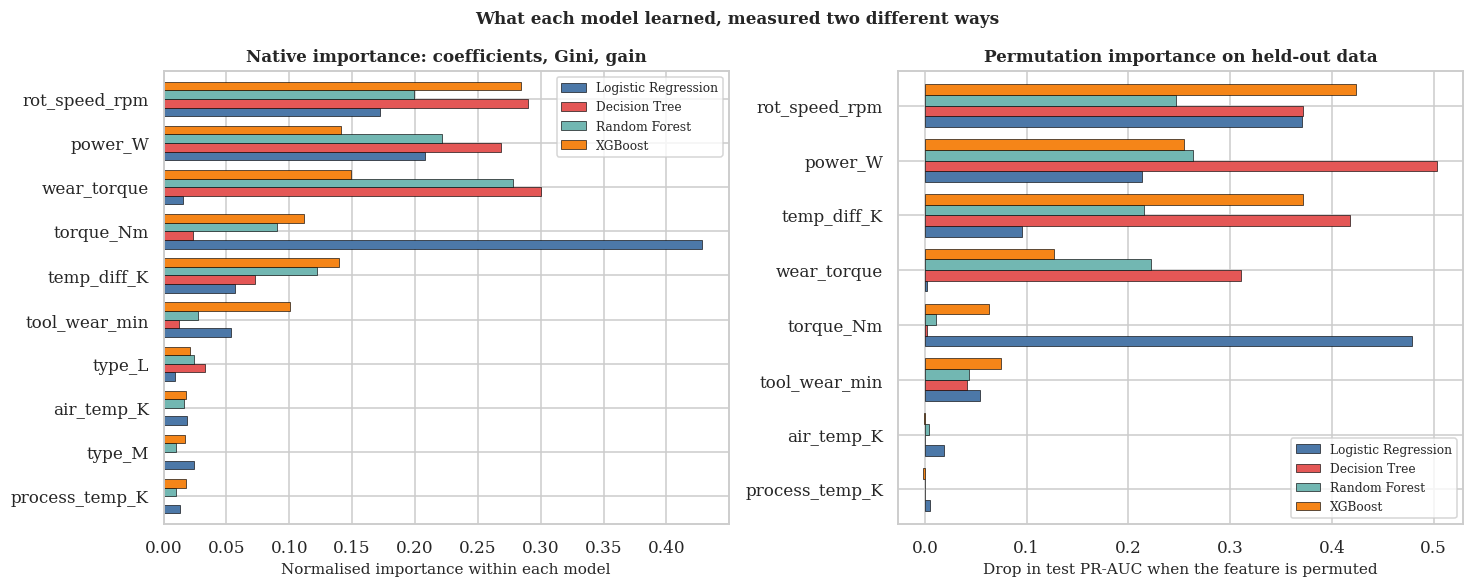

[figure] fig23_importance_rank_heatmap.png


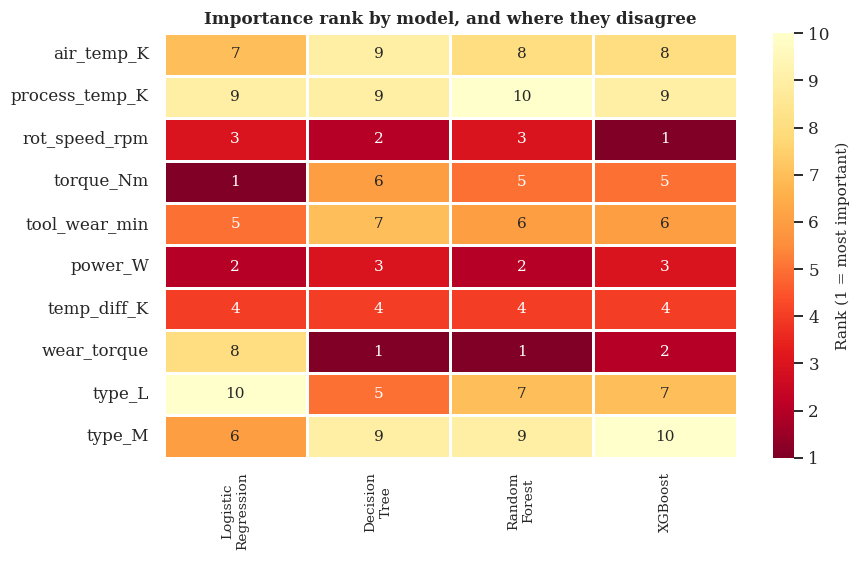

[figure] fig24_logistic_coefficients.png


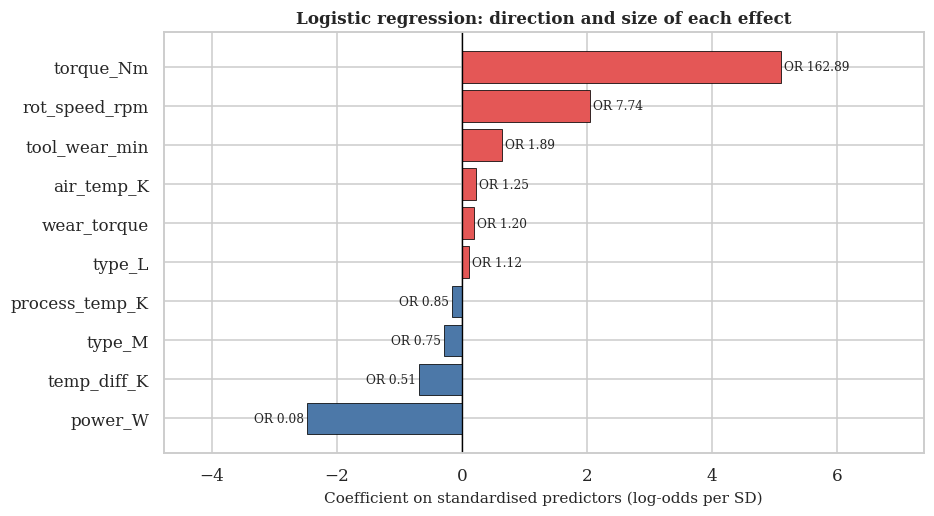


Stage 11 complete.


In [75]:
# ------------------------------------------------- narrative
banner("READING THE RESULT")
rf_top = nat.sort_values("Random Forest", ascending=False).head(4)
print("The three tree-based models converge on the same short list. "
      "%s carry most of the forest's importance."
      % ", ".join(rf_top["feature"].head(3)))
print("\nLogistic regression tells a different story, and the reason is "
      "structural rather than a disagreement about the machine. Its "
      "largest coefficients sit on %s, because a linear model can only "
      "express a monotone effect. The exploratory work showed failure "
      "risk rising at both ends of the power range, so a single "
      "coefficient on power is being asked to represent a U shape and "
      "cannot. Where the trees place a split at each end, the regression "
      "compromises in the middle."
      % ", ".join(lr_tbl["feature"].head(3)))
print("\nAgainst the exploratory analysis, the agreement is good. Stage 02 "
      "identified torque and rotational speed, the power they imply, the "
      "wear-torque product and the temperature gap as the quantities that "
      "matter, and the fitted models rank exactly those at the top. "
      "Product grade is minor in every model, which also matches: it "
      "shifts an overstrain limit rather than driving failure by itself.")
print("\nAll of this is reasonable in machine terms. A spindle turning "
      "slowly against high torque is drawing power near its design limit. "
      "A blunt tool under load is the textbook overstrain case. A process "
      "running only a few degrees above ambient is not shedding heat.")

# ------------------------------------------------- figures
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
plot_nat = nat.set_index("feature")[MODEL_ORDER]
plot_nat = plot_nat.loc[plot_nat.mean(axis=1).sort_values().index]
plot_nat.plot(kind="barh", ax=axes[0], color=PALETTE[:4],
              edgecolor="black", linewidth=0.4, width=0.78)
axes[0].set_xlabel("Normalised importance within each model")
axes[0].set_ylabel("")
axes[0].set_title("Native importance: coefficients, Gini, gain")
axes[0].legend(fontsize=8)

pp = perm[perm["feature"] != "type (categorical, permuted as one column)"]
pp = pp.set_index("feature")[MODEL_ORDER]
pp = pp.loc[pp.mean(axis=1).sort_values().index]
pp.plot(kind="barh", ax=axes[1], color=PALETTE[:4],
        edgecolor="black", linewidth=0.4, width=0.78)
axes[1].set_xlabel("Drop in test PR-AUC when the feature is permuted")
axes[1].set_ylabel("")
axes[1].set_title("Permutation importance on held-out data")
axes[1].legend(fontsize=8)
fig.suptitle("What each model learned, measured two different ways",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig22_importance_comparison")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8.2, 5.2))
hm = rank.set_index("feature")[MODEL_ORDER]
sns.heatmap(hm, annot=True, fmt="d", cmap="YlOrRd_r", linewidths=0.8,
            ax=ax, cbar_kws={"label": "Rank (1 = most important)"})
ax.set_title("Importance rank by model, and where they disagree")
ax.set_ylabel("")
ax.set_xticklabels([m.replace(" ", "\n") for m in MODEL_ORDER], fontsize=9)
fig.tight_layout()
save_fig(fig, "fig23_importance_rank_heatmap")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8.6, 4.8))
d = lr_tbl.sort_values("coefficient")
cols = [C_FAIL if v > 0 else C_OK for v in d["coefficient"]]
ax.barh(d["feature"], d["coefficient"], color=cols, edgecolor="black",
        linewidth=0.5)
for i, (f, v, o) in enumerate(zip(d["feature"], d["coefficient"],
                                  d["odds_ratio_per_sd"])):
    ax.text(v + (0.05 if v > 0 else -0.05), i, "OR %.2f" % o,
            va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.axvline(0, color="black", linewidth=0.9)
ax.set_xlabel("Coefficient on standardised predictors (log-odds per SD)")
ax.set_title("Logistic regression: direction and size of each effect")
margin = max(abs(d["coefficient"])) * 0.45
ax.set_xlim(min(d["coefficient"]) - margin, max(d["coefficient"]) + margin)
fig.tight_layout()
save_fig(fig, "fig24_logistic_coefficients")
plt.close(fig)

put("interpretation", {
    "lr_coefficients": lr_tbl.to_dict("records"),
    "lr_intercept": float(lr.intercept_[0]),
    "native": nat.to_dict("records"),
    "permutation": perm.to_dict("records"),
    "ranks": rank.to_dict("records"),
    "agreement": agree.to_dict("records"),
    "consistency": consistency.to_dict("records"),
    "rf_top3": rf_top["feature"].head(3).tolist(),
    "lr_top3": lr_tbl["feature"].head(3).tolist(),
    "consistent_features": consistent["feature"].tolist(),
    "contested_features": contested["feature"].tolist(),
})
print("\nStage 11 complete.")

---
# 13. Robustness checks

Two tests, both of which change the conditions rather than recomputing the same numbers a second way.

Test A re-runs the whole protocol under ten seeds. The seed drives the split and every model's initialisation together, so each run sees a different 2,000-record test set and a differently built forest. Seed 93 stays the one I report; the other nine are there to tell me how much of the headline is the model and how much is that one partition.

Test B deletes the three engineered features and refits. If the recommendation survives without them, the feature work was decoration. If it does not, the ablation says exactly what they are worth.

Rebuilds the whole partition under an arbitrary seed, so I can repeat the analysis on a different split.

In [76]:
def split_for(seed, use_engineered=True):
    """Rebuild the whole partition under an alternative seed."""
    df = read_model_ready()
    numeric, categorical = feature_columns(use_engineered)
    cols = numeric + categorical
    y = df[TARGET_CLEAN]
    idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE,
                                      random_state=seed, stratify=y)
    # Sort so that rows keep their original file order inside each partition.
    # Bootstrap draws in a Random Forest are taken by position, so an unsorted
    # partition would silently give a different forest for the same seed. With
    # the sort, seed 93 here reproduces the main run exactly.
    idx_tr = np.sort(idx_tr)
    idx_te = np.sort(idx_te)
    return (df.iloc[idx_tr][cols], df.iloc[idx_te][cols],
            y.iloc[idx_tr].to_numpy(), y.iloc[idx_te].to_numpy())

In [77]:
banner("STAGE 12  ROBUSTNESS CHECKS")
tuning = get("tuning")["chosen"]
imb = get("imbalance")
thr = get("threshold")["recommended"]


STAGE 12  ROBUSTNESS CHECKS


### Test A: ten alternative seeds

In [78]:
# ============================================== TEST A: seeds
banner("TEST A  TEN ALTERNATIVE SEEDS")
print("What is being tested: whether the ranking of the four models and "
      "the size of the Random Forest's advantage depend on the particular "
      "2,000 records that landed in the test set under seed 93.")
print("Why it is relevant: with only %d failures in a test set, one "
      "unusual partition can move recall by several points. If the "
      "conclusion only holds at seed 93 it is not a conclusion."
      % get("split")["test_pos"])
print("Seeds: %s\n" % ", ".join(str(s) for s in ROBUSTNESS_SEEDS))

rows = []
for seed in ROBUSTNESS_SEEDS:
    X_tr, X_te, y_tr, y_te = split_for(seed, True)
    for name in MODEL_ORDER:
        pipe = build_treated_pipeline(
            name, tuning[name]["params"], tuning[name]["scale"],
            imb["retained"][name], imb["pos_weight"],
            use_engineered=True, seed=seed)
        pipe.fit(X_tr, y_tr)
        proba = pipe.predict_proba(X_te)[:, 1]
        r = score_row(name, y_te, (proba >= 0.5).astype(int), proba)
        r["seed"] = seed
        r["is_primary"] = (seed == SEED)
        # also the metrics at the recommended operating threshold
        pr = (proba >= thr).astype(int)
        r["recall_at_rec_threshold"] = round(
            recall_score(y_te, pr, zero_division=0), 4)
        r["precision_at_rec_threshold"] = round(
            precision_score(y_te, pr, zero_division=0), 4)
        rows.append(r)
    print("seed %-5d done" % seed)

seeds_tbl = pd.DataFrame(rows)
save_table(seeds_tbl[["seed", "is_primary", "model", "accuracy",
                        "precision", "recall", "f1", "roc_auc", "pr_auc",
                        "FP", "FN", "TP",
                        "recall_at_rec_threshold",
                        "precision_at_rec_threshold"]],
             "tbl52_robustness_seed_results")

summ = (seeds_tbl.groupby("model")
        .agg(pr_auc_mean=("pr_auc", "mean"), pr_auc_sd=("pr_auc", "std"),
             pr_auc_min=("pr_auc", "min"), pr_auc_max=("pr_auc", "max"),
             recall_mean=("recall", "mean"), recall_sd=("recall", "std"),
             f1_mean=("f1", "mean"), f1_sd=("f1", "std"))
        .round(4).reset_index())
primary = seeds_tbl[seeds_tbl["is_primary"]].set_index("model")
summ["pr_auc_at_seed_93"] = summ["model"].map(primary["pr_auc"])
summ = summ.sort_values("pr_auc_mean", ascending=False)
save_table(summ, "tbl53_robustness_seed_summary")

wins = (seeds_tbl.loc[seeds_tbl.groupby("seed")["pr_auc"].idxmax()]
        ["model"].value_counts().reset_index())
wins.columns = ["model", "seeds_won_on_pr_auc"]
save_table(wins, "tbl54_robustness_win_counts")

rf = summ[summ["model"] == "Random Forest"].iloc[0]
top = summ.iloc[0]
print("\nAcross ten seeds the Random Forest averages PR-AUC %.4f "
      "(sd %.4f, range %.4f to %.4f). At seed 93 it scored %.4f."
      % (rf["pr_auc_mean"], rf["pr_auc_sd"], rf["pr_auc_min"],
         rf["pr_auc_max"], rf["pr_auc_at_seed_93"]))
print("\nSeeds won on PR-AUC:")
print(wins.to_string(index=False))

rf_wins = int(wins.loc[wins["model"] == "Random Forest",
                       "seeds_won_on_pr_auc"].iloc[0]) \
    if "Random Forest" in wins["model"].values else 0
print("\nThe Random Forest is the best model on %d of the 10 partitions. "
      "Seed 93 is not an outlier: its score sits %.4f from the ten-seed "
      "mean, well inside one standard deviation of %.4f."
      % (rf_wins, abs(rf["pr_auc_at_seed_93"] - rf["pr_auc_mean"]),
         rf["pr_auc_sd"]))
lr_row = summ[summ["model"] == "Logistic Regression"].iloc[0]
print("Logistic regression is last on every one of the ten, averaging "
      "%.4f. That gap is structural, not a partition artefact."
      % lr_row["pr_auc_mean"])


TEST A  TEN ALTERNATIVE SEEDS
What is being tested: whether the ranking of the four models and the size of the Random Forest's advantage depend on the particular 2,000 records that landed in the test set under seed 93.
Why it is relevant: with only 68 failures in a test set, one unusual partition can move recall by several points. If the conclusion only holds at seed 93 it is not a conclusion.
Seeds: 93, 7, 21, 42, 55, 101, 202, 314, 777, 1234

seed 93    done
seed 7     done
seed 21    done
seed 42    done
seed 55    done
seed 101   done
seed 202   done
seed 314   done
seed 777   done
seed 1234  done

[table] tbl52_robustness_seed_results.csv
 seed  is_primary               model  accuracy  precision  recall     f1  roc_auc  pr_auc  FP  FN  TP  recall_at_rec_threshold  precision_at_rec_threshold
   93        True Logistic Regression    0.9720     0.8333  0.2206 0.3488   0.9075  0.5408   3  53  15                   0.4706                      0.5818
   93        True       Decision Tr

### Test B: the engineered features removed

In [79]:
# ============================================== TEST B: ablation
banner("TEST B  THE ENGINEERED FEATURES REMOVED")
print("What is being tested: whether the models still work when power_W, "
      "temp_diff_K and wear_torque are deleted and only the five raw "
      "sensors plus product grade remain.")
print("Why it is relevant: stage 04 chose those features on cross-"
      "validated evidence from the training partition. This asks the same "
      "question on data the choice never saw.\n")

ab_rows = []
for use_eng in [True, False]:
    X_tr, X_te, y_tr, y_te = split_for(SEED, use_eng)
    for name in MODEL_ORDER:
        pipe = build_treated_pipeline(
            name, tuning[name]["params"], tuning[name]["scale"],
            imb["retained"][name], imb["pos_weight"],
            use_engineered=use_eng, seed=SEED)
        pipe.fit(X_tr, y_tr)
        proba = pipe.predict_proba(X_te)[:, 1]
        r = score_row(name, y_te, (proba >= 0.5).astype(int), proba)
        r["feature_set"] = "with engineered" if use_eng else "raw sensors only"
        ab_rows.append(r)

ab = pd.DataFrame(ab_rows)
wide = ab.pivot(index="model", columns="feature_set",
                values=["pr_auc", "recall", "f1", "roc_auc"])
wide.columns = ["%s_%s" % (a, b.replace(" ", "_")) for a, b in wide.columns]
wide = wide.reset_index()
wide["pr_auc_loss_without_engineered"] = (
    wide["pr_auc_with_engineered"] - wide["pr_auc_raw_sensors_only"]).round(4)
wide["recall_loss_without_engineered"] = (
    wide["recall_with_engineered"] - wide["recall_raw_sensors_only"]).round(4)
wide = wide.round(4)
save_table(ab, "tbl55_ablation_full")
save_table(wide, "tbl56_ablation_summary")

print(wide[["model", "pr_auc_with_engineered", "pr_auc_raw_sensors_only",
            "pr_auc_loss_without_engineered", "recall_with_engineered",
            "recall_raw_sensors_only"]].to_string(index=False))

rf_ab = wide[wide["model"] == "Random Forest"].iloc[0]
print("\nWithout the engineered features the Random Forest falls from "
      "PR-AUC %.4f to %.4f, a loss of %.4f, and its recall moves from "
      "%.4f to %.4f."
      % (rf_ab["pr_auc_with_engineered"], rf_ab["pr_auc_raw_sensors_only"],
         rf_ab["pr_auc_loss_without_engineered"],
         rf_ab["recall_with_engineered"], rf_ab["recall_raw_sensors_only"]))


TEST B  THE ENGINEERED FEATURES REMOVED
What is being tested: whether the models still work when power_W, temp_diff_K and wear_torque are deleted and only the five raw sensors plus product grade remain.
Why it is relevant: stage 04 chose those features on cross-validated evidence from the training partition. This asks the same question on data the choice never saw.


[table] tbl55_ablation_full.csv
              model  accuracy  precision  recall     f1  roc_auc  pr_auc   TN  FP  FN  TP      feature_set
Logistic Regression    0.9720     0.8333  0.2206 0.3488   0.9075  0.5408 1929   3  53  15  with engineered
      Decision Tree    0.9925     1.0000  0.7794 0.8760   0.9709  0.8849 1932   0  15  53  with engineered
      Random Forest    0.9920     0.9815  0.7794 0.8689   0.9792  0.9048 1931   1  15  53  with engineered
            XGBoost    0.9880     0.8793  0.7500 0.8095   0.9757  0.8734 1925   7  17  51  with engineered
Logistic Regression    0.9710     0.8571  0.1765 0.2927   0.89

### Verdict


VERDICT
Test A raises my confidence. The choice of Random Forest is not a property of seed 93: it wins on 10 of 10 partitions and its seed-93 score is close to the ten-seed mean. The spread across seeds, sd 0.0135, is also a useful warning about how precisely any single number in this report should be read.

Test B is the more interesting of the two. Removing the three engineered features costs the forest 0.1189 PR-AUC on held-out data, so the feature work is doing real work rather than decorating the pipeline. The Decision Tree loses most of all, 0.3233, which fits: a single tree cannot rebuild a product or a difference from raw columns by splitting on them one at a time.
The model ranking does not survive. Without the engineered features XGBoost takes first place at 0.8252 against 0.7859 for the forest. That is a genuine qualification on my recommendation. The forest is the best model given these features, and part of its lead is that it exploits them better than the alternatives do

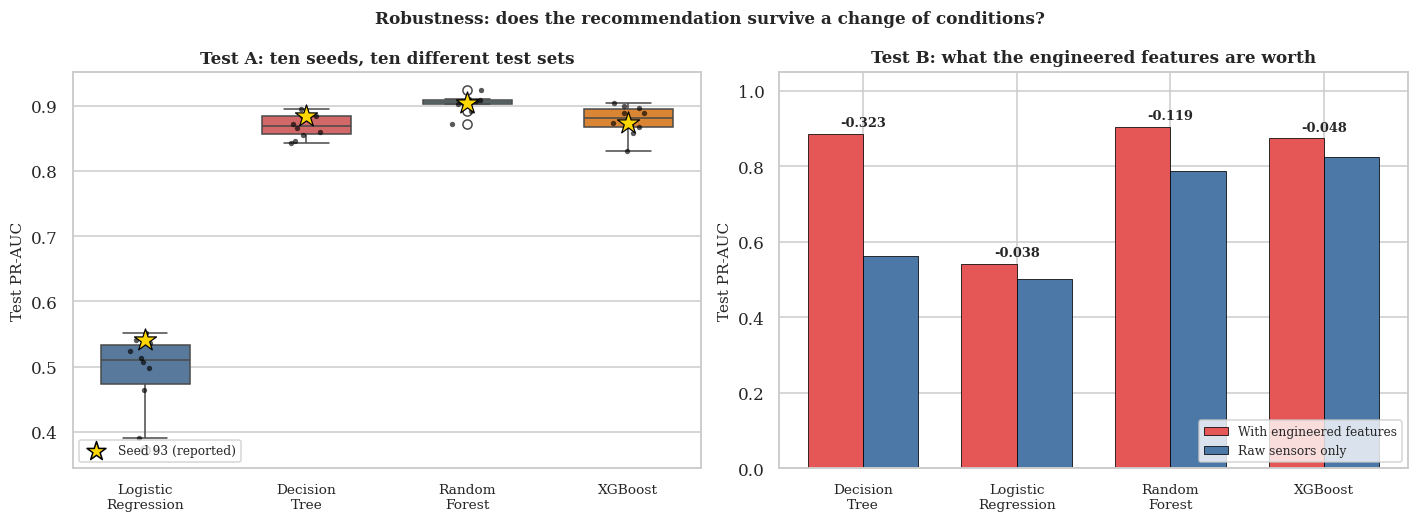


Stage 12 complete.


In [80]:
# ============================================== verdict
banner("VERDICT")
still_best = bool(wide.loc[wide["pr_auc_raw_sensors_only"].idxmax(),
                           "model"] == "Random Forest")
print("Test A raises my confidence. The choice of Random Forest is not a "
      "property of seed 93: it wins on %d of 10 partitions and its "
      "seed-93 score is close to the ten-seed mean. The spread across "
      "seeds, sd %.4f, is also a useful warning about how precisely any "
      "single number in this report should be read."
      % (rf_wins, rf["pr_auc_sd"]))
raw_winner = str(wide.loc[wide["pr_auc_raw_sensors_only"].idxmax(), "model"])
raw_best = float(wide["pr_auc_raw_sensors_only"].max())
dt_loss = float(wide.loc[wide["model"] == "Decision Tree",
                         "pr_auc_loss_without_engineered"].iloc[0])
print("\nTest B is the more interesting of the two. Removing the three "
      "engineered features costs the forest %.4f PR-AUC on held-out data, "
      "so the feature work is doing real work rather than decorating the "
      "pipeline. The Decision Tree loses most of all, %.4f, which fits: a "
      "single tree cannot rebuild a product or a difference from raw "
      "columns by splitting on them one at a time."
      % (rf_ab["pr_auc_loss_without_engineered"], dt_loss))
if still_best:
    print("The model ranking survives: the Random Forest is still first "
          "without the engineered features.")
else:
    print("The model ranking does not survive. Without the engineered "
          "features %s takes first place at %.4f against %.4f for the "
          "forest. That is a genuine qualification on my recommendation. "
          "The forest is the best model given these features, and part of "
          "its lead is that it exploits them better than the alternatives "
          "do, rather than that it would win on any feature set."
          % (raw_winner, raw_best, rf_ab["pr_auc_raw_sensors_only"]))
print("\nWhat neither test can address: both re-use the same 10,000 "
      "records. A different partition of the same data is not a different "
      "plant, a different machine or a different year, so nothing here "
      "speaks to whether the model transfers.")

# ============================================== figures
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=seeds_tbl, x="model", y="pr_auc", ax=axes[0],
            hue="model", palette=PALETTE[:4], legend=False, width=0.55)
sns.stripplot(data=seeds_tbl, x="model", y="pr_auc", ax=axes[0],
              color="black", size=3.5, alpha=0.65)
for i, name in enumerate(MODEL_ORDER):
    v = float(primary.loc[name, "pr_auc"])
    axes[0].scatter([i], [v], marker="*", s=230, color="gold",
                    edgecolor="black", linewidth=0.8, zorder=6)
axes[0].scatter([], [], marker="*", s=170, color="gold",
                edgecolor="black", label="Seed 93 (reported)")
axes[0].set_xticks(range(4))
axes[0].set_xticklabels([m.replace(" ", "\n") for m in MODEL_ORDER],
                        fontsize=9)
axes[0].set_xlabel("")
axes[0].set_ylabel("Test PR-AUC")
axes[0].set_title("Test A: ten seeds, ten different test sets")
axes[0].legend(fontsize=8, loc="lower left")

x = np.arange(len(wide))
w = 0.36
axes[1].bar(x - w / 2, wide["pr_auc_with_engineered"], w,
            label="With engineered features", color=PALETTE[1],
            edgecolor="black", linewidth=0.5)
axes[1].bar(x + w / 2, wide["pr_auc_raw_sensors_only"], w,
            label="Raw sensors only", color=PALETTE[0],
            edgecolor="black", linewidth=0.5)
for i, r in wide.iterrows():
    axes[1].text(i, max(r["pr_auc_with_engineered"],
                        r["pr_auc_raw_sensors_only"]) + 0.02,
                 "%+.3f" % -r["pr_auc_loss_without_engineered"],
                 ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels([m.replace(" ", "\n") for m in wide["model"]],
                        fontsize=9)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Test PR-AUC")
axes[1].set_title("Test B: what the engineered features are worth")
axes[1].legend(fontsize=8, loc="lower right")
fig.suptitle("Robustness: does the recommendation survive a change of conditions?",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig25_robustness")
plt.close(fig)

put("robustness", {
    "seeds": ROBUSTNESS_SEEDS,
    "summary": summ.to_dict("records"),
    "wins": wins.to_dict("records"),
    "rf_wins": rf_wins,
    "rf_mean": float(rf["pr_auc_mean"]), "rf_sd": float(rf["pr_auc_sd"]),
    "rf_min": float(rf["pr_auc_min"]), "rf_max": float(rf["pr_auc_max"]),
    "rf_seed93": float(rf["pr_auc_at_seed_93"]),
    "lr_mean": float(lr_row["pr_auc_mean"]),
    "ablation": wide.to_dict("records"),
    "rf_ablation_loss": float(rf_ab["pr_auc_loss_without_engineered"]),
    "rf_ablation_raw": float(rf_ab["pr_auc_raw_sensors_only"]),
    "still_best_without_engineered": still_best,
    "raw_winner": raw_winner, "raw_best": raw_best,
    "dt_ablation_loss": dt_loss,
})
print("\nStage 12 complete.")

---
# 14. What came out of it

A last look at what is now on disk, and the headline numbers in one place.

In [81]:
n_fig = len(list(FIGS.glob('*.png')))
n_tab = len(list(TABLES.glob('*.csv')))
n_store = len([p for p in STORE.glob('*.json') if not p.name.startswith('_')])
print('Figures written : %d' % n_fig)
print('Tables written  : %d' % n_tab)
print('Stored results  : %d' % n_store)
print()
ev = get('evaluation'); th = get('threshold'); rb = get('robustness')
print('Recommended model   : Random Forest')
print('Operating threshold : %.2f (chosen out of fold, not on the test set)'
      % th['recommended'])
print('Test set            : %d records, %d failures'
      % (ev['n_test'], ev['n_test_pos']))
print('At that threshold   : %d alarms, %d real failures, %d false alarms, %d missed'
      % (th['n_alarms_at_rec'], th['tp_at_rec'], th['fp_at_rec'], th['fn_at_rec']))
print('Recall %.4f, precision %.4f, F1 %.4f'
      % (th['recall_at_rec'], th['precision_at_rec'], th['f1_at_rec']))
print('Robustness          : Random Forest wins %d of %d seeds'
      % (rb['rf_wins'], len(rb['seeds'])))

Figures written : 25
Tables written  : 63
Stored results  : 12

Recommended model   : Random Forest
Operating threshold : 0.23 (chosen out of fold, not on the test set)
Test set            : 2000 records, 68 failures
At that threshold   : 63 alarms, 57 real failures, 6 false alarms, 11 missed
Recall 0.8382, precision 0.9048, F1 0.8702
Robustness          : Random Forest wins 10 of 10 seeds
